# Trend inflation from four US price measures with stochastic volatility

Inflation has a persistent part and a transitory part. The persistent part, **trend inflation**, is the rate that inflation returns to once the transitory shocks (an energy price spike, a pandemic quarter) have passed, and it is the number that a central bank and a bond investor care about. No price index measures it directly: each index measures the same underlying inflation with its own basket, formula and noise. In this notebook we estimate US trend inflation from four quarterly price measures, CPI, core CPI, PCE and core PCE, with one common random-walk trend, one transitory shock that moves all four measures at once, one transitory gap per measure, and **stochastic volatility**: the size of each of these shocks is itself a random walk, so the model can be quiet in the 1990s and loud in the 1970s and in 2021 to 2023.

The model is a multi-measure version of the unobserved components stochastic volatility (UCSV) model of [Stock and Watson (2007)](https://doi.org/10.1111/j.1538-4616.2007.00014.x), close in spirit to [Stock and Watson (2016)](https://doi.org/10.1162/REST_a_00608) and [Mertens (2016)](https://doi.org/10.1162/REST_a_00549). It fits in the building blocks of `numpyro_forecast` without new code: [`innovations`](../../reference/models.innovations.html) samples the standardized steps of every random walk, [`predict`](../../reference/models.predict.html) takes an observation noise whose scale changes over time, and [`backtest`](../../reference/evaluate.backtest.html) runs the rolling-origin evaluation. The data ship with the package as [`load_us_inflation`](../../reference/datasets.load_us_inflation.html).

The notebook has three parts:

- Estimation: the model, its priors, a prior predictive check, the fit with NUTS, the posterior of the trend, and a comparison with the same model without the common transitory shock.
- Forecast: core PCE inflation eight quarters ahead, with the stochastic volatility carried into the forecast bands.
- Evaluation: a rolling-origin backtest of three models against the random-walk benchmark of [Atkeson and Ohanian (2001)](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation), scored with the CRPS, the coverage and the MAE on core PCE.

The [VAR example](var.html) fits the same kind of quarterly US data with a vector autoregression; here the series share latent components instead of lagged cross effects.

## Prepare notebook

In [1]:
import warnings

# preliz warns at import time when PyMC is not installed; this example does not use PyMC.
warnings.filterwarnings("ignore", message="PyMC not installed", category=UserWarning)

from functools import partial
from time import perf_counter

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import preliz as pz
import xarray as xr
from arviz_plots import PlotCollection
from jax import random
from jax.scipy.stats import norm
from matplotlib.artist import Artist
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
from numpyro.infer import MCMC, NUTS, Predictive

from numpyro_forecast import (
    BacktestResult,
    Horizon,
    backtest,
    eval_crps,
    eval_mae,
    forecast,
    innovations,
    predict,
    predictions_to_datatree,
    to_datatree,
)
from numpyro_forecast.datasets import load_us_inflation
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import Array, ForecastFn, ForecastModel, Metric, ModelFactory

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [12, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
# arviz-plots warns whenever `aes` maps `alpha`, even to `["prob"]` as the plots below do.
warnings.filterwarnings(
    "ignore", message="When multiple credible intervals are plotted", category=UserWarning
)

numpyro.set_host_device_count(n=4)
rng_key = random.PRNGKey(seed=42)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## Read data

The four series are the monthly, seasonally adjusted price indexes `CPIAUCSL`, `CPILFESL`, `PCEPI` and `PCEPILFE` from [FRED](https://fred.stlouisfed.org/), averaged over each quarter and turned into **annualized quarterly log inflation** in percent,

$$
\pi_{t, m} = 400 \, (\log P_{t, m} - \log P_{t-1, m}),
$$

where $P_{t, m}$ is the quarterly average level of measure $m$ in quarter $t$. The sample runs from 1959Q2 to 2026Q3, and the values are the revised data as published on 2026-11-08, not the real-time vintages a forecaster had at each date.

The 2025 federal government shutdown left two marks on the data. The BLS published no CPI for October 2025, so that month of the two CPI series is the geometric mean of September and November 2025, the approximation the BLS uses for that month in its seasonal adjustment. The BLS also carried the October rents forward, so the rent and owners' equivalent rent indexes count no rent change for October until the April 2026 index catches up ([BLS shutdown FAQ](https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi-faq.htm), questions 2, 8 and 12). The PCE price indexes are built from CPI components: for October 2025 the BEA used the same geometric mean of the September and November CPIs ([BEA release of January 22, 2026](https://www.bea.gov/news/2026/personal-income-and-outlays-october-and-november-2025)), and the housing prices of PCE come from the CPI rent indexes, so PCE and core PCE carry both marks too.

Two conventions of the loader matter below:

- Core PCE is the last column. It is the measure the Federal Reserve targets, it is the reference measure of the model (its offset is zero, so the trend is on the core PCE scale) and it is the series we score in the evaluation.
- Time is at axis $-2$ and the measures at axis $-1$, the package layout, so the `(quarters, measures)` array is the `data` of every model call.

In [2]:
inflation = load_us_inflation()
rates = inflation.rates  # (quarters, measures), core PCE last
dates = inflation.dates  # first day of each quarter
num_quarters, num_measures = rates.shape
measure_labels = ("CPI", "core CPI", "PCE", "core PCE")

assert inflation.names == ("cpi", "core_cpi", "pce", "core_pce")
assert rates.shape == (270, 4)

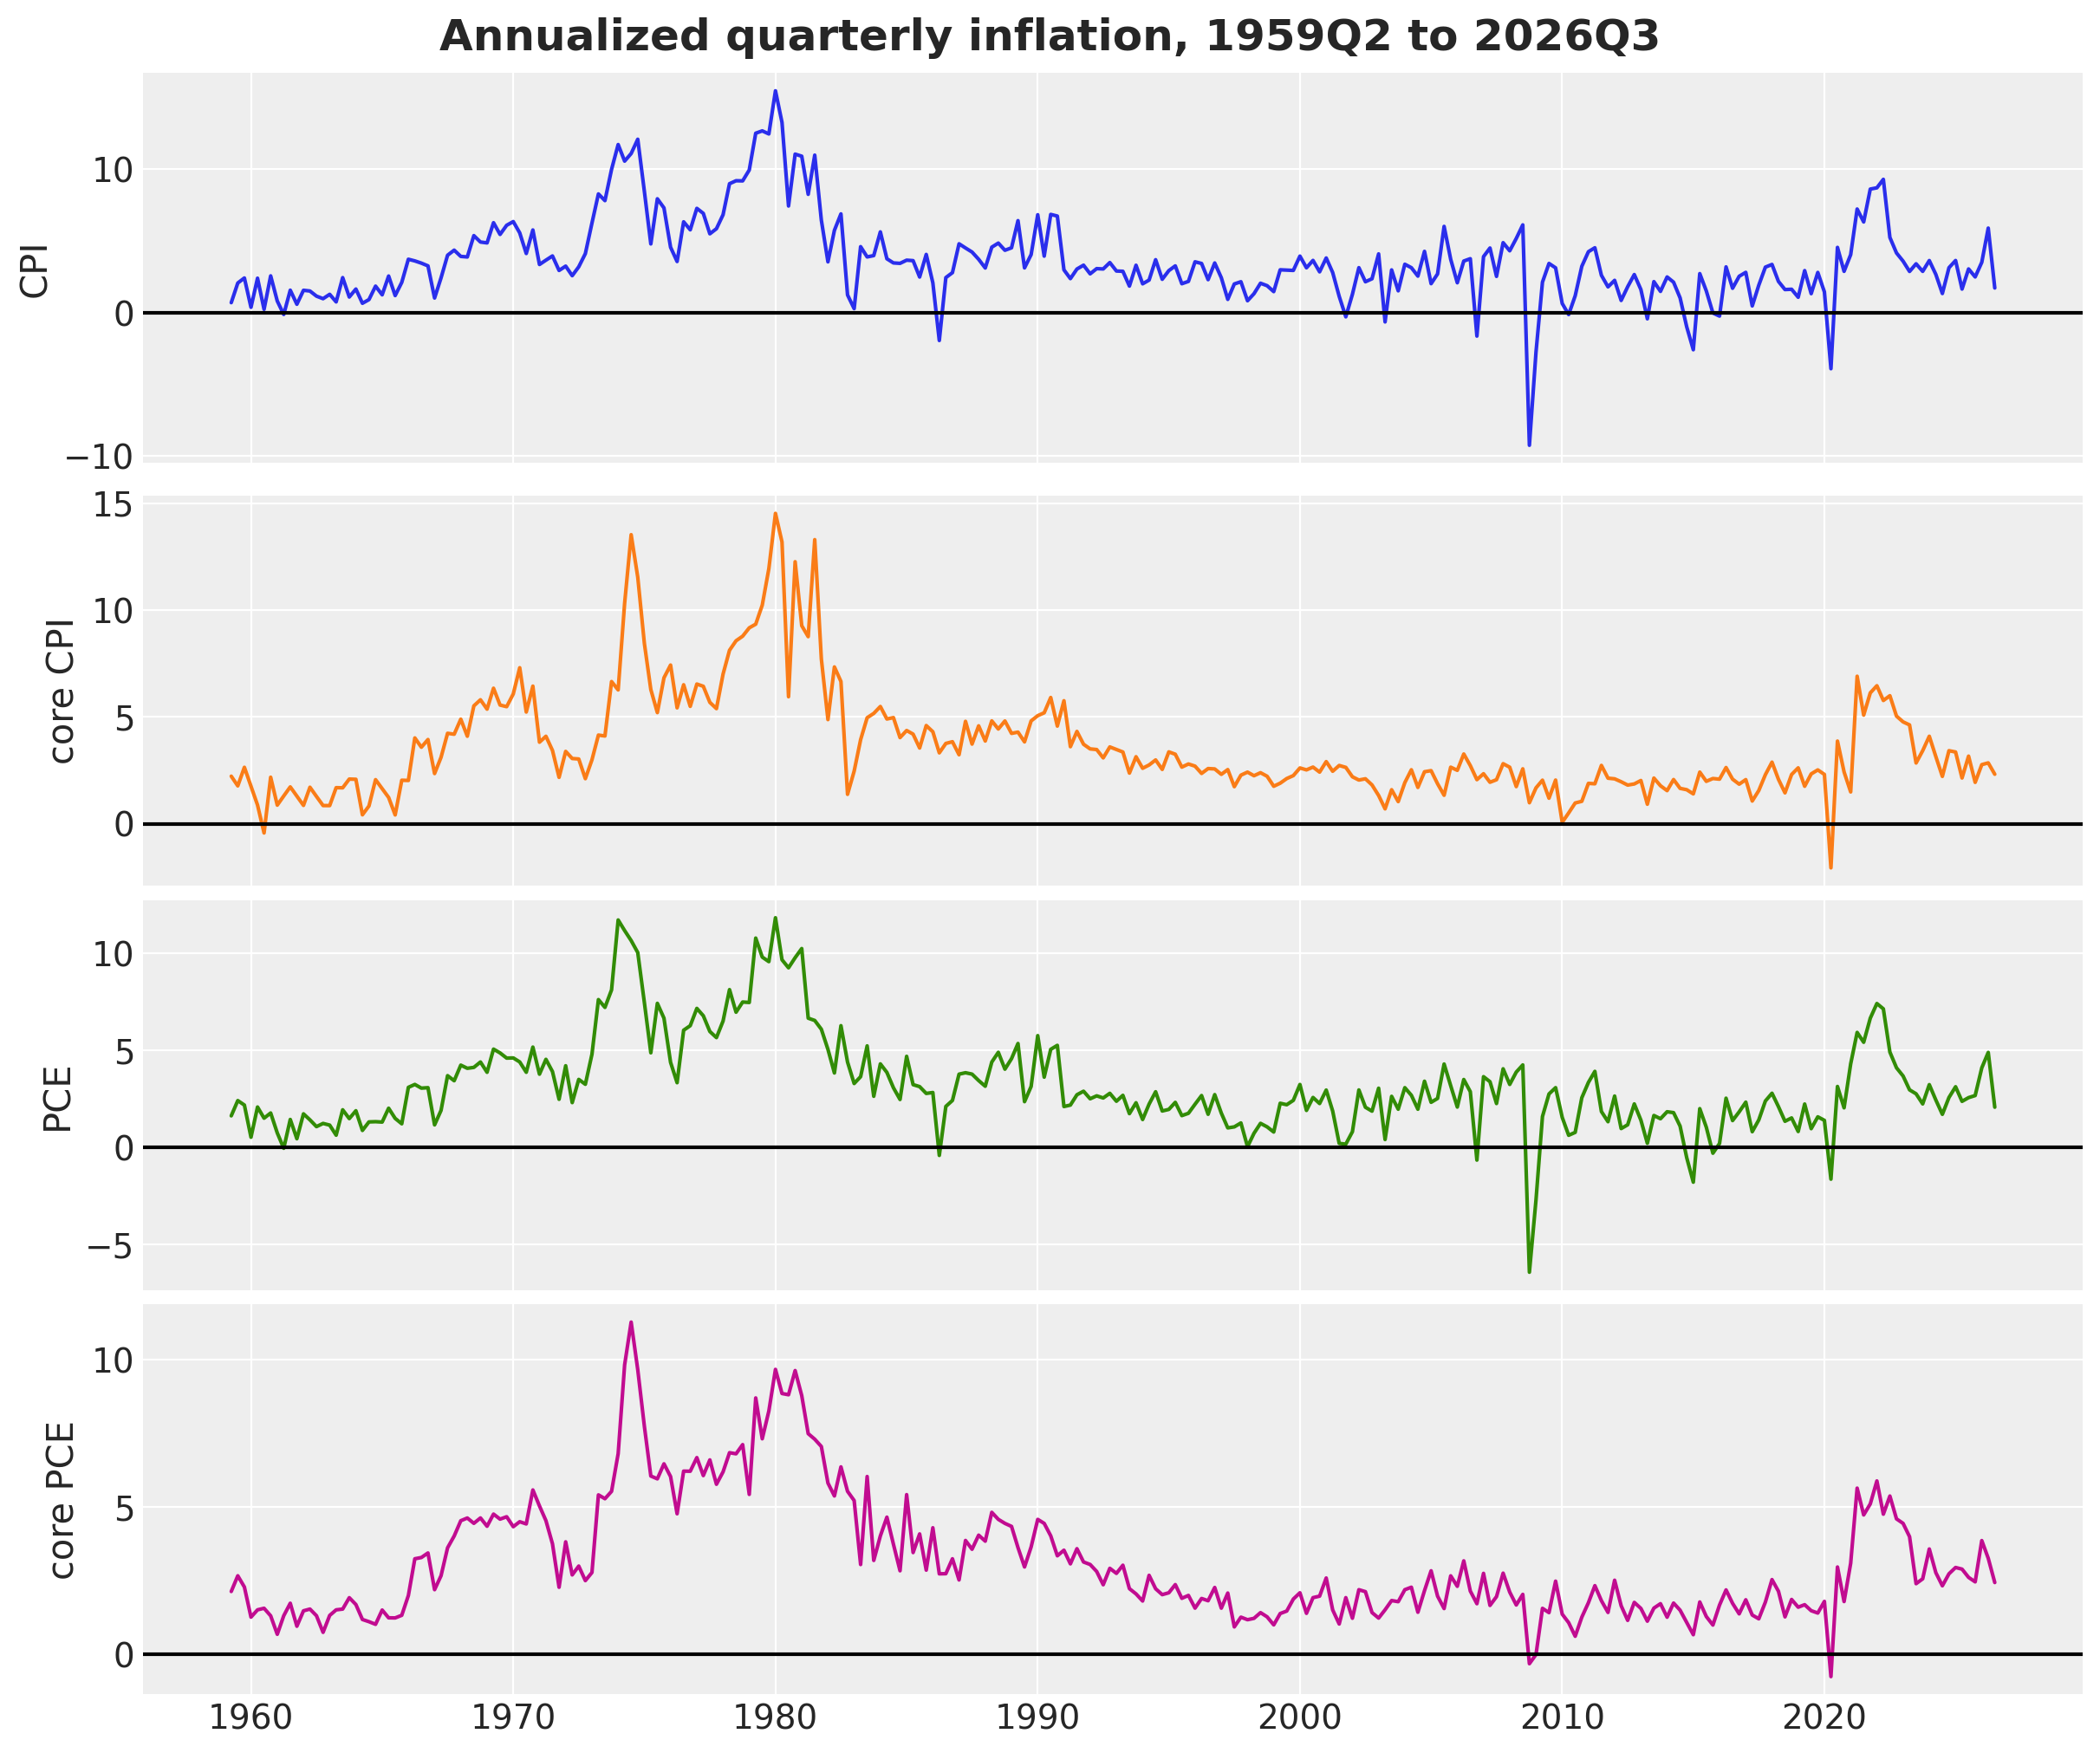

In [3]:
TITLE = {"fontsize": 18, "fontweight": "bold"}

fig, axes = plt.subplots(nrows=num_measures, sharex=True, figsize=(12, 10), layout="constrained")

for ax, label, color, series in zip(
    axes, measure_labels, ("C0", "C1", "C2", "C3"), rates.T, strict=True
):
    ax.plot(dates, series, color=color)
    ax.axhline(0.0, color="black")
    ax.set(ylabel=label)

locator = mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle("Annualized quarterly inflation, 1959Q2 to 2026Q3", **TITLE);

The four series move together, with different amplitudes:

- The 1970s have two peaks, around 1974 and 1980, where every measure reaches $10\%$ at least once: CPI peaks at $15.5\%$ in 1980Q1 and core PCE at $11.3\%$ in 1974Q3.
- The Great Moderation, from 1985 to 2007, keeps the four measures at an average of $2.5\%$ to $3.0\%$, and the core measures are visibly smoother than the headline ones.
- 2008Q4 is the quarter where the headline measures fall far below zero as oil prices collapse, CPI to $-9.3\%$ and PCE to $-6.4\%$, while the core measures stay near zero.
- 2021 to 2023 is the surge after the pandemic, with CPI at $9.3\%$ in 2022Q2 and core PCE at $5.9\%$ in 2022Q1. Before it, in 2020Q2, all four measures fell in the same quarter, CPI to $-3.9\%$, core CPI to $-2.1\%$, PCE to $-1.6\%$ and core PCE to $-0.8\%$, and all four rebounded in 2020Q3.

From the mid 1980s on, the headline measures (CPI, PCE) swing more from quarter to quarter than their core counterparts, because food and energy prices are in their baskets, and CPI runs above PCE on average, because of the formula and weight differences between the two indexes. The wedge has not been constant: before 1983 both CPI measures priced owner-occupied housing through mortgage interest costs, which is one reason core CPI reached $14.5\%$ in 1980Q1 while core PCE reached $9.7\%$. The model below has one parameter for the average wedge of each measure (the offset), one time-varying scale per measure for its noise, and one shock for quarters like 2020Q2 that move all four measures at once.

## Evaluation metrics and the benchmark

The evaluation scores forecasts of core PCE inflation at horizons of one to eight quarters, in two forms: the eight quarterly rates themselves and the **4-quarter average**, the mean of the first four quarterly rates of the horizon, which is the quantity policy discussions use. The mean of four annualized quarterly log rates is exactly the annual log change, $100 \, (\log P_{t+4} - \log P_t)$, so the second form is the one-year inflation rate from the forecast origin.

We use three metrics:

- The **continuous ranked probability score** (CRPS) of [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437) scores the whole forecast distribution. For a forecast with draws $X, X'$ and a realized value $y$ it is $\text{E}|X - y| - \tfrac{1}{2} \text{E}|X - X'|$, in percentage points: the first term is the mean distance of the draws from the outcome, the second subtracts half the mean distance between two draws, and a point forecast with no spread scores its absolute error. Lower is better.
- The **coverage** of the central $50\%$ and $94\%$ intervals is the share of realized quarters inside the interval; a calibrated forecast lands at the nominal level.
- The **mean absolute error** (MAE) of the forecast median is the point-forecast score we can compare with a benchmark that has no distribution.

The benchmark is the random-walk forecast of [Atkeson and Ohanian (2001)](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation): the average inflation of the last four quarters before the origin, held flat over the horizon. It is a point forecast with no model, and it is the standard hard benchmark in the inflation forecasting literature because few models beat it on the 4-quarter average. We score it with the MAE on both forms of the target.

## Model specification

For quarter $t = 1, \dots, T$ and measure $m = 1, \dots, M$ with $M = 4$, the model is

$$
\begin{align*}
\pi_{t, m} &= \alpha_m + \tau_t + c_t + \varepsilon_{t, m}, & \varepsilon_{t, m} &\sim \text{Normal}\left(0, \sigma_{\min} + \exp(g_{t, m} / 2)\right), \\
\tau_t &= \tau_{t-1} + \exp(h_t / 2) \, z_t, & z_t &\sim \text{Normal}(0, 1), \\
c_t &= \exp(q_t / 2) \, w_t, & w_t &\sim \text{Normal}(0, 1), \\
h_t &= h_{t-1} + \gamma \, u_t, & u_t &\sim \text{Normal}(0, 1), \\
q_t &= q_{t-1} + \gamma \, r_t, & r_t &\sim \text{Normal}(0, 1), \\
g_{t, m} &= g_{t-1, m} + \gamma \, v_{t, m}, & v_{t, m} &\sim \text{Normal}(0, 1),
\end{align*}
$$

where

- $\pi_{t, m}$ is the annualized quarterly inflation of measure $m$,
- $\tau_t$ is **trend inflation**, a random walk common to all measures,
- $c_t$ is the **common transitory shock**, white noise that moves all four measures by the same amount in quarter $t$ and is gone the next quarter,
- $\alpha_m$ is the **offset** of measure $m$ relative to core PCE, with $\alpha_M = 0$ for core PCE, which identifies the level of the trend (without it, a constant could move between the trend and the offsets),
- $\varepsilon_{t, m}$ is the transitory **gap** of measure $m$, independent across measures and over time given its scale,
- $\sigma_{\min} = 0.1$ percentage points is a fixed **floor** under every gap volatility,
- $h_t$, $q_t$ and $g_{t, m}$ are the **log-variances** of the trend shock, of the common transitory shock and of each gap, random walks with the common **vol-of-vol** $\gamma$, the standard deviation of their steps.

The common transitory shock is there because the transitory parts of the four measures move together: in 2020Q2 all four fell at once and rebounded the next quarter. Without $c_t$, independent gaps cannot produce such a quarter, so the model has to put it into the trend; the section *The common transitory shock* shows what that does. The shock has the same loading, one, on every measure. The floor $\sigma_{\min}$ keeps every gap volatility away from zero. Near zero, the likelihood pins the trend to one measure, the posterior narrows into a funnel, and NUTS reports divergent transitions. Both choices come from fits that this notebook does not re-run; the last figure of *Sensitivity to the vol-of-vol* collects them.

The random walks are written in non-centered form: the model samples the standardized steps $z_t$, $u_t$, $r_t$ and $v_{t, m}$ and builds the paths with a cumulative sum, and it builds the common shock as $\exp(q_t / 2) \, w_t$ from the unit normals $w_t$. Every latent path is a deterministic function of unit normals.

The priors are

$$
\begin{align*}
\alpha_m &\sim \text{Normal}(0, 1), \quad m < M, \\
\tau_0 &\sim \text{Normal}(3, 2), \\
h_0 &\sim \text{Normal}(-1.5, 1), \\
q_0 &\sim \text{Normal}(0, 1), \\
g_{0, m} &\sim \text{Normal}(0, 1), \\
\gamma &= 0.1 \quad \text{(fixed)}.
\end{align*}
$$

On the scale of the data, where a typical quarter of core inflation sits between $1\%$ and $5\%$:

- $\tau_0 \sim \text{Normal}(3, 2)$ puts the trend at the start of the sample between $-1\%$ and $7\%$ with $95\%$ probability, which covers the late 1950s.
- $h_0 = -1.5$ is a trend shock with standard deviation $\exp(-0.75) \approx 0.47$ percentage points per quarter, and the prior standard deviation of $1$ on $h_0$ lets that scale range from about $0.3$ to $0.8$ within one standard deviation.
- $q_0 = 0$ and $g_{0, m} = 0$ are a common shock and a gap with a standard deviation of $1$ percentage point (plus the floor for the gap), the right order for the core measures; the headline measures move up from there through $g_{t, m}$.
- $\alpha_m \sim \text{Normal}(0, 1)$ allows offsets of about $\pm 2$ percentage points, which is wide for the CPI to PCE wedge of a few tenths.
- $\gamma = 0.1$ is fixed, as in Stock and Watson (2007). They write the variance of the log-variance steps as $\gamma$ and set it to $0.2$, a standard deviation of about $0.45$; here $\gamma$ is the standard deviation itself, and $0.1$ is smaller. After $t$ quarters the log-variance has prior standard deviation $\gamma \sqrt{t}$, about $1.6$ for $t = 270$, so a volatility can drift by a factor of $\exp(0.82) \approx 2.3$ in either direction over the sample within one standard deviation. The fourth panel of the prior figure plots this band for three values of $\gamma$. The section *Sensitivity to the vol-of-vol* refits the model with larger values and with a learned $\gamma$.

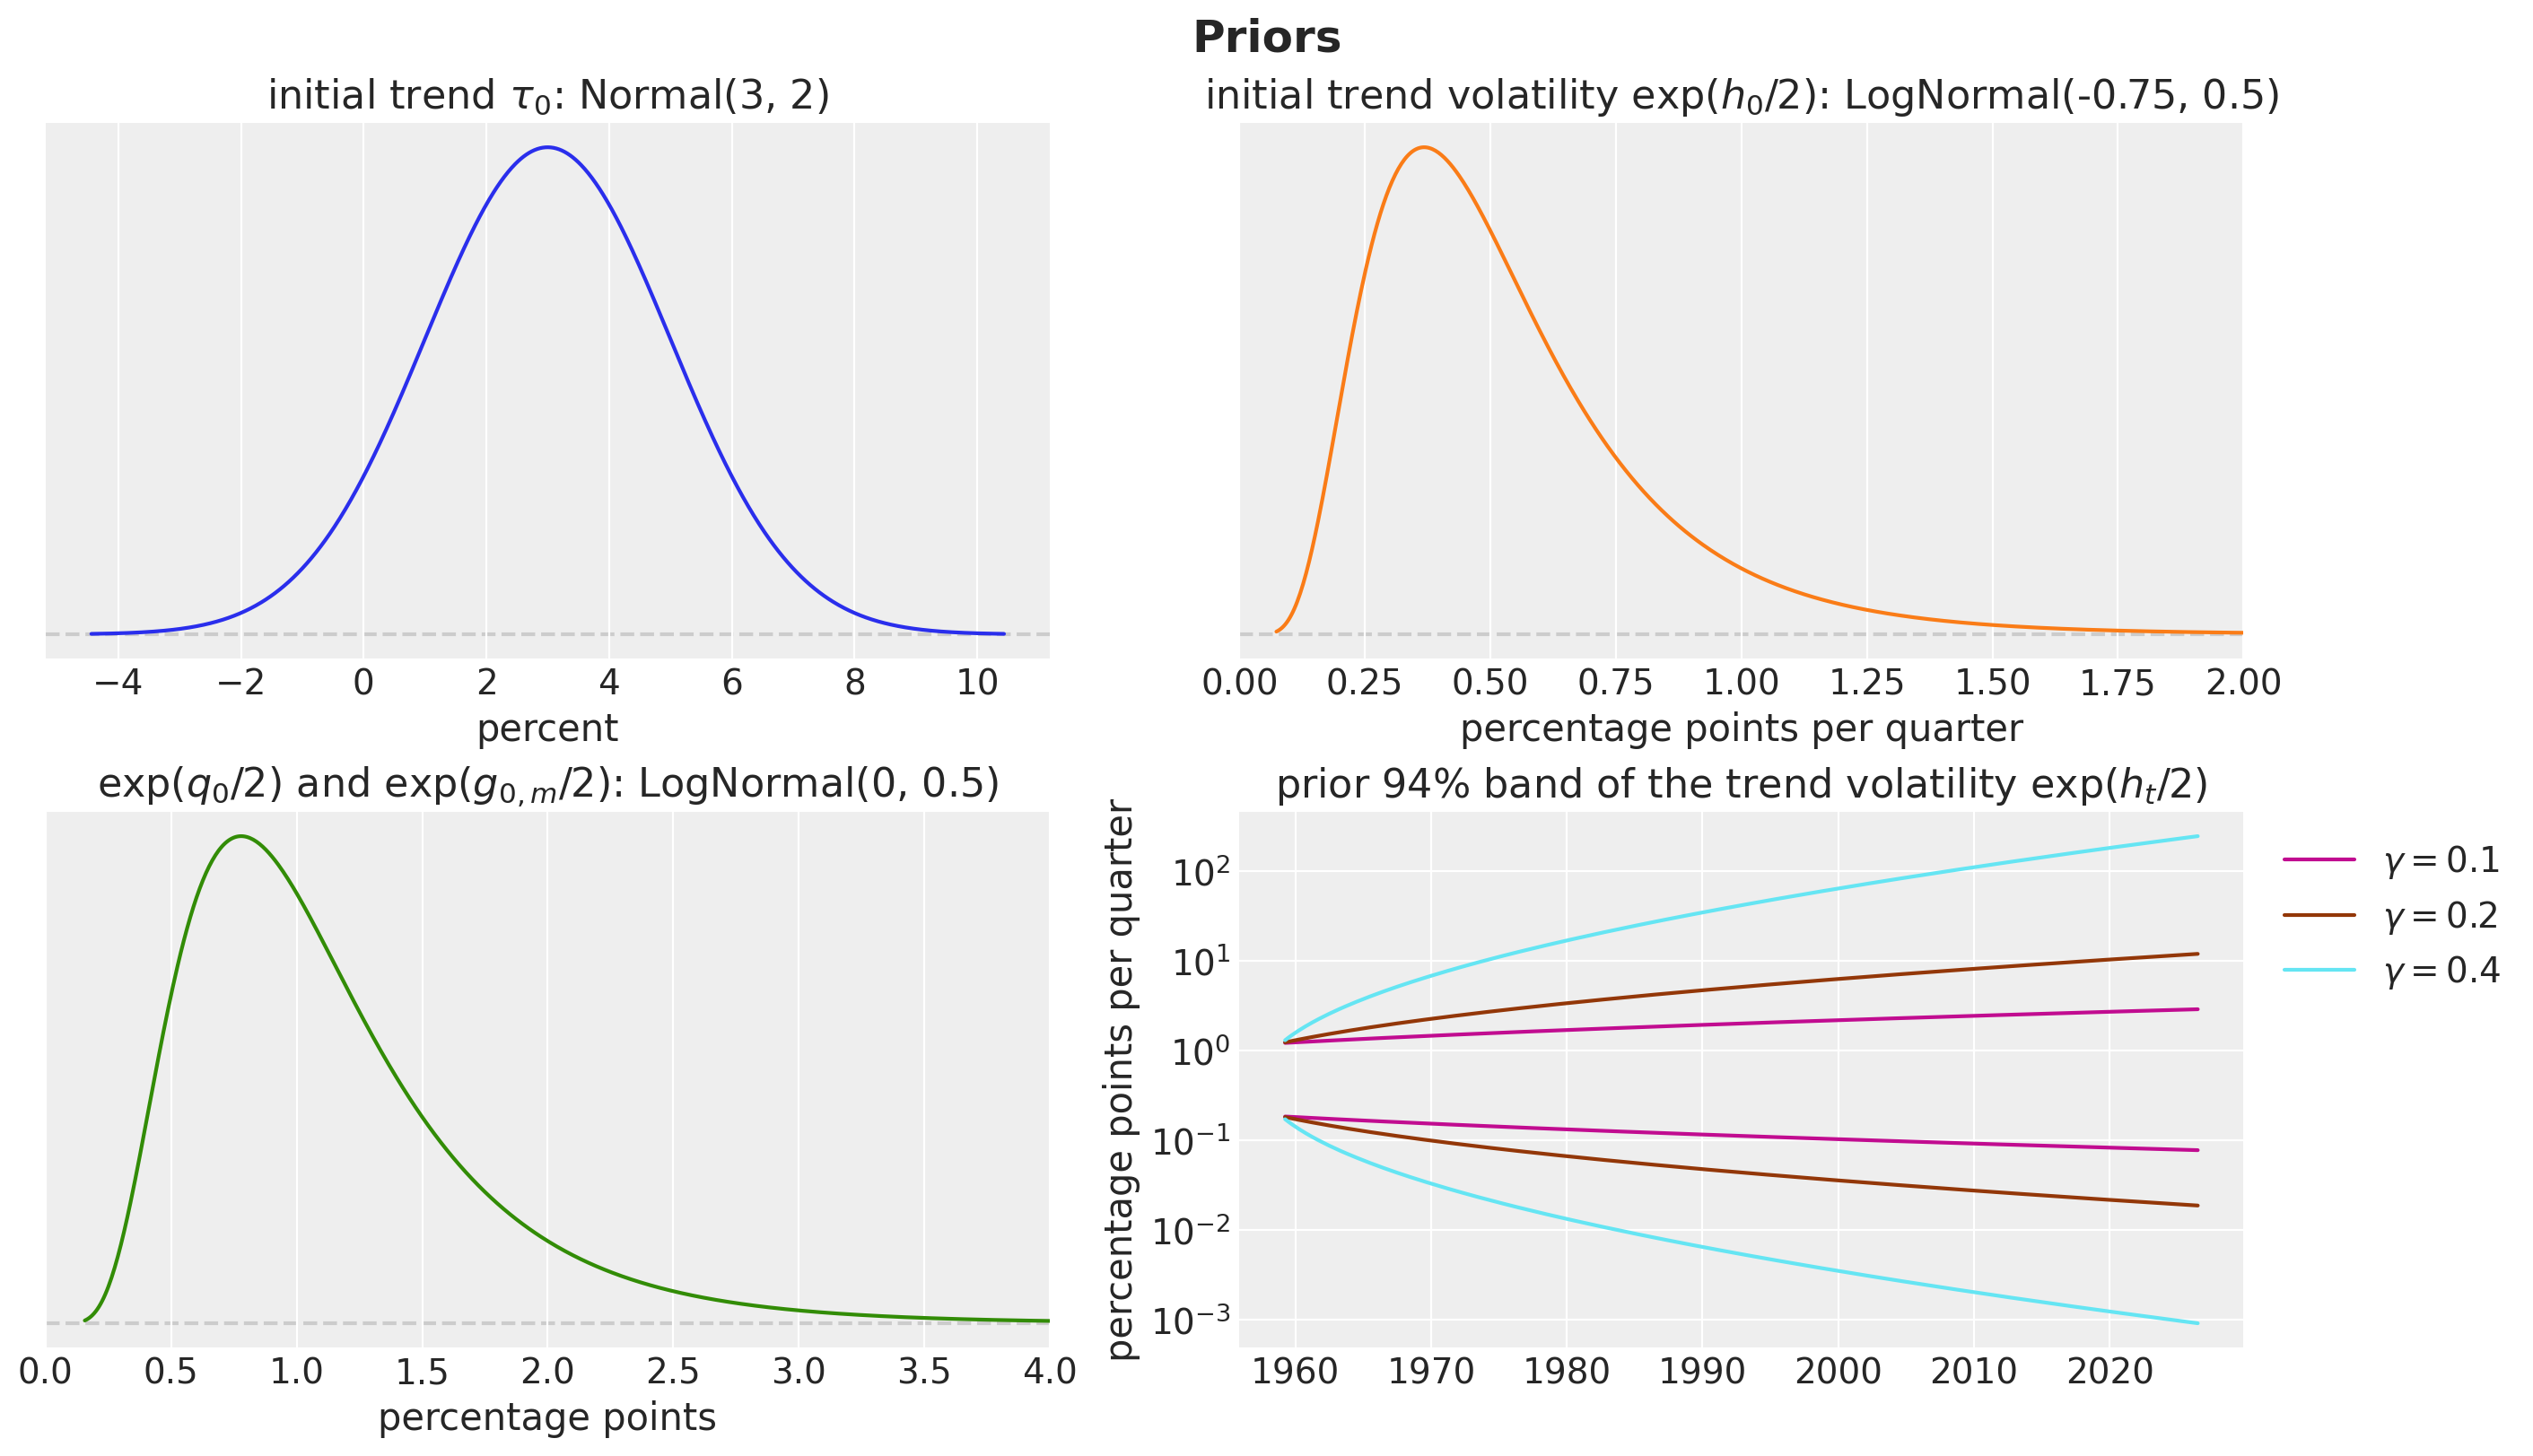

In [4]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), layout="constrained")
pz.Normal(3, 2).plot_pdf(ax=axes[0, 0], color="C0", legend=None)
axes[0, 0].set(title=r"initial trend $\tau_0$: Normal(3, 2)", xlabel="percent")
pz.LogNormal(-0.75, 0.5).plot_pdf(ax=axes[0, 1], color="C1", legend=None)
axes[0, 1].set(
    title=r"initial trend volatility $\exp(h_0 / 2)$: LogNormal(-0.75, 0.5)",
    xlabel="percentage points per quarter",
    xlim=(0, 2),
)
pz.LogNormal(0, 0.5).plot_pdf(ax=axes[1, 0], color="C2", legend=None)
axes[1, 0].set(
    xlabel="percentage points",
    xlim=(0, 4),
    title=r"$\exp(q_0 / 2)$ and $\exp(g_{0, m} / 2)$: LogNormal(0, 0.5)",
)

# Prior 94% band of the trend volatility exp(h_t / 2) after t quarters, for three vol-of-vol
# values: h_t ~ Normal(-1.5, sqrt(1 + gamma^2 t)), so the band is
# exp((-1.5 +/- z sqrt(1 + gamma^2 t)) / 2).
steps = jnp.arange(1, num_quarters + 1)  # (quarters,): steps taken by h_t
z_97 = norm.ppf(0.5 + CI_PROB / 2)

for color, gamma in zip(("C3", "C4", "C5"), (0.1, 0.2, 0.4), strict=True):
    half_width = z_97 * jnp.sqrt(1.0 + gamma**2 * steps)  # (quarters,)
    axes[1, 1].plot(
        dates, jnp.exp((-1.5 + half_width) / 2.0), color=color, label=rf"$\gamma = {gamma}$"
    )
    axes[1, 1].plot(dates, jnp.exp((-1.5 - half_width) / 2.0), color=color)

axes[1, 1].set(
    title=rf"prior ${CI_PROB:.0%}$ band of the trend volatility $\exp(h_t / 2)$".replace(
        "%", r"\%"
    ),
    ylabel="percentage points per quarter",
    yscale="log",
)
axes[1, 1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle("Priors", **TITLE);

The first three panels are the priors on the initial values, on the scale of the data: a trend between $-1\%$ and $7\%$, a trend shock of $0.2$ to $1.2$ percentage points per quarter, a common shock and a gap of $0.4$ to $2.6$ points (the floor adds $0.1$ to the gap). The fourth panel shows what $\gamma$ does. With $\gamma = 0.1$ the $94\%$ prior band of the trend volatility widens from $0.18$ to $1.2$ points per quarter in 1959 to $0.08$ to $2.9$ in 2026: over the sample its upper edge rises by a factor of about $2.4$ and its lower edge falls by about the same factor, and the prior says nothing about when the volatility moves. With $\gamma = 0.2$ the band ends at $0.02$ to $12$, and with $\gamma = 0.4$ below $0.001$ and above $200$, where the prior no longer constrains the path.

## The model function

The model is split into small functions, one per component, in the style of the [NumPyro HSGP example](https://num.pyro.ai/en/stable/examples/hsgp.html):

- `log_volatility` turns standardized steps from `innovations` into the volatility path $\exp(\cdot / 2)$ of a log-variance random walk.
- `measure_offsets` samples $\alpha_m$ and appends the zero offset of core PCE.
- `trend_component` builds $\tau_t$ and its volatility.
- `gap_volatility` builds $\sigma_{\min} + \exp(g_{t, m} / 2)$ under a `measure` plate.
- `common_transitory_shock` builds $c_t$ and its volatility.

`make_trend_inflation_model` composes them and has three switches, so that the ladder of the evaluation changes no code:

- `num_measures` is $M$; with `num_measures=1` there is no offset and the model is a univariate UCSV model in the style of Stock and Watson (2007), with the floor and the $\gamma$ of this notebook.
- `stochastic_volatility=False` freezes $h_t = h_0$ and $g_{t, m} = g_{0, m}$: constant variances.
- `common_transitory=True` adds $c_t$.

The model reads no covariates. [`Horizon.from_data`](../../reference/models.Horizon.html) takes the duration from the `covariates` array, so the training call passes `jnp.zeros((num_quarters, 0))` and a forecast call passes an array with eight more rows. `innovations` samples the in-sample steps under the `time` plate and, when the covariates are longer than the data, the horizon steps at a separate `_future` site. The gap volatility `gap_vol` has a time axis, and `predict` accepts a noise distribution whose scale varies over the full horizon, so the stochastic volatility propagates into the forecast without any extra code.

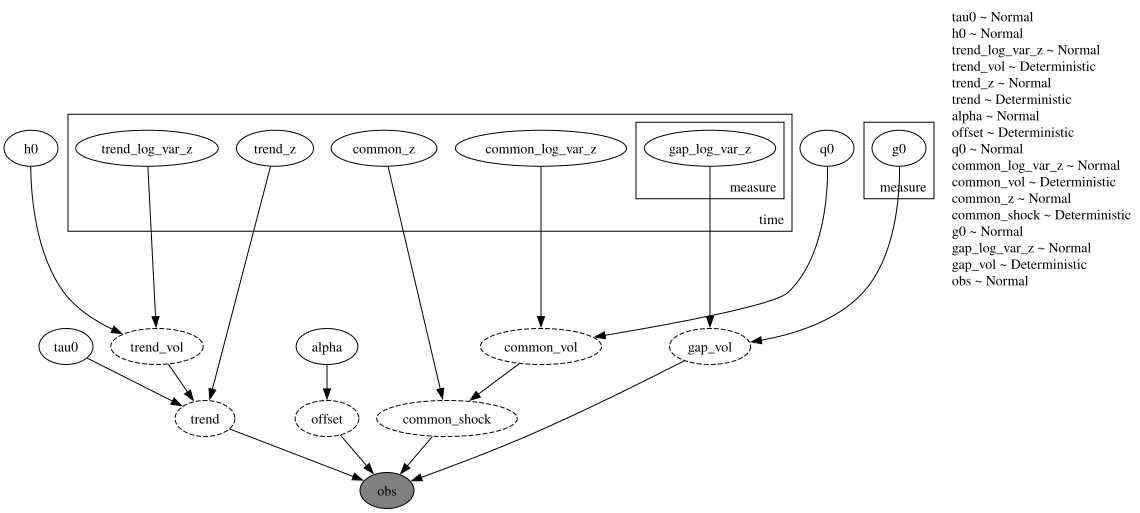

In [5]:
GAP_FLOOR = 0.1  # sigma_min, percentage points


def log_volatility(h: Horizon, name: str, initial: Array, vol_of_vol: float | Array) -> Array:
    # Standardized steps of the log-variance random walk: (duration, k)
    steps = innovations(h, name, dist.Normal(0.0, 1.0))
    return jnp.exp((initial + vol_of_vol * jnp.cumsum(steps, axis=-2)) / 2.0)


def measure_offsets(num_measures: int) -> Array:
    if num_measures == 1:
        return jnp.zeros(1)

    alpha = numpyro.sample("alpha", dist.Normal(0.0, 1.0).expand([num_measures - 1]).to_event(1))
    # Core PCE, the last measure, has offset zero: (num_measures,)
    return numpyro.deterministic("offset", jnp.concatenate([alpha, jnp.zeros(1)]))


def trend_component(h: Horizon, vol_of_vol: float | Array, stochastic_volatility: bool) -> Array:
    tau0 = numpyro.sample("tau0", dist.Normal(3.0, 2.0))
    h0 = numpyro.sample("h0", dist.Normal(-1.5, 1.0))

    if stochastic_volatility:
        trend_vol = log_volatility(h, "trend_log_var_z", h0, vol_of_vol)  # (duration, 1)
    else:
        trend_vol = jnp.full((h.duration, 1), jnp.exp(h0 / 2.0))

    trend_vol = numpyro.deterministic("trend_vol", trend_vol)
    trend_z = innovations(h, "trend_z", dist.Normal(0.0, 1.0))  # (duration, 1)
    return numpyro.deterministic("trend", tau0 + jnp.cumsum(trend_vol * trend_z, axis=-2))


def gap_volatility(
    h: Horizon, num_measures: int, vol_of_vol: float | Array, stochastic_volatility: bool
) -> Array:
    with numpyro.plate("measure", num_measures, dim=-1):
        g0 = numpyro.sample("g0", dist.Normal(0.0, 1.0))  # (num_measures,)

        if stochastic_volatility:
            # (duration, num_measures)
            scale = log_volatility(h, "gap_log_var_z", g0, vol_of_vol)
        else:
            scale = jnp.broadcast_to(jnp.exp(g0 / 2.0), (h.duration, num_measures))

    return numpyro.deterministic("gap_vol", GAP_FLOOR + scale)


def common_transitory_shock(h: Horizon, vol_of_vol: float | Array) -> Array:
    q0 = numpyro.sample("q0", dist.Normal(0.0, 1.0))
    common_vol = numpyro.deterministic(
        "common_vol", log_volatility(h, "common_log_var_z", q0, vol_of_vol)
    )  # (duration, 1)
    common_z = innovations(h, "common_z", dist.Normal(0.0, 1.0))  # (duration, 1)
    return numpyro.deterministic("common_shock", common_vol * common_z)


def make_trend_inflation_model(
    num_measures: int,
    *,
    vol_of_vol: float | Array = 0.1,
    stochastic_volatility: bool = True,
    common_transitory: bool = False,
) -> ForecastModel:
    def trend_inflation_model(covariates: Array, data: Array | None = None) -> None:
        h = Horizon.from_data(covariates, data)
        # (duration, 1) trend + (num_measures,) offsets -> (duration, num_measures) predictor
        prediction = trend_component(h, vol_of_vol, stochastic_volatility) + measure_offsets(
            num_measures
        )

        if common_transitory:
            # The same shock moves every measure: (duration, 1)
            prediction = prediction + common_transitory_shock(h, vol_of_vol)

        gap_vol = gap_volatility(h, num_measures, vol_of_vol, stochastic_volatility)
        predict(h, dist.Normal(0.0, gap_vol), prediction)

    return trend_inflation_model


covariates_train = jnp.zeros((num_quarters, 0))  # (quarters, 0): only the duration is read
model = make_trend_inflation_model(num_measures, common_transitory=True)
numpyro.render_model(model, model_args=(covariates_train, rates), render_distributions=True)

## Prior predictive check

Before the data, we draw core PCE inflation from the priors over the whole sample and compare its band with the observed series. The band should contain the data with room to spare, and it should not contain values that no price index has ever produced.

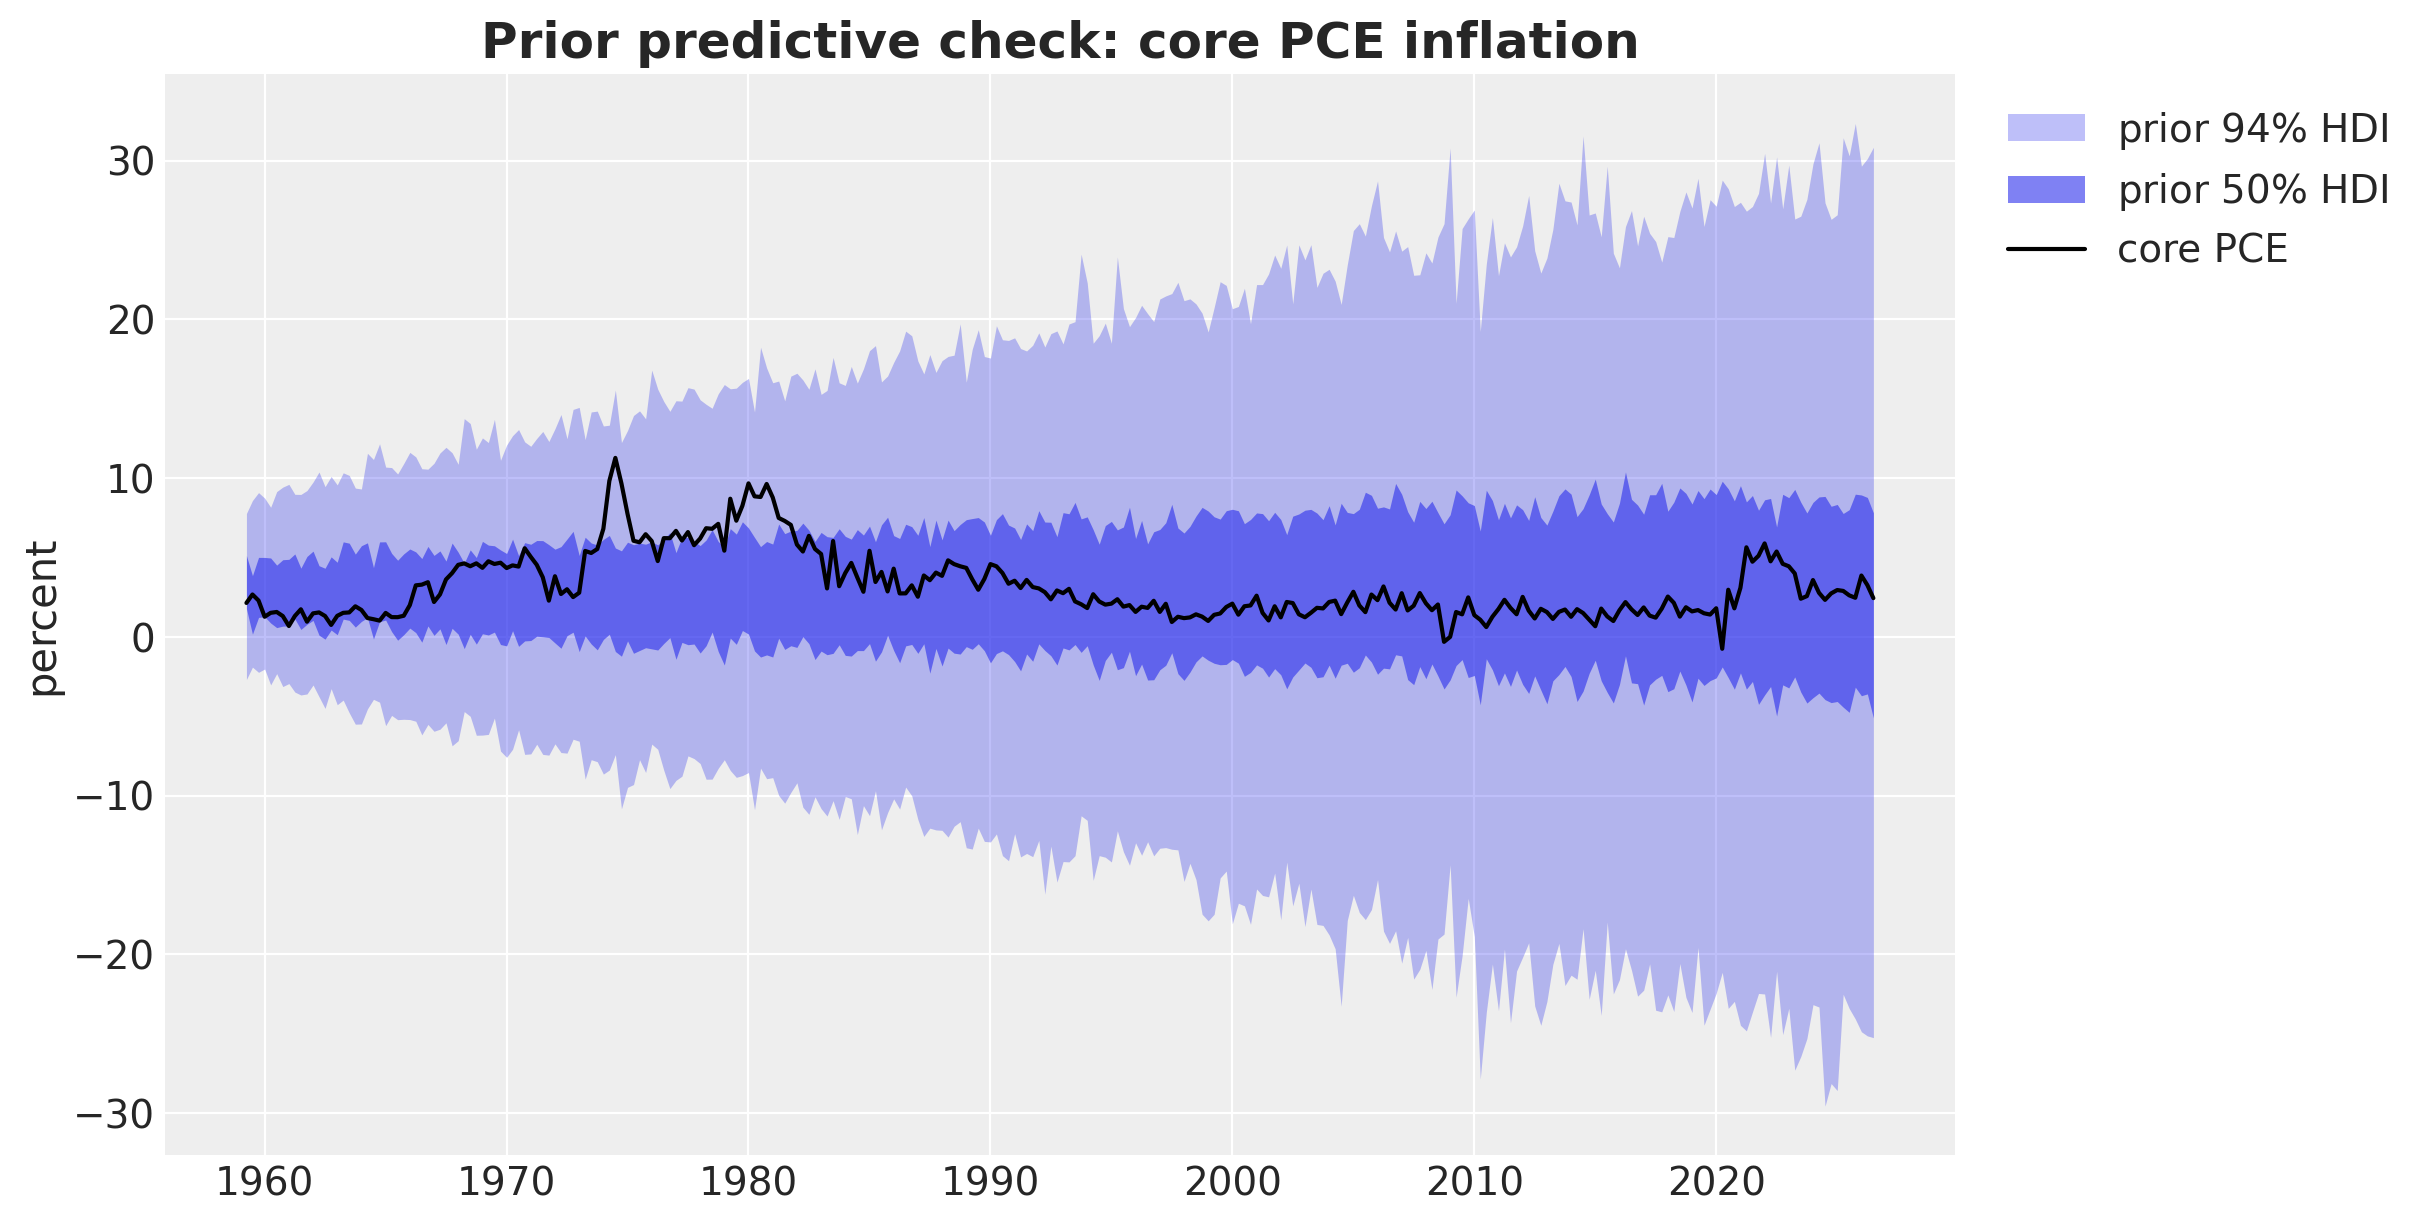

In [6]:
HDI_PROBS = (CI_PROB, 0.5)
HDI_ALPHAS = (0.3, 0.6)


def hdi_label(prob: float) -> str:
    return rf"${prob:.0%}$ HDI".replace("%", r"\%")


date_num = mdates.date2num(dates)  # matplotlib date numbers for plot_lm
rng_key, key_prior = random.split(rng_key)
prior_obs = Predictive(model, num_samples=1_000, return_sites=["obs"])(
    key_prior, covariates_train
)["obs"]  # (draws, quarters, measures)

prior_tree = predictions_to_datatree(
    prior_obs[:, :, -1:],
    date_num,
    ["core PCE"],
    group="prior_predictive",
    observed=rates[:, -1:],
)
pc = az.plot_lm(
    prior_tree,
    y="obs",
    x="t",
    plot_dim="time",
    group="prior_predictive",
    ci_prob=HDI_PROBS,
    smooth=False,
    visuals={
        "ci_band": {"color": "C0"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    },
    aes={"alpha": ["prob"]},
    alpha=HDI_ALPHAS,
    figure_kwargs={"figsize": (12, 6)},
)
ax = pc.viz["figure"].item().axes[0]
(observed_line,) = ax.plot(date_num, rates[:, -1], color="black", label="core PCE")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
band_handles = []

for prob in HDI_PROBS:
    band = pc.viz["ci_band"]["t"].sel(prob=prob).item()
    band.set_label(f"prior {hdi_label(prob)}")
    band_handles.append(band)

ax.legend(handles=[*band_handles, observed_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(ylabel="percent")
ax.set_title("Prior predictive check: core PCE inflation", **TITLE);

The prior band widens with time, because the random walks of the trend and of the log-variances accumulate variance. In 1959Q2 the $94\%$ band of core PCE inflation runs from $-2.7\%$ to $7.8\%$; in 1980Q1 from $-8.6\%$ to $16.3\%$; in 2026Q3 from $-25\%$ to $31\%$, and the $50\%$ band spans $-5.1\%$ to $7.8\%$ there. The first criterion holds: the data stay inside the $94\%$ band in every quarter. The second fails in the last decades, since no US price index has produced an annualized quarterly rate of $-25\%$, and we accept that: the priors are weak on purpose, and the posterior has to decide how volatile the trend, the common shock and the gaps are at each date.

## Inference with NUTS

We sample the posterior with four NUTS chains of $1{,}000$ warmup and $2{,}000$ draws each, with `target_accept_prob` at $0.95$ instead of its default of $0.8$, which shortens the leapfrog steps. The model has about $2{,}170$ latent dimensions, all continuous: 270 standardized steps for each of seven random walks (the trend and the log-variances of the trend, of the common shock and of the four gaps), 270 unit normals for the common shock, the initial values and the offsets.

`fit_nuts` returns the `MCMC` object and the wall time. `fit_title` writes the wall time, the number of divergent transitions, the largest $\hat{R}$ and the smallest effective sample size (ESS) into the title of a figure. Its diagnostics cover the global parameters and every path the notebook plots (the trend, the trend volatility, the volatility of the common shock and the gap volatilities), not only the global parameters.

In [7]:
NUM_CHAINS = 4
FULL_WARMUP = 1_000
FULL_SAMPLES = 2_000
TARGET_ACCEPT = 0.95
DIAGNOSTIC_SITES = (
    "tau0",
    "h0",
    "g0",
    "q0",
    "alpha",
    "trend",
    "trend_vol",
    "gap_vol",
    "common_vol",
)


def fit_nuts(
    rng_key: Array, model: ForecastModel, data: Array, *, num_warmup: int, num_samples: int
) -> tuple[MCMC, float]:
    mcmc = MCMC(
        NUTS(model, target_accept_prob=TARGET_ACCEPT),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=NUM_CHAINS,
        progress_bar=False,
    )
    start = perf_counter()
    mcmc.run(rng_key, jnp.zeros((data.shape[0], 0)), data, extra_fields=("diverging",))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, perf_counter() - start


def num_divergences(mcmc: MCMC) -> int:
    return int(np.asarray(mcmc.get_extra_fields()["diverging"]).sum())


def diagnostics(mcmc: MCMC) -> tuple[float, float]:
    # Largest split R-hat and smallest effective sample size over DIAGNOSTIC_SITES
    samples = mcmc.get_samples(group_by_chain=True)
    summary = numpyro.diagnostics.summary(
        {site: samples[site] for site in DIAGNOSTIC_SITES if site in samples}, group_by_chain=True
    )
    r_hat = max(float(np.max(stats["r_hat"])) for stats in summary.values())
    ess = min(float(np.min(stats["n_eff"])) for stats in summary.values())
    return r_hat, ess


def fit_title(label: str, mcmc: MCMC, seconds: float) -> str:
    r_hat, ess = diagnostics(mcmc)
    return (
        f"{label}\n{seconds:.0f} s, divergences {num_divergences(mcmc)}, "
        rf"max $\hat{{R}}$ {r_hat:.3f}, min ESS {ess:,.0f}"
    )


rng_key, key_fit = random.split(rng_key)
mcmc, seconds = fit_nuts(key_fit, model, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES)

`export` turns the posterior into an ArviZ `DataTree` with [`to_datatree`](../../reference/convert.to_datatree.html): the four chains, the in-sample posterior predictive, the eight-quarter forecast (because `covariates_full` extends past the data) and the quarter dates as the `time` coordinate, with the measure names on every site that has a measure axis. The trace plot after it shows the global parameters and the diagnostics in its title.

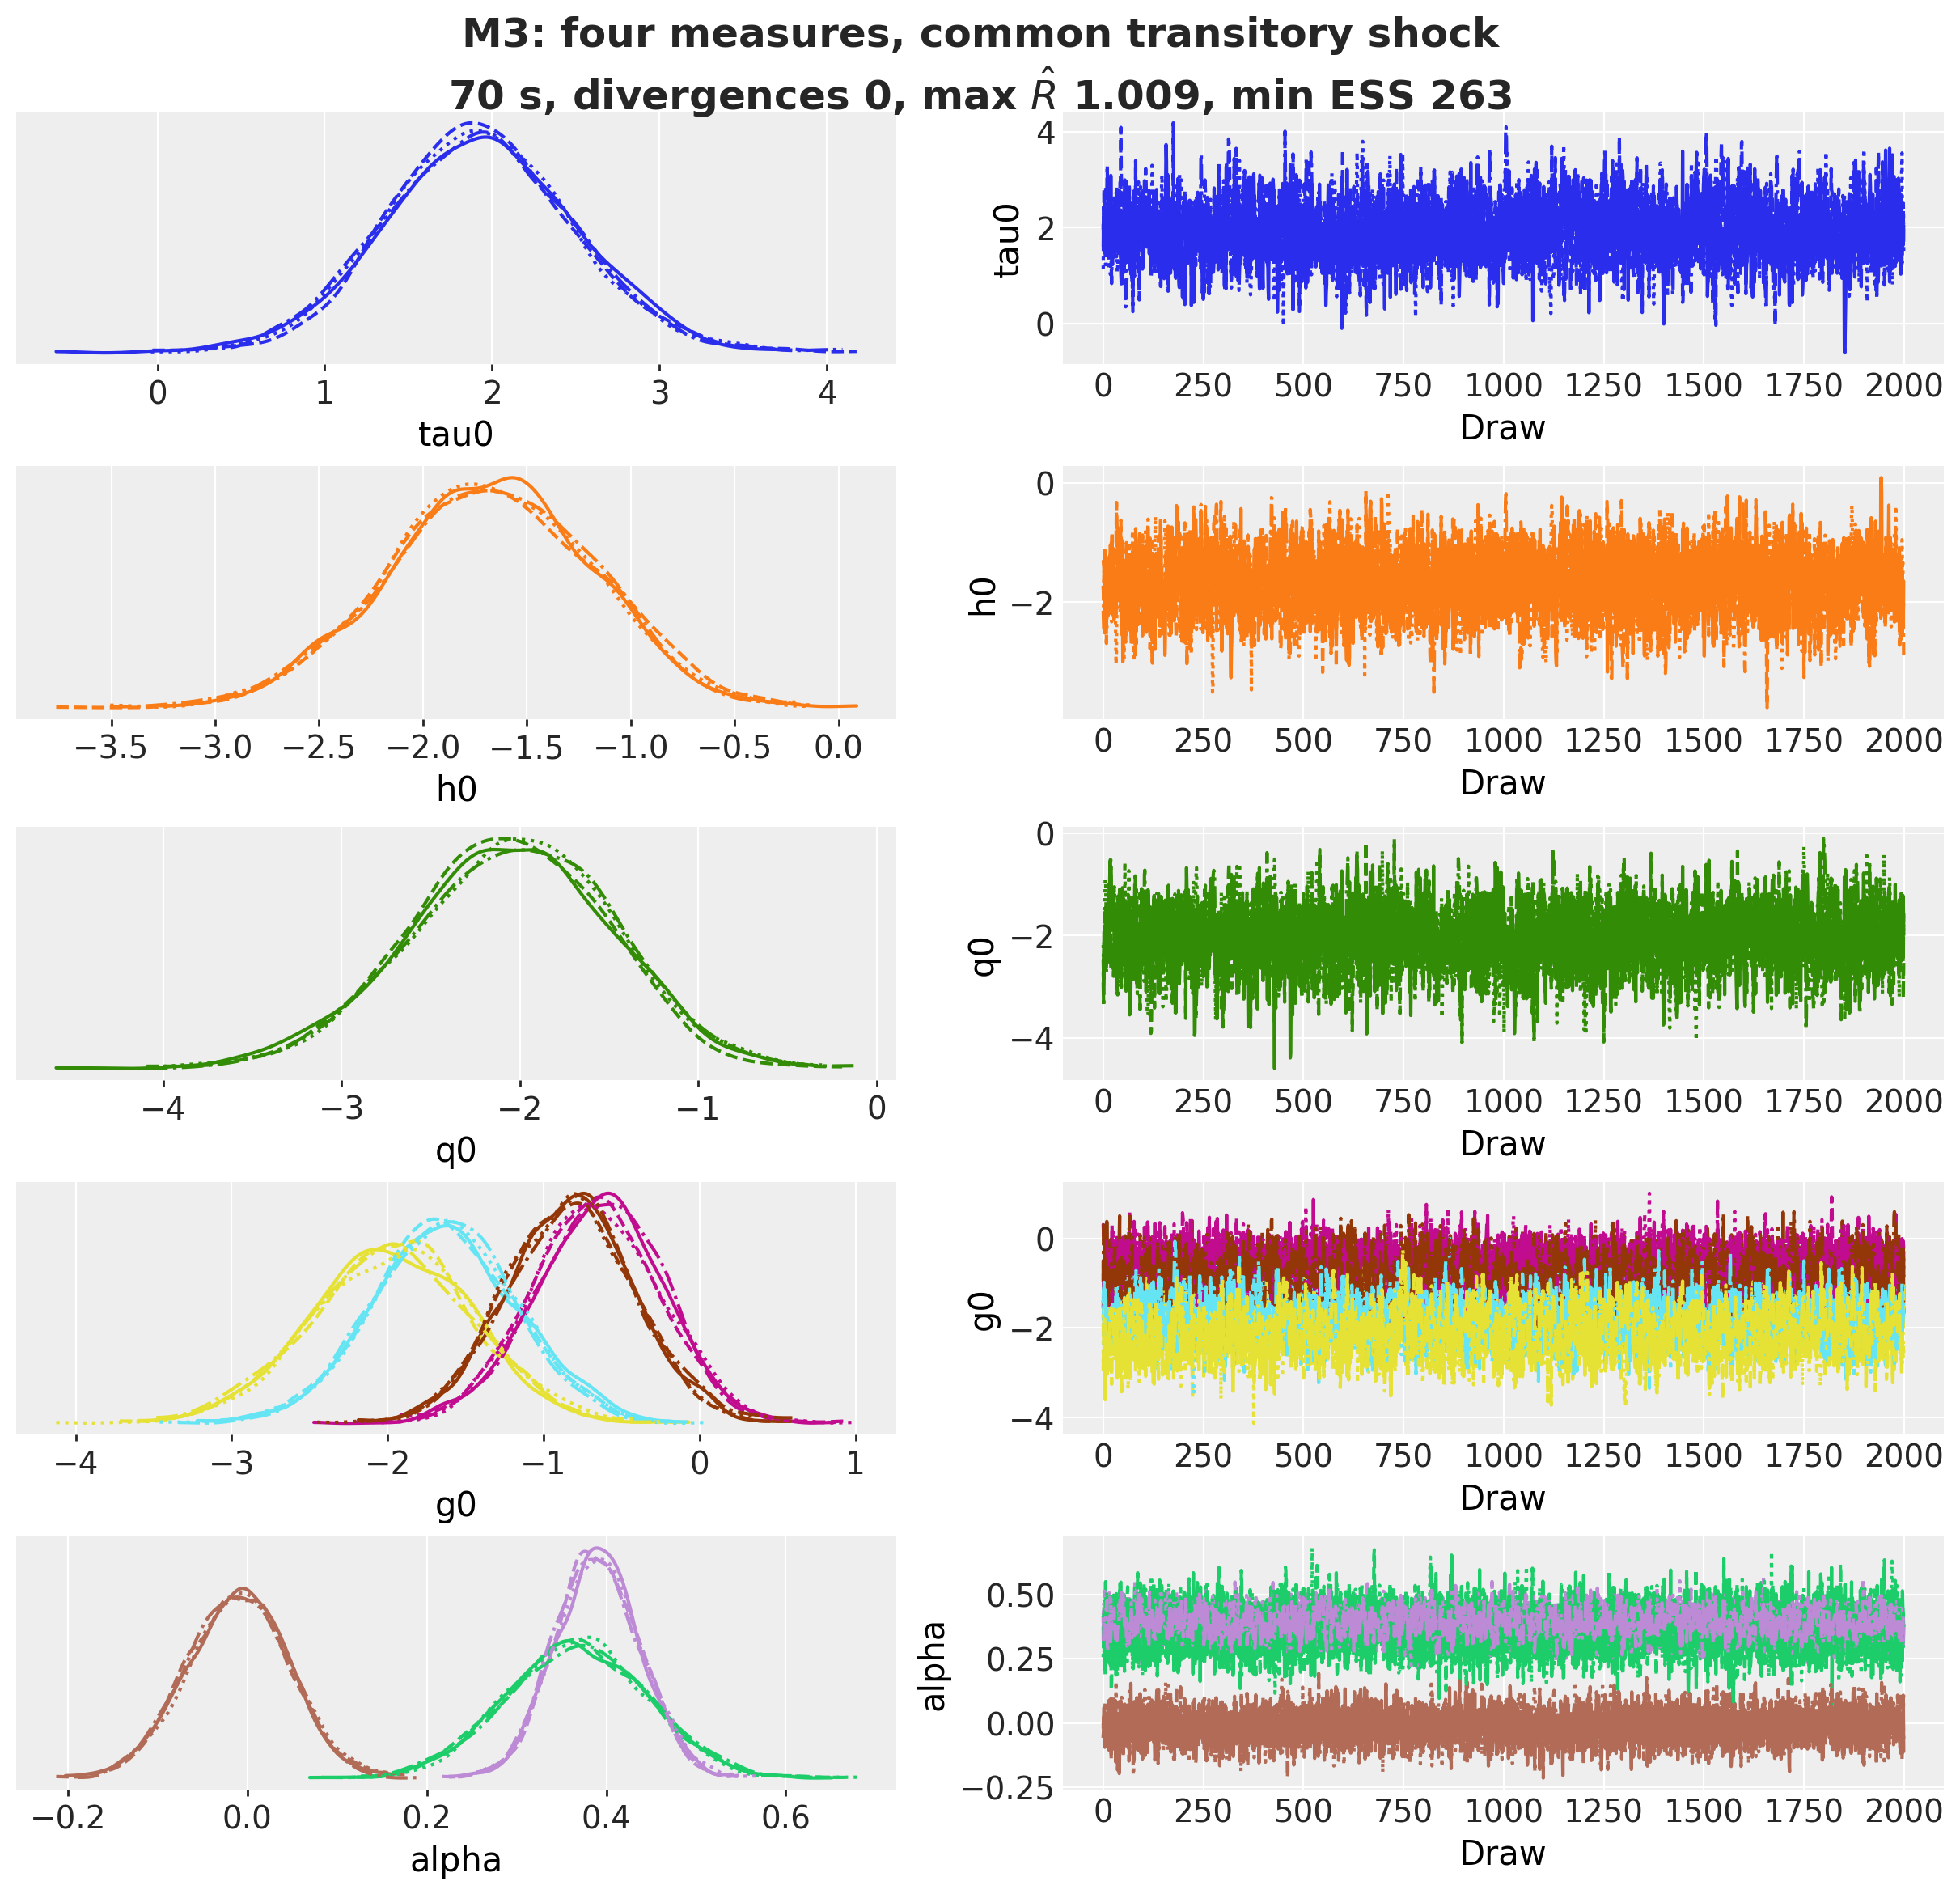

In [8]:
HORIZON = 8
covariates_full = jnp.zeros((num_quarters + HORIZON, 0))  # (quarters + 8, 0): adds the horizon
future_dates = (dates[-1].astype("datetime64[M]") + 3 * np.arange(1, HORIZON + 1)).astype(
    "datetime64[D]"
)
future_date_num = mdates.date2num(future_dates)
time_coord = np.concatenate([dates, future_dates])
posterior_dims = {
    "trend": ["time"],
    "trend_vol": ["time"],
    "common_vol": ["time"],
    "common_shock": ["time"],
    "gap_vol": ["time", "measure"],
    "g0": ["measure"],
    "offset": ["measure"],
    "alpha": ["free_measure"],
}


def export(rng_key: Array, model: ForecastModel, mcmc: MCMC) -> xr.DataTree:
    return to_datatree(
        rng_key,
        model,
        mcmc.get_samples(),
        rates,
        covariates_full,
        num_chains=NUM_CHAINS,
        coords={"measure": list(measure_labels), "free_measure": list(measure_labels[:-1])},
        time_coord=time_coord,
        posterior_dims=posterior_dims,
        obs_dims=["time", "measure"],
    )


rng_key, key_tree = random.split(rng_key)
tree = export(key_tree, model, mcmc)
posterior = tree["posterior"].dataset

pc = az.plot_trace_dist(
    tree,
    var_names=["tau0", "h0", "q0", "g0", "alpha"],
    compact=True,
    figure_kwargs={"figsize": (12, 11)},
)
pc.viz["figure"].item().suptitle(
    fit_title("M3: four measures, common transitory shock", mcmc, seconds), y=1.05, **TITLE
);

The fit has no divergent transitions, and the four chains overlap for every global parameter. Over the parameters and the paths, the largest $\hat{R}$ is $1.009$ and the smallest effective sample size is $263$.

## Trend inflation

The trend is the persistent part of inflation that all four measures share. We plot its posterior with core PCE inflation, the reference measure, on top: the distance between the line and the band is the transitory part of core PCE, the common shock plus its own gap.

In [9]:
def stack_draws(variable: xr.DataArray) -> np.ndarray:
    # (chain, draw, time, ...) -> (sample, time, ...)
    return variable.stack(sample=("chain", "draw")).transpose("sample", "time", ...).to_numpy()


def plot_bands(
    draws: np.ndarray,
    x: np.ndarray,
    series: list[str],
    *,
    color: str = "C0",
    label: str = "",
    mean_line: bool = False,
    col_wrap: int = 1,
    figsize: tuple[int, int] = (12, 6),
    plot_collection: PlotCollection | None = None,
) -> tuple[PlotCollection, list[Artist]]:
    # HDI bands (and optionally the mean) of `draws` (samples, len(x), len(series)) against x,
    # one panel per series; returns the handles labeled with the `label` prefix.
    visuals = {
        "ci_band": {"color": color},
        "observed_scatter": False,
        "pe_line": {"color": color} if mean_line else False,
        "xlabel": False,
        "ylabel": False,
    }
    layout = {}

    if plot_collection is None:
        layout = {
            "col_wrap": col_wrap,
            "aes": {"alpha": ["prob"]},
            "alpha": HDI_ALPHAS,
            "figure_kwargs": {"figsize": figsize},
        }

    pc = az.plot_lm(
        predictions_to_datatree(draws, x, series),
        y="obs",
        x="t",
        plot_dim="time",
        ci_prob=HDI_PROBS,
        point_estimate="mean",
        smooth=False,
        visuals=visuals,
        plot_collection=plot_collection,
        **layout,
    )
    handles = []

    for prob in HDI_PROBS:
        band = pc.viz["ci_band"]["t"].sel(series=series[0], prob=prob).item()
        band.set_label(f"{label}{hdi_label(prob)}")
        handles.append(band)

    if mean_line:
        line = pc.viz["pe_line"]["t"].sel(series=series[0]).item()
        line.set_label(f"{label}posterior mean")
        handles.append(line)

    for ax in pc.viz["figure"].item().axes:
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    return pc, handles

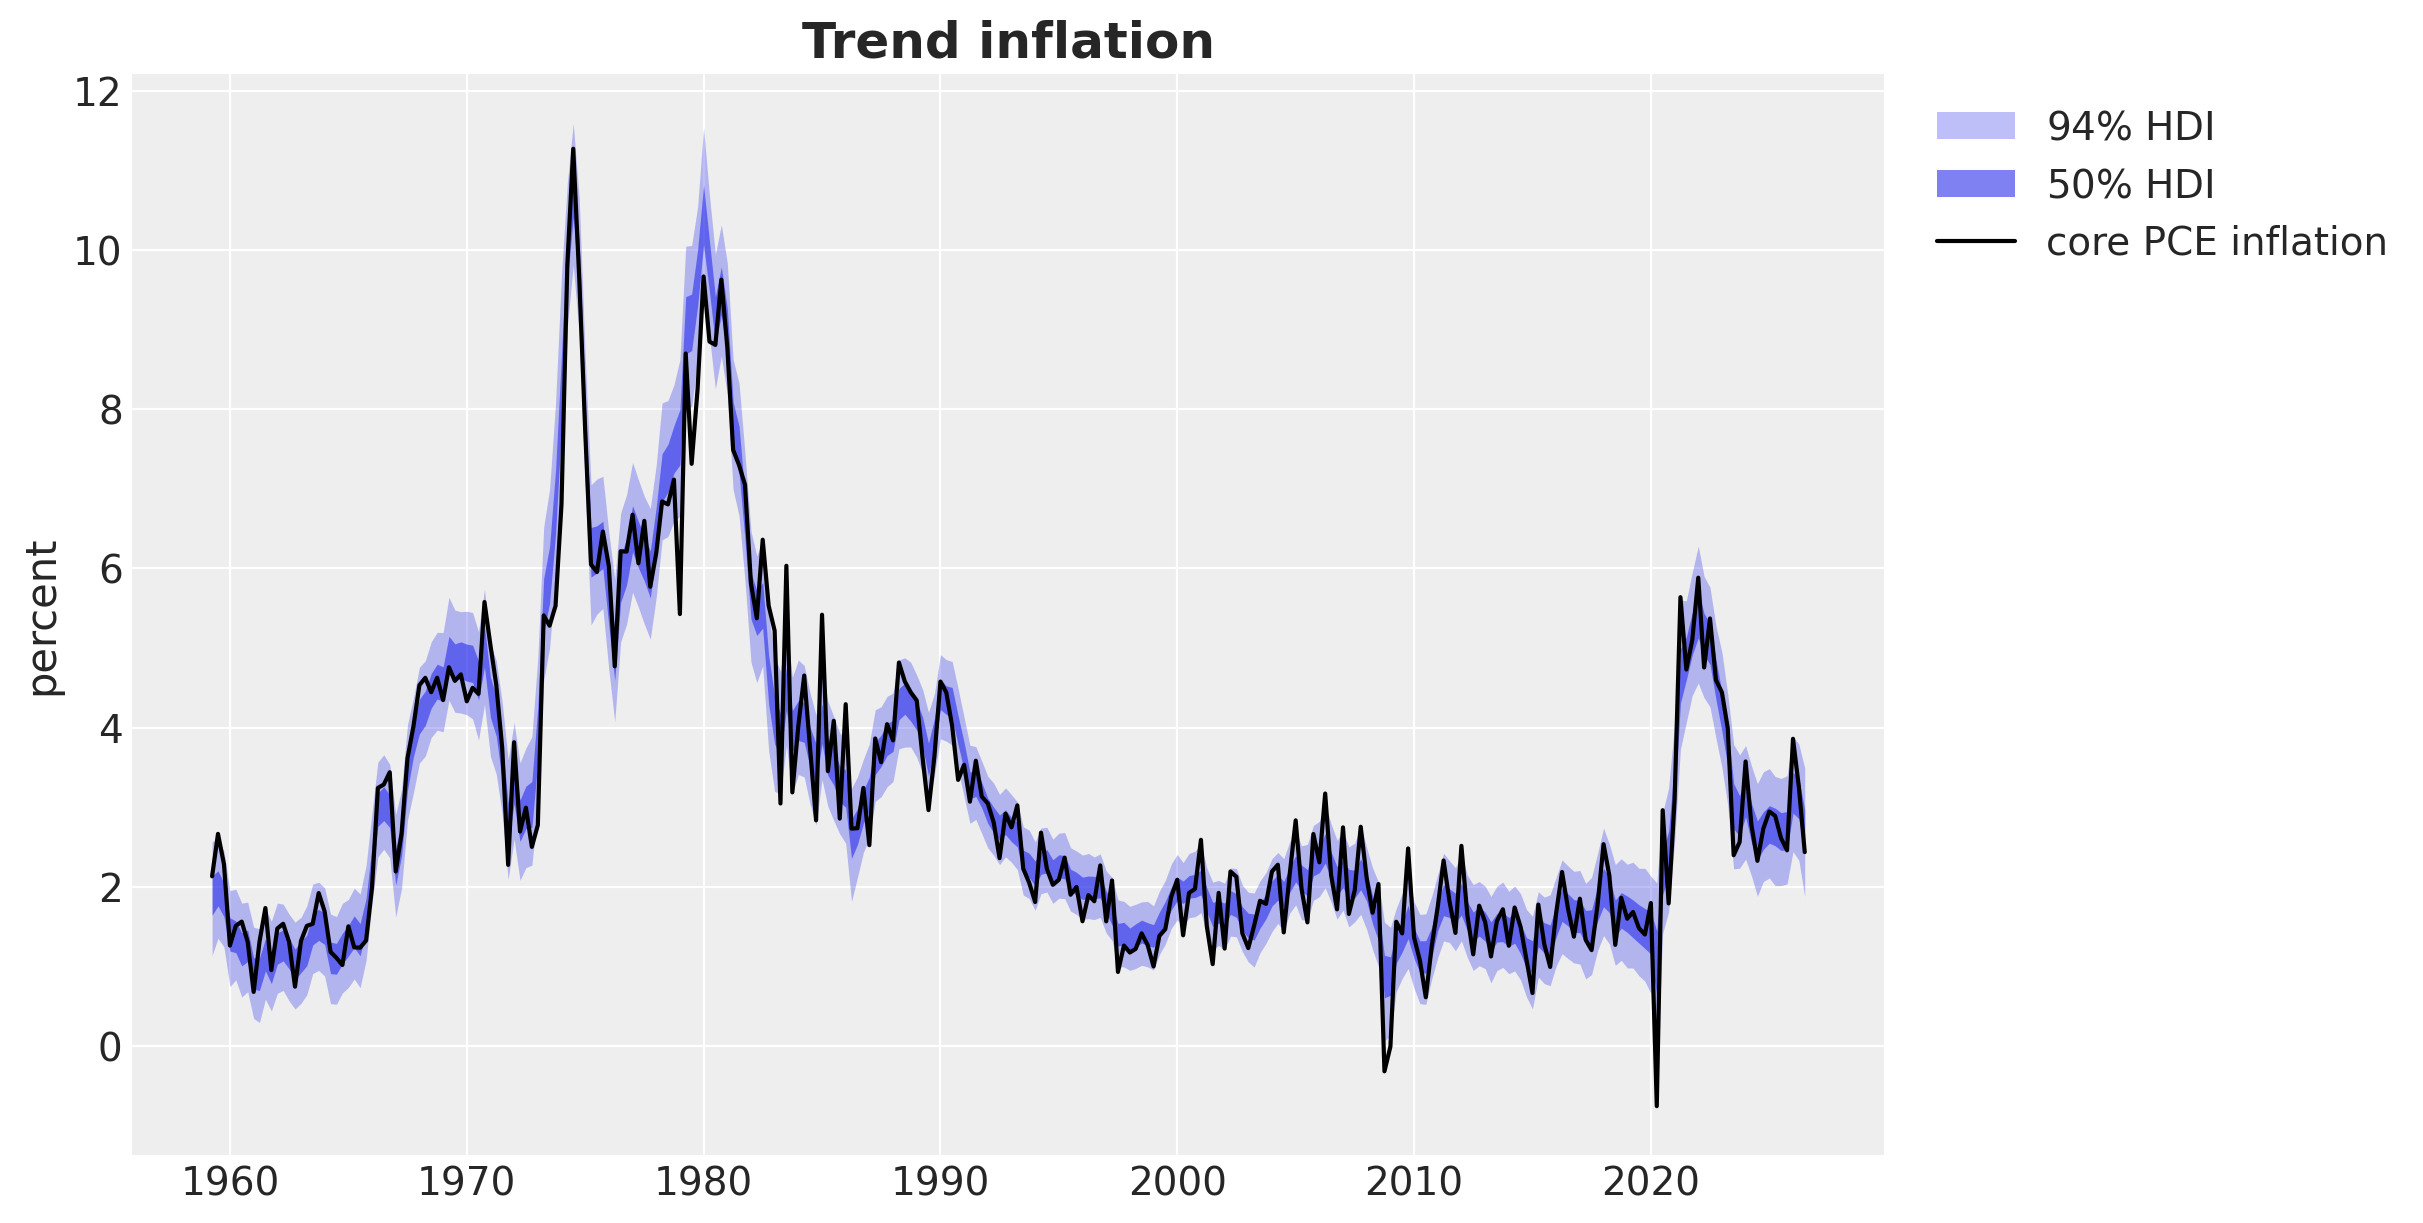

In [10]:
trend_draws = stack_draws(posterior["trend"])  # (samples, quarters, 1)
pc, band_handles = plot_bands(trend_draws, date_num, ["trend"])
ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(date_num, rates[:, -1], color="black", label="core PCE inflation")
ax.legend(handles=[*band_handles, core_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(ylabel="percent")
ax.set_title("Trend inflation", **TITLE);

The band follows the broad moves of core PCE and leaves out most of its quarterly noise. The $94\%$ HDI of the trend is about $1.2$ percentage points wide in a typical quarter and $2.5$ at its widest, in 1974Q1. Along the sample:

- The trend starts at $1.9\%$ in 1959Q2 ($94\%$ HDI $1.1$ to $2.6$), dips to $0.9\%$ in 1961 and climbs to $4.8\%$ by 1970Q1.
- It peaks twice, at $10.7\%$ in 1974Q3 and $10.5\%$ in 1980Q1. At the second peak core PCE is at $9.7\%$ and the trend sits above it, because the two CPI measures, both above $14\%$ that quarter, pull the common trend up. The offsets are constant, so the model cannot tell the pre-1983 housing treatment of the CPI from a move of the trend.
- The disinflation takes it to about $4\%$ in 1985Q1 and $2.3\%$ in 1995Q1. From 1995 to 2019 the posterior mean stays between $0.8\%$, its value in 2008Q4, and $2.5\%$.
- In 2020Q2 the trend dips to $0.9\%$ ($94\%$ HDI $-0.4$ to $2.1$) while core PCE falls to $-0.8\%$: the common shock takes most of that quarter.
- The surge takes the trend to $4.6\%$ in 2021Q2 and $5.4\%$ in 2022Q1, and it comes down to $2.7\%$ in 2026Q3 ($94\%$ HDI $1.9$ to $3.5$).

## The common transitory shock

To see what $c_t$ does, we fit the same model without it, so that the transitory part of each measure is its own independent gap. We call the model without the common shock **M2** and the model of this notebook **M3**, the names they have in the backtest below.

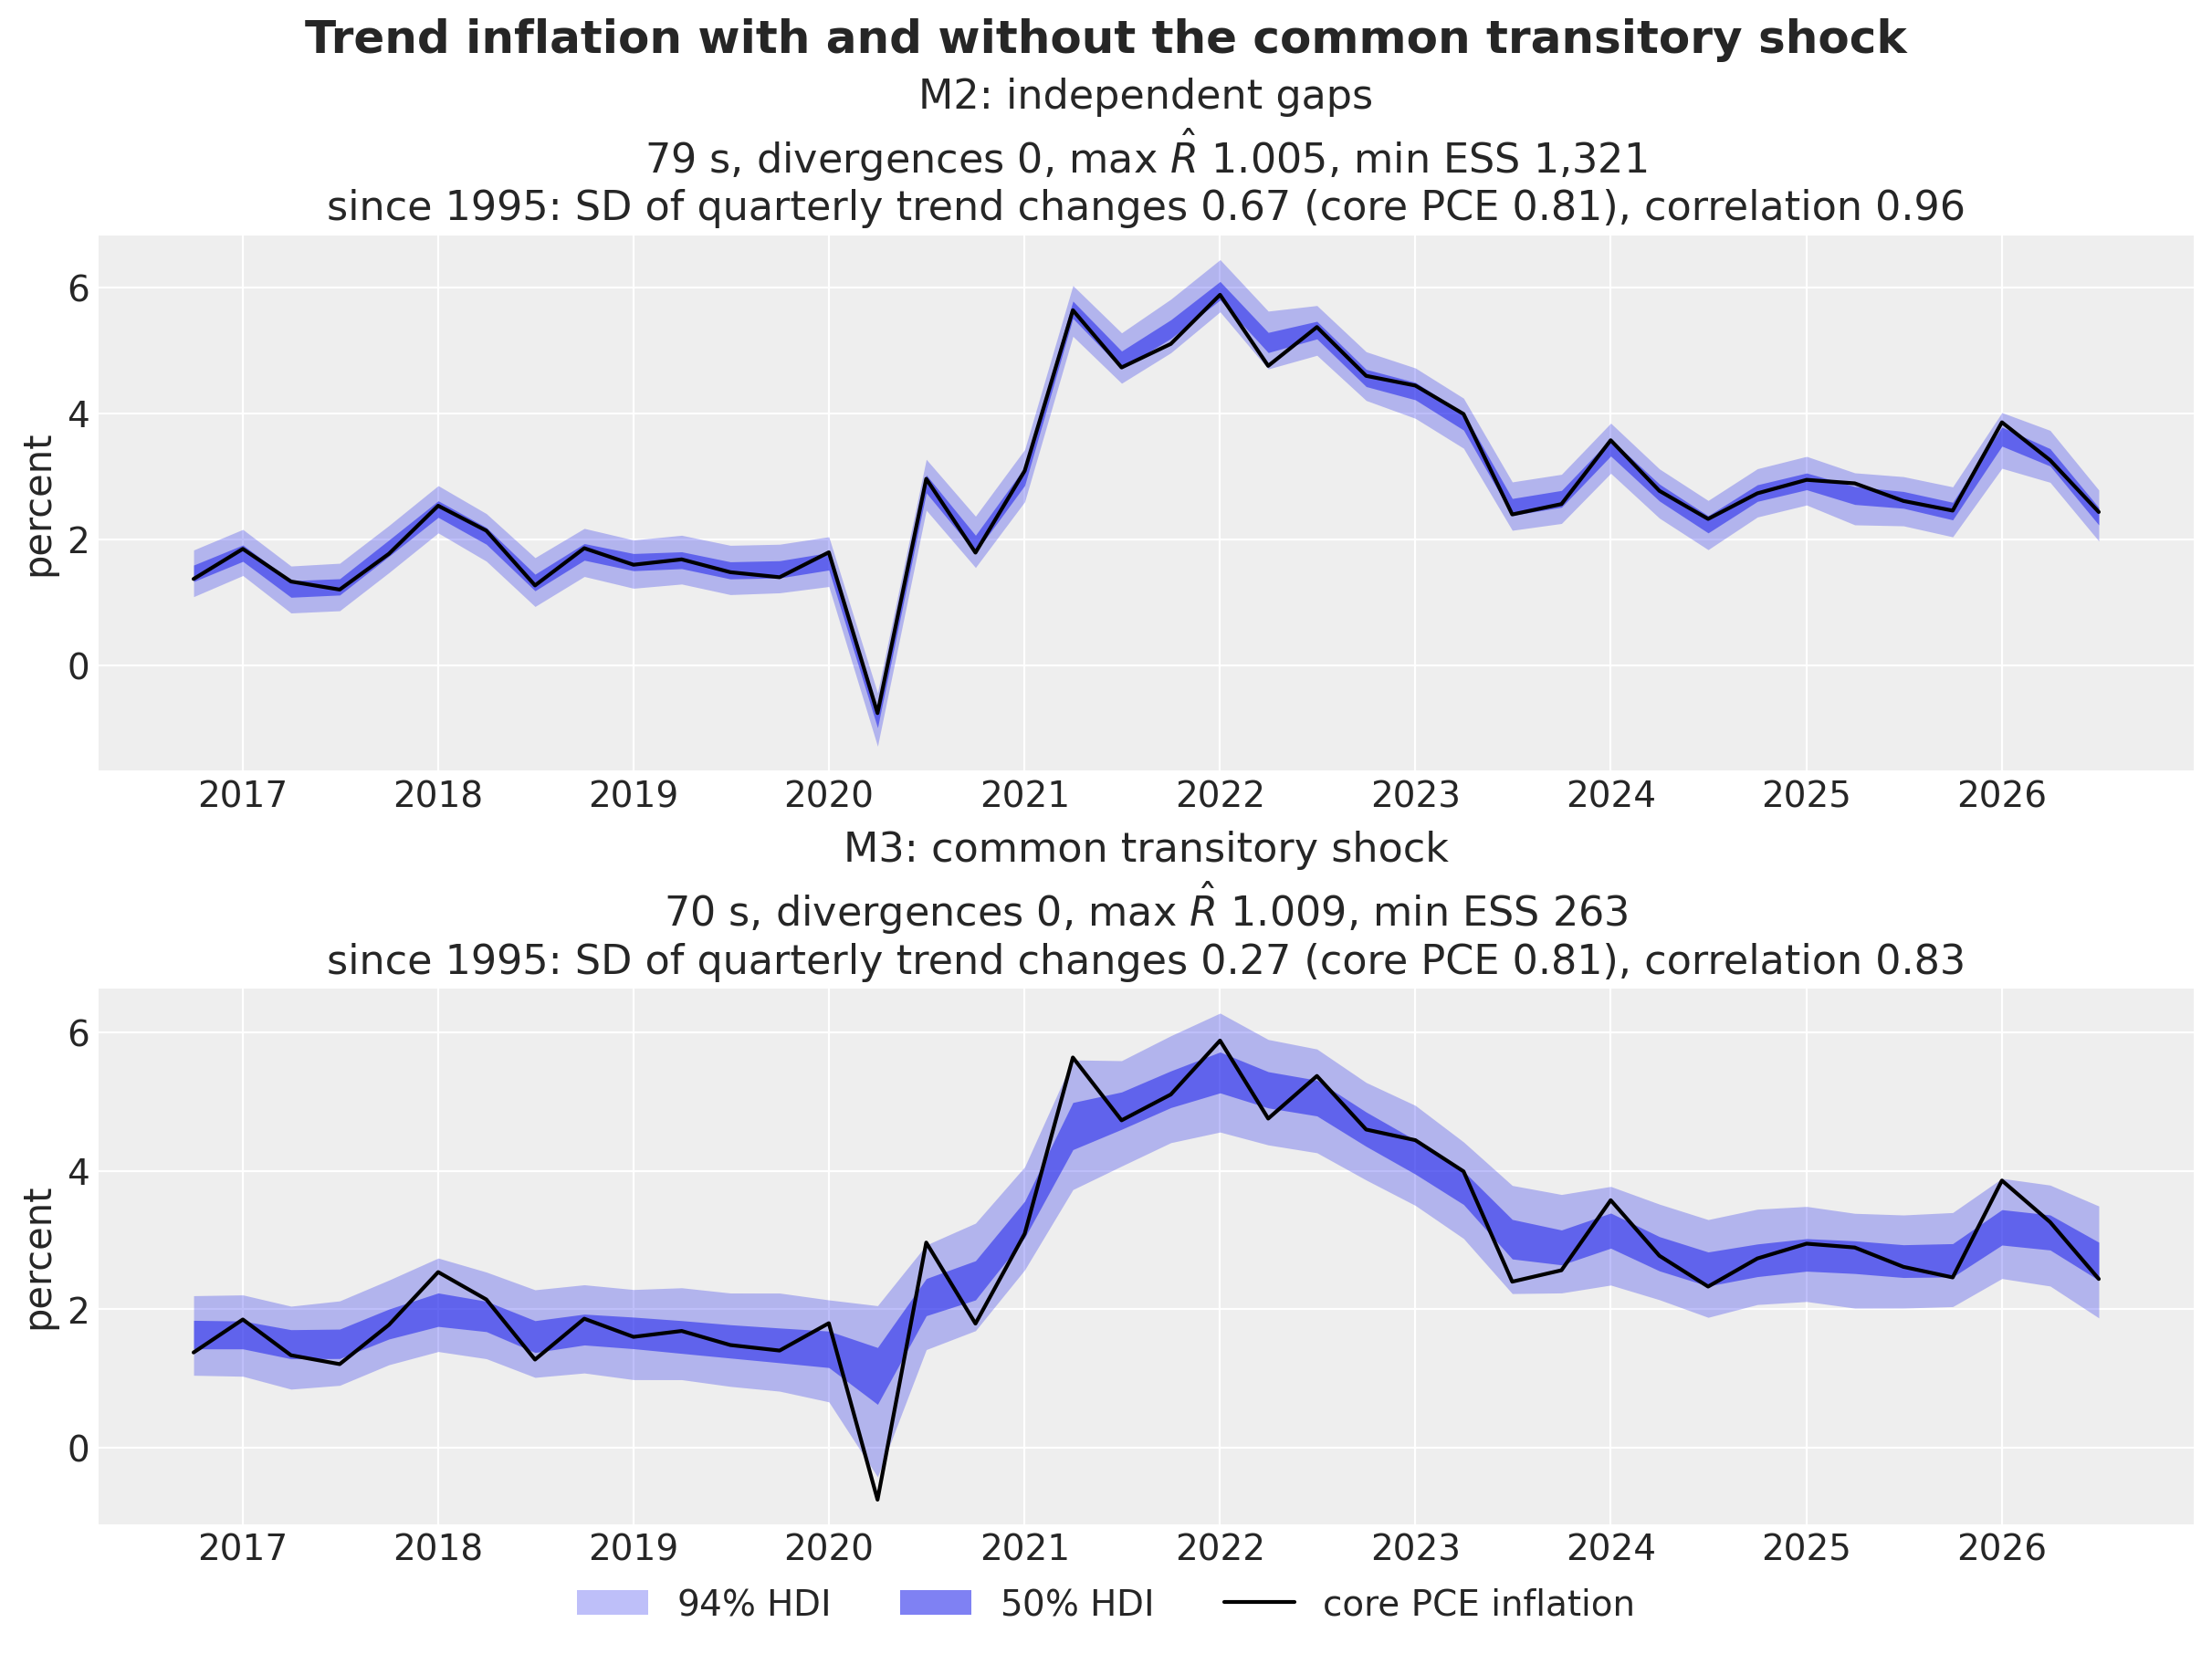

In [11]:
rng_key, key_fit_m2 = random.split(rng_key)
model_m2 = make_trend_inflation_model(num_measures)
mcmc_m2, seconds_m2 = fit_nuts(
    key_fit_m2, model_m2, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)

plot_start = num_quarters - 40
trend_draws_m2 = np.asarray(mcmc_m2.get_samples()["trend"])  # (samples, quarters, 1)
pc, band_handles = plot_bands(
    np.concatenate([trend_draws_m2, trend_draws], axis=-1)[:, plot_start:],
    date_num[plot_start:],
    ["M2: independent gaps", "M3: common transitory shock"],
    figsize=(12, 9),
)
fig = pc.viz["figure"].item()

since_1995 = dates >= np.datetime64("1995-01-01")  # (quarters,)
core_changes_1995 = np.diff(np.asarray(rates[since_1995, -1]))  # (quarters since 1995 - 1,)


def smoothness_label(trend: np.ndarray) -> str:
    # Quarterly changes of the posterior mean trend since 1995 against those of core PCE
    changes = np.diff(trend.mean(axis=0)[since_1995, 0])
    correlation = np.corrcoef(changes, core_changes_1995)[0, 1]
    return (
        f"since 1995: SD of quarterly trend changes {changes.std():.2f} "
        f"(core PCE {core_changes_1995.std():.2f}), correlation {correlation:.2f}"
    )


for ax, title in zip(
    fig.axes,
    (
        fit_title("M2: independent gaps", mcmc_m2, seconds_m2)
        + "\n"
        + smoothness_label(trend_draws_m2),
        fit_title("M3: common transitory shock", mcmc, seconds)
        + "\n"
        + smoothness_label(trend_draws),
    ),
    strict=True,
):
    (core_line,) = ax.plot(
        date_num[plot_start:], rates[plot_start:, -1], color="black", label="core PCE inflation"
    )
    ax.set(title=title, ylabel="percent")

fig.legend(handles=[*band_handles, core_line], loc="outside lower center", ncols=3)
fig.suptitle("Trend inflation with and without the common transitory shock", **TITLE);

The third line of each panel title summarizes the trend since 1995. The trend of M2 changes by $0.67$ percentage points per quarter, close to the $0.81$ of core PCE, and its changes have a correlation of $0.96$ with those of core PCE: without the common shock, the trend is core PCE quarter by quarter, and in 2020Q2 it falls below zero together with core PCE. The trend of M3 changes by $0.27$ points per quarter, with a correlation of $0.83$, and stays near $1\%$ in 2020Q2. The data figure shows why: in 2020Q2 all four measures fell together and rebounded the next quarter, and smaller quarterly moves are shared too. Independent gaps cannot produce a move that all four measures share, so M2 puts every such move into the trend.

The quarterly changes of core PCE give a check of the two decompositions that does not depend on the plot. If the trend is a random walk with shock variance $\sigma^2_{\tau}$ and the transitory part of core PCE is white noise with variance $\sigma^2_{\varepsilon}$, the quarterly change is $\Delta \pi_t = \sigma_{\tau} z_t + \varepsilon_t - \varepsilon_{t-1}$. Its lag-1 autocorrelation is

$$
\rho_1 = \frac{\text{Cov}(\Delta \pi_t, \Delta \pi_{t-1})}{\text{Var}(\Delta \pi_t)} = -\frac{\sigma^2_{\varepsilon}}{\sigma^2_{\tau} + 2 \sigma^2_{\varepsilon}},
$$

close to $0$ when the trend carries the quarterly moves and close to $-0.5$ when the transitory part does. With stochastic volatility the variances change every quarter, so instead of plugging them into the formula we simulate: for every posterior draw we draw one path of quarterly changes since 1985 from that draw's volatilities (for M3 the transitory part of core PCE is the common shock plus its gap) and compute its lag-1 autocorrelation, the same statistic we compute for the data. The histograms are the distribution of that statistic under each model, and the vertical line is the observed value.

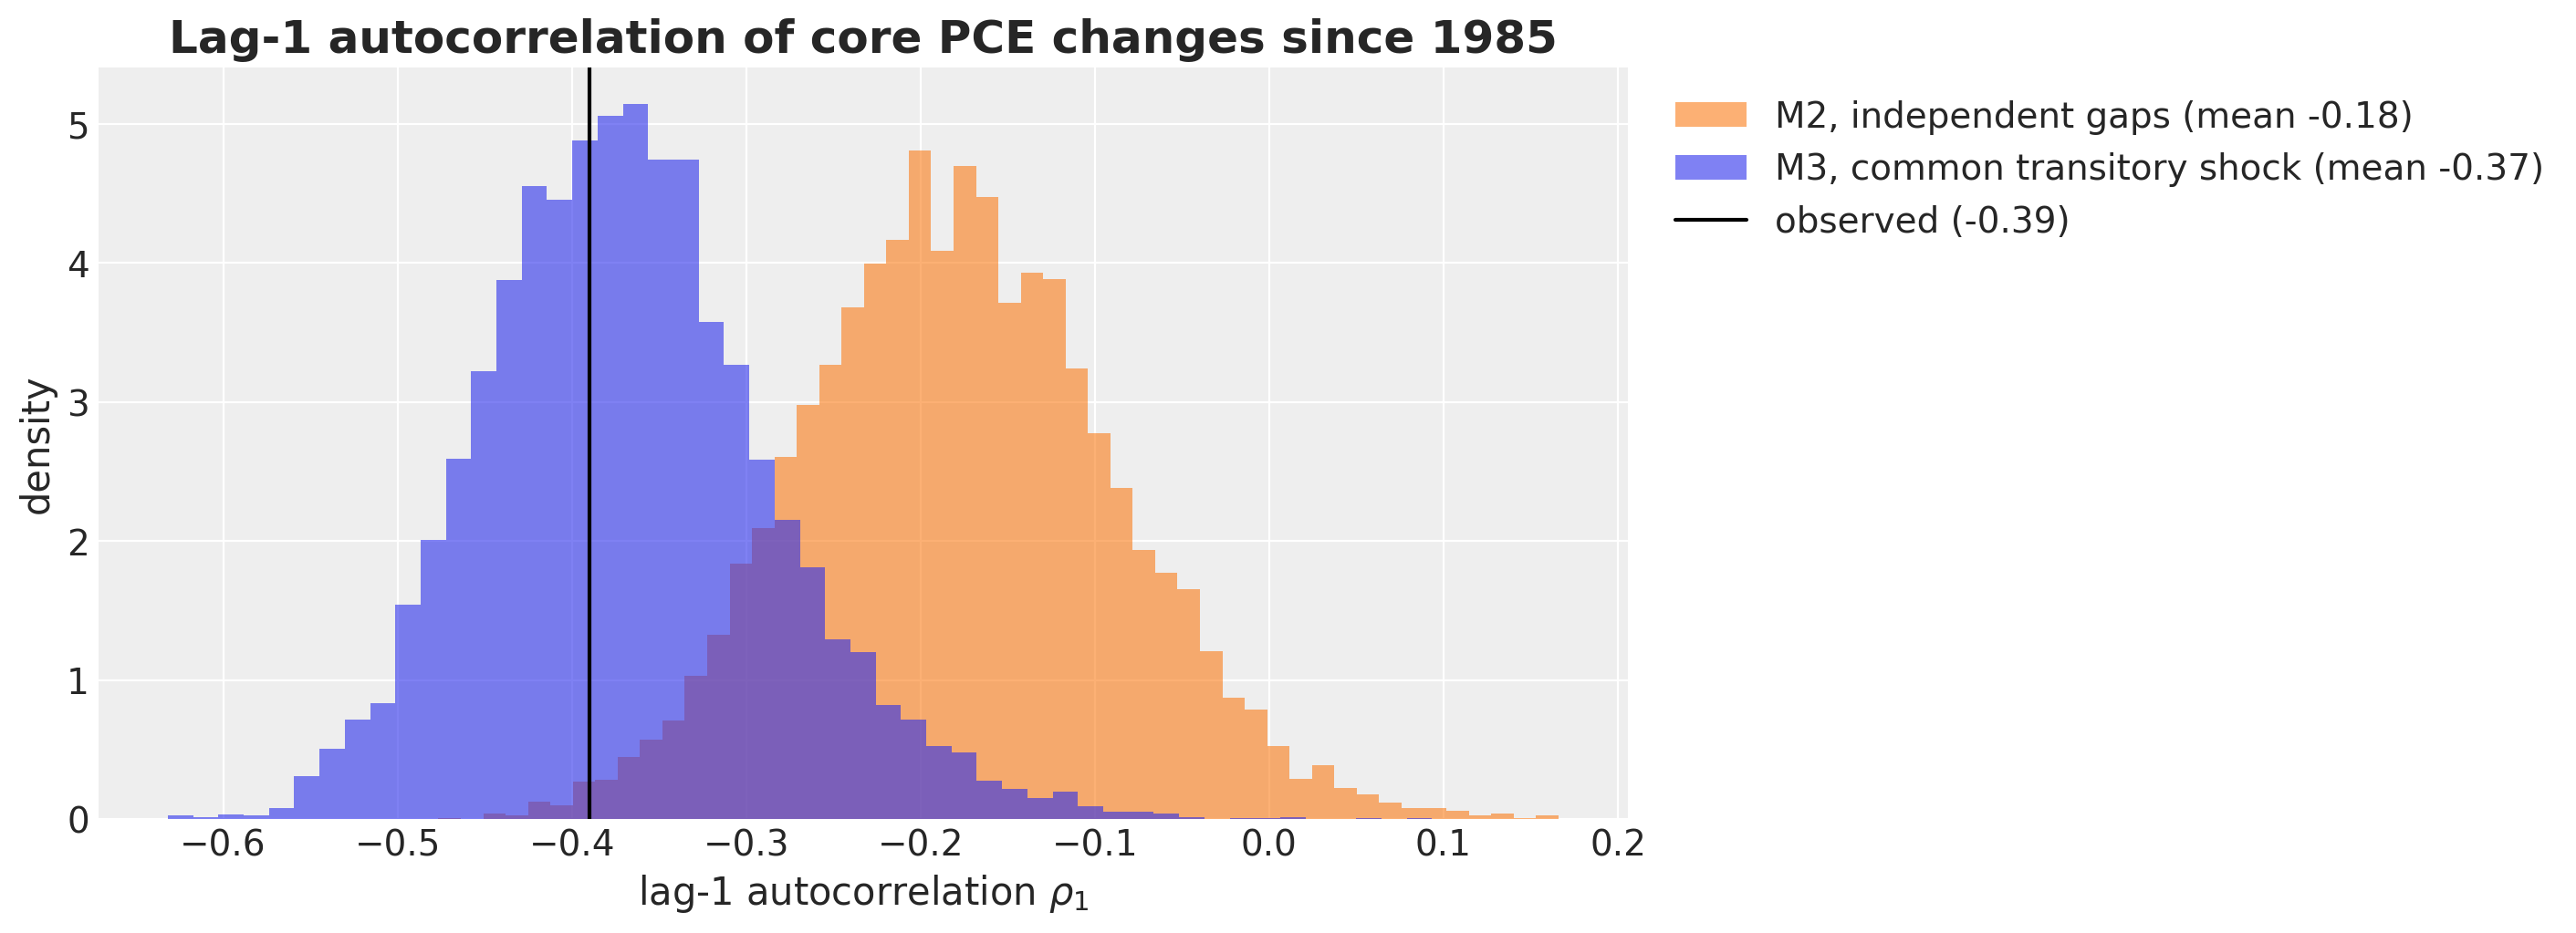

In [12]:
since_1985 = dates >= np.datetime64("1985-01-01")  # (quarters,)


def lag1_autocorrelation(changes: np.ndarray) -> np.ndarray:
    # Sample lag-1 autocorrelation along the last axis: (..., quarters) -> (...)
    centered = changes - changes.mean(axis=-1, keepdims=True)
    lagged = (centered[..., 1:] * centered[..., :-1]).sum(axis=-1)
    return np.asarray(lagged / (centered**2).sum(axis=-1))


def simulated_autocorrelation(rng_key: Array, samples: dict[str, Array]) -> np.ndarray:
    # Volatilities of the trend shock and of the transitory part of core PCE: (draws, quarters)
    trend_vol = np.asarray(samples["trend_vol"])[:, since_1985, 0]
    transitory_var = np.asarray(samples["gap_vol"])[:, since_1985, -1] ** 2

    if "common_vol" in samples:
        transitory_var = transitory_var + np.asarray(samples["common_vol"])[:, since_1985, 0] ** 2

    # One simulated path of quarterly changes per draw: (draws, quarters - 1)
    key_steps, key_transitory = random.split(rng_key)
    trend_steps = trend_vol * np.asarray(random.normal(key_steps, trend_vol.shape))
    transitory = np.sqrt(transitory_var) * np.asarray(
        random.normal(key_transitory, trend_vol.shape)
    )
    changes = trend_steps[:, 1:] + np.diff(transitory, axis=-1)
    return lag1_autocorrelation(changes)  # (draws,)


observed_rho = float(lag1_autocorrelation(np.diff(np.asarray(rates[since_1985, -1]))))
rng_key, key_rho_m2, key_rho_m3 = random.split(rng_key, 3)
simulated_rho = {
    "M2, independent gaps": simulated_autocorrelation(key_rho_m2, mcmc_m2.get_samples()),
    "M3, common transitory shock": simulated_autocorrelation(key_rho_m3, mcmc.get_samples()),
}

fig, ax = plt.subplots(figsize=(14, 5))

for (label, rho), color in zip(simulated_rho.items(), ("C1", "C0"), strict=True):
    ax.hist(
        rho,
        bins=50,
        density=True,
        alpha=0.6,
        color=color,
        label=f"{label} (mean {rho.mean():.2f})",
    )

ax.axvline(observed_rho, color="black", label=f"observed ({observed_rho:.2f})")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(xlabel=r"lag-1 autocorrelation $\rho_1$", ylabel="density")
ax.set_title("Lag-1 autocorrelation of core PCE changes since 1985", **TITLE);

The observed lag-1 autocorrelation of quarterly core PCE changes since 1985 is $-0.39$: a quarter of fast core inflation tends to be followed by a slower one, the mark of a large transitory part. M3 comes close, with a mean of $-0.37$, and the observed value sits near the center of its histogram. M2 puts it at $-0.18$, and the observed value sits in the far left tail of its histogram: a trend that follows every quarter leaves too little transitory noise to produce the negative autocorrelation of the data.

## Volatilities

The model has six volatility paths: one for the trend shock, one for the common transitory shock and one per measure for the gap. The trend volatility says how fast the persistent part of inflation can move in a quarter; the other two say how noisy inflation is around the trend at each date.

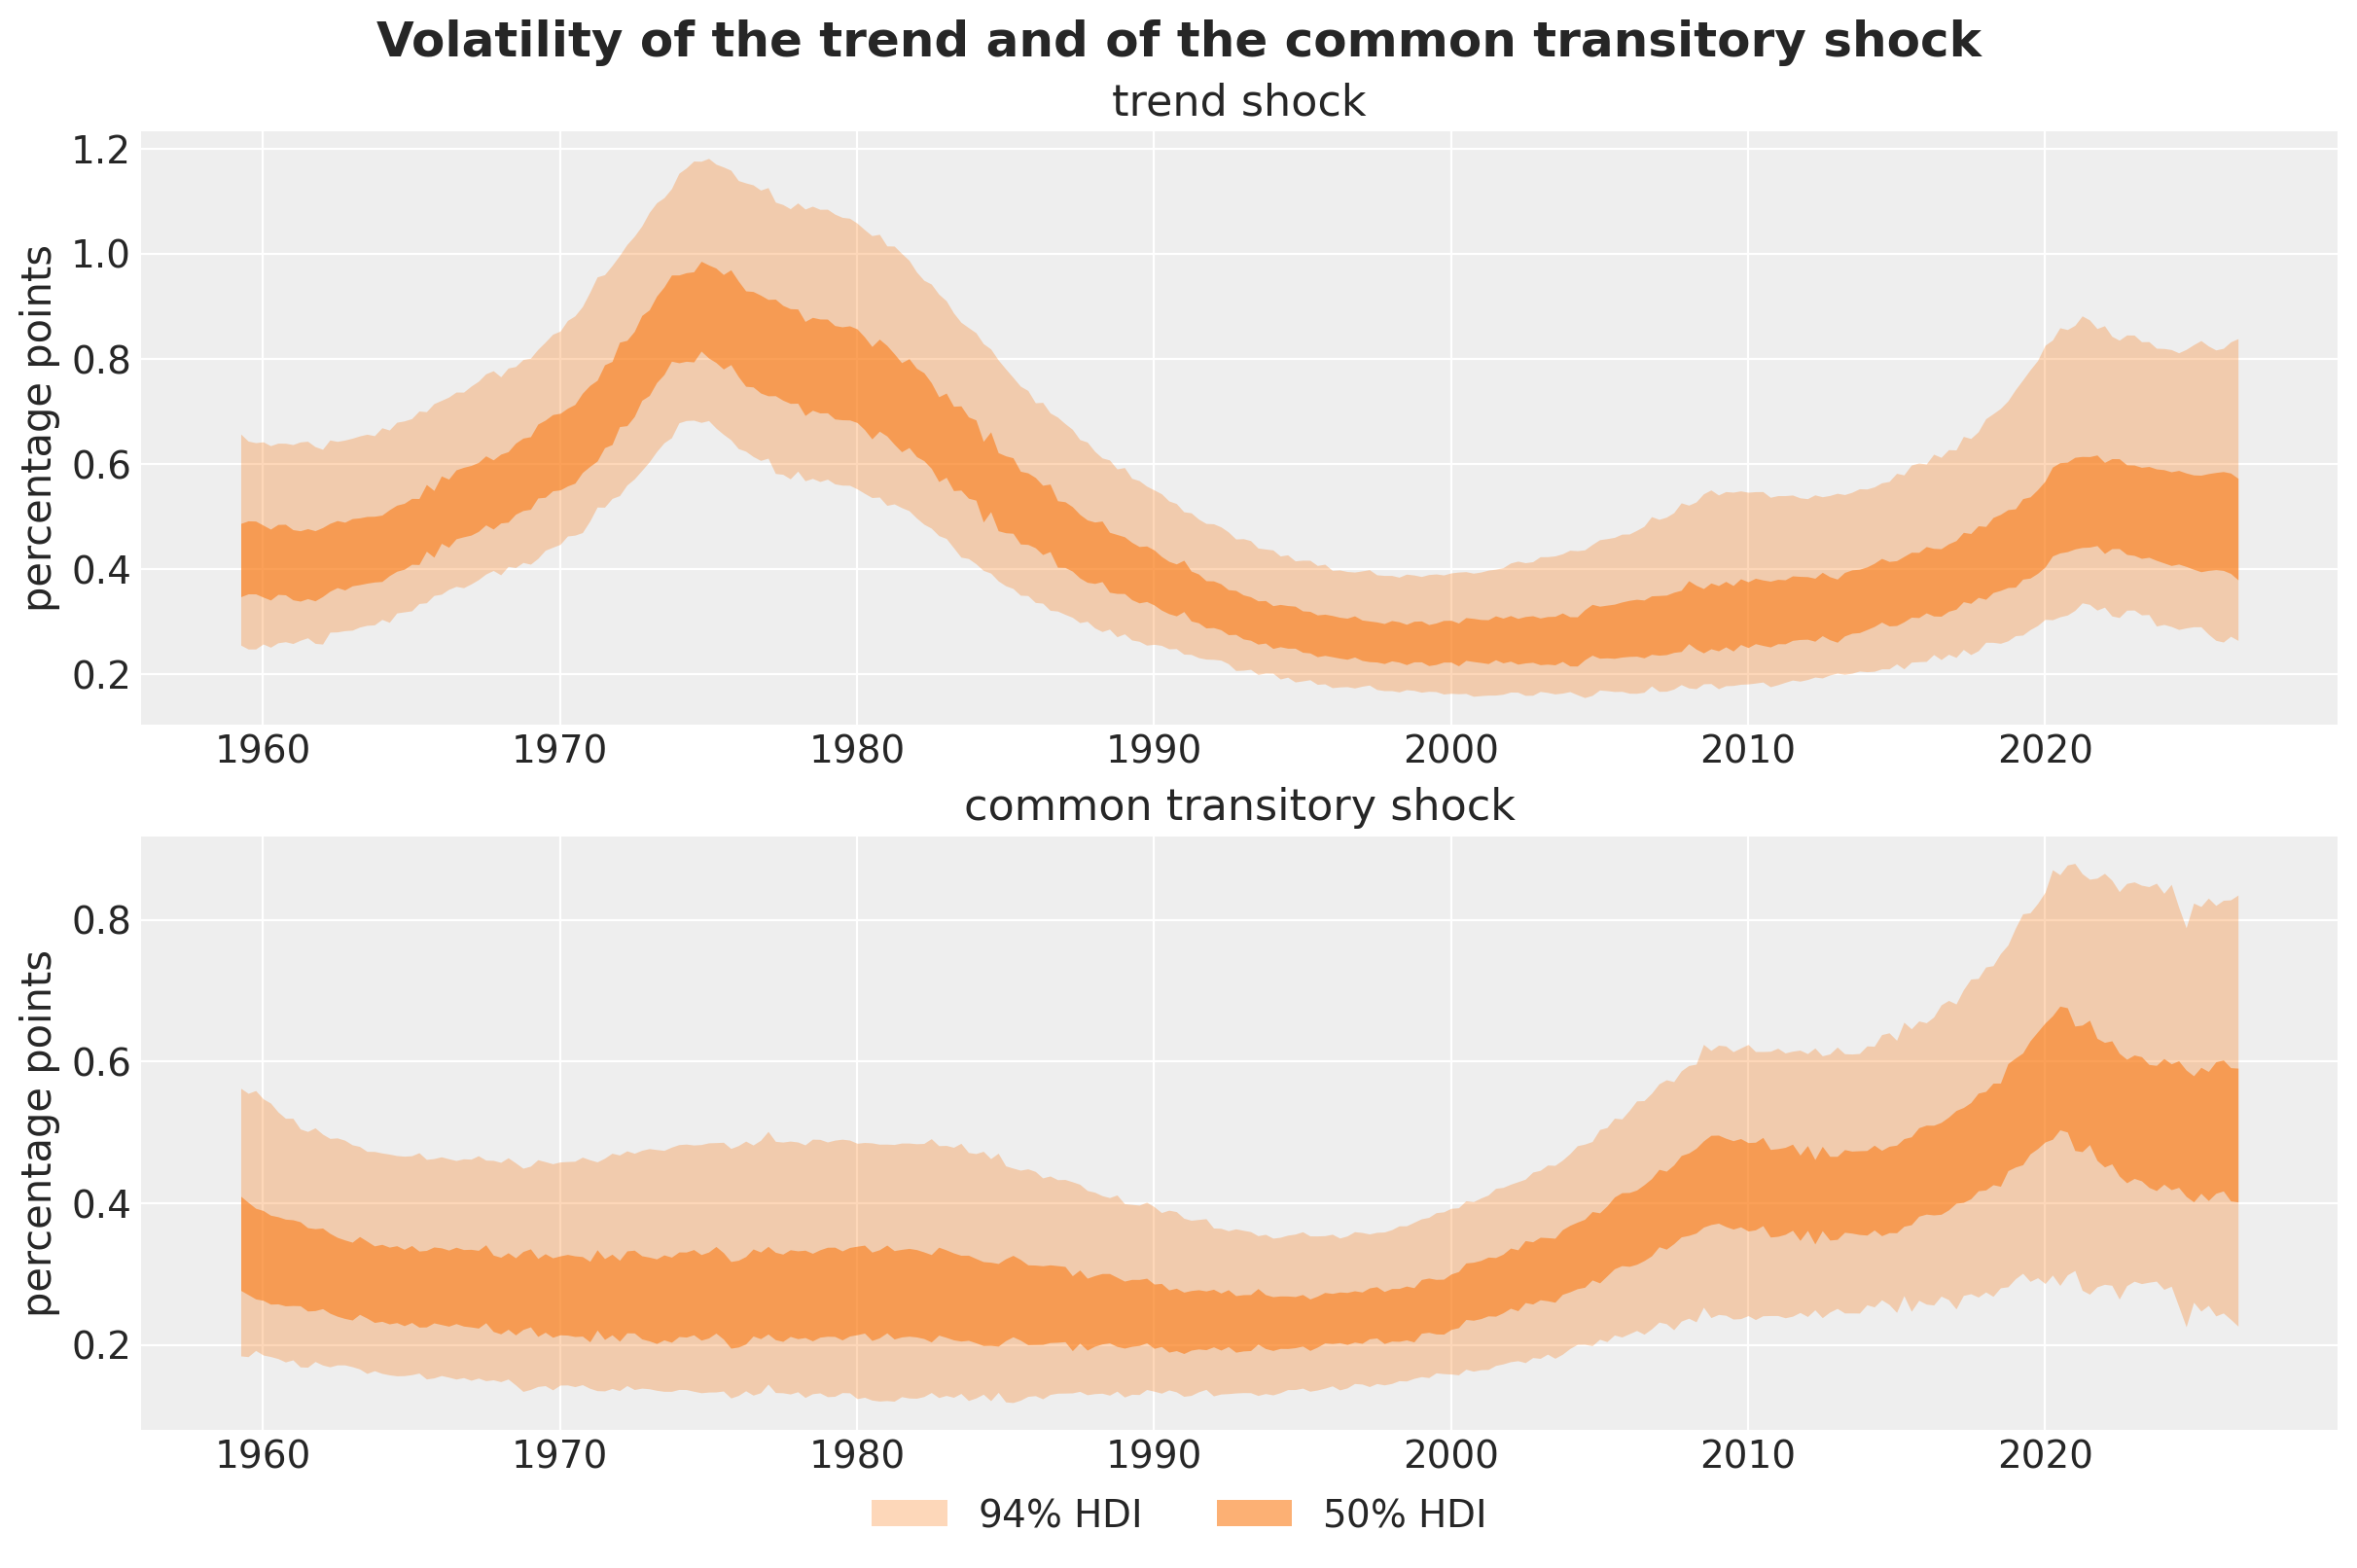

In [13]:
scale_draws = np.concatenate(
    [stack_draws(posterior["trend_vol"]), stack_draws(posterior["common_vol"])], axis=-1
)  # (samples, quarters, 2): trend volatility, then common shock volatility
pc, band_handles = plot_bands(
    scale_draws,
    date_num,
    [r"trend volatility $\exp(h_t / 2)$", r"common shock volatility $\exp(q_t / 2)$"],
    color="C1",
    figsize=(12, 8),
)
fig = pc.viz["figure"].item()

for ax, title in zip(fig.axes, ("trend shock", "common transitory shock"), strict=True):
    ax.set(title=title, ylabel="percentage points")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle("Volatility of the trend and of the common transitory shock", **TITLE);

The two volatilities move at different times:

- The trend volatility, the standard deviation of the quarterly change of the trend, rises from $0.44$ percentage points in 1959 to its maximum of $0.92$ in 1975Q1, falls through the 1980s to $0.30$ in 1995Q1 and to its minimum of $0.27$ in 1999Q1, and climbs again over the next two decades to $0.58$ in 2021Q2. It ends at $0.54$ ($94\%$ HDI $0.26$ to $0.84$).
- The volatility of the common transitory shock starts at $0.37$ in 1959, stays near $0.3$ until the late 1990s, with its minimum of $0.24$ in 1994Q4, and rises after 2000 to $0.43$ in 2008Q4 and to its maximum of $0.58$ in 2020Q2, the quarters with the largest falls of the sample. It ends at $0.52$.

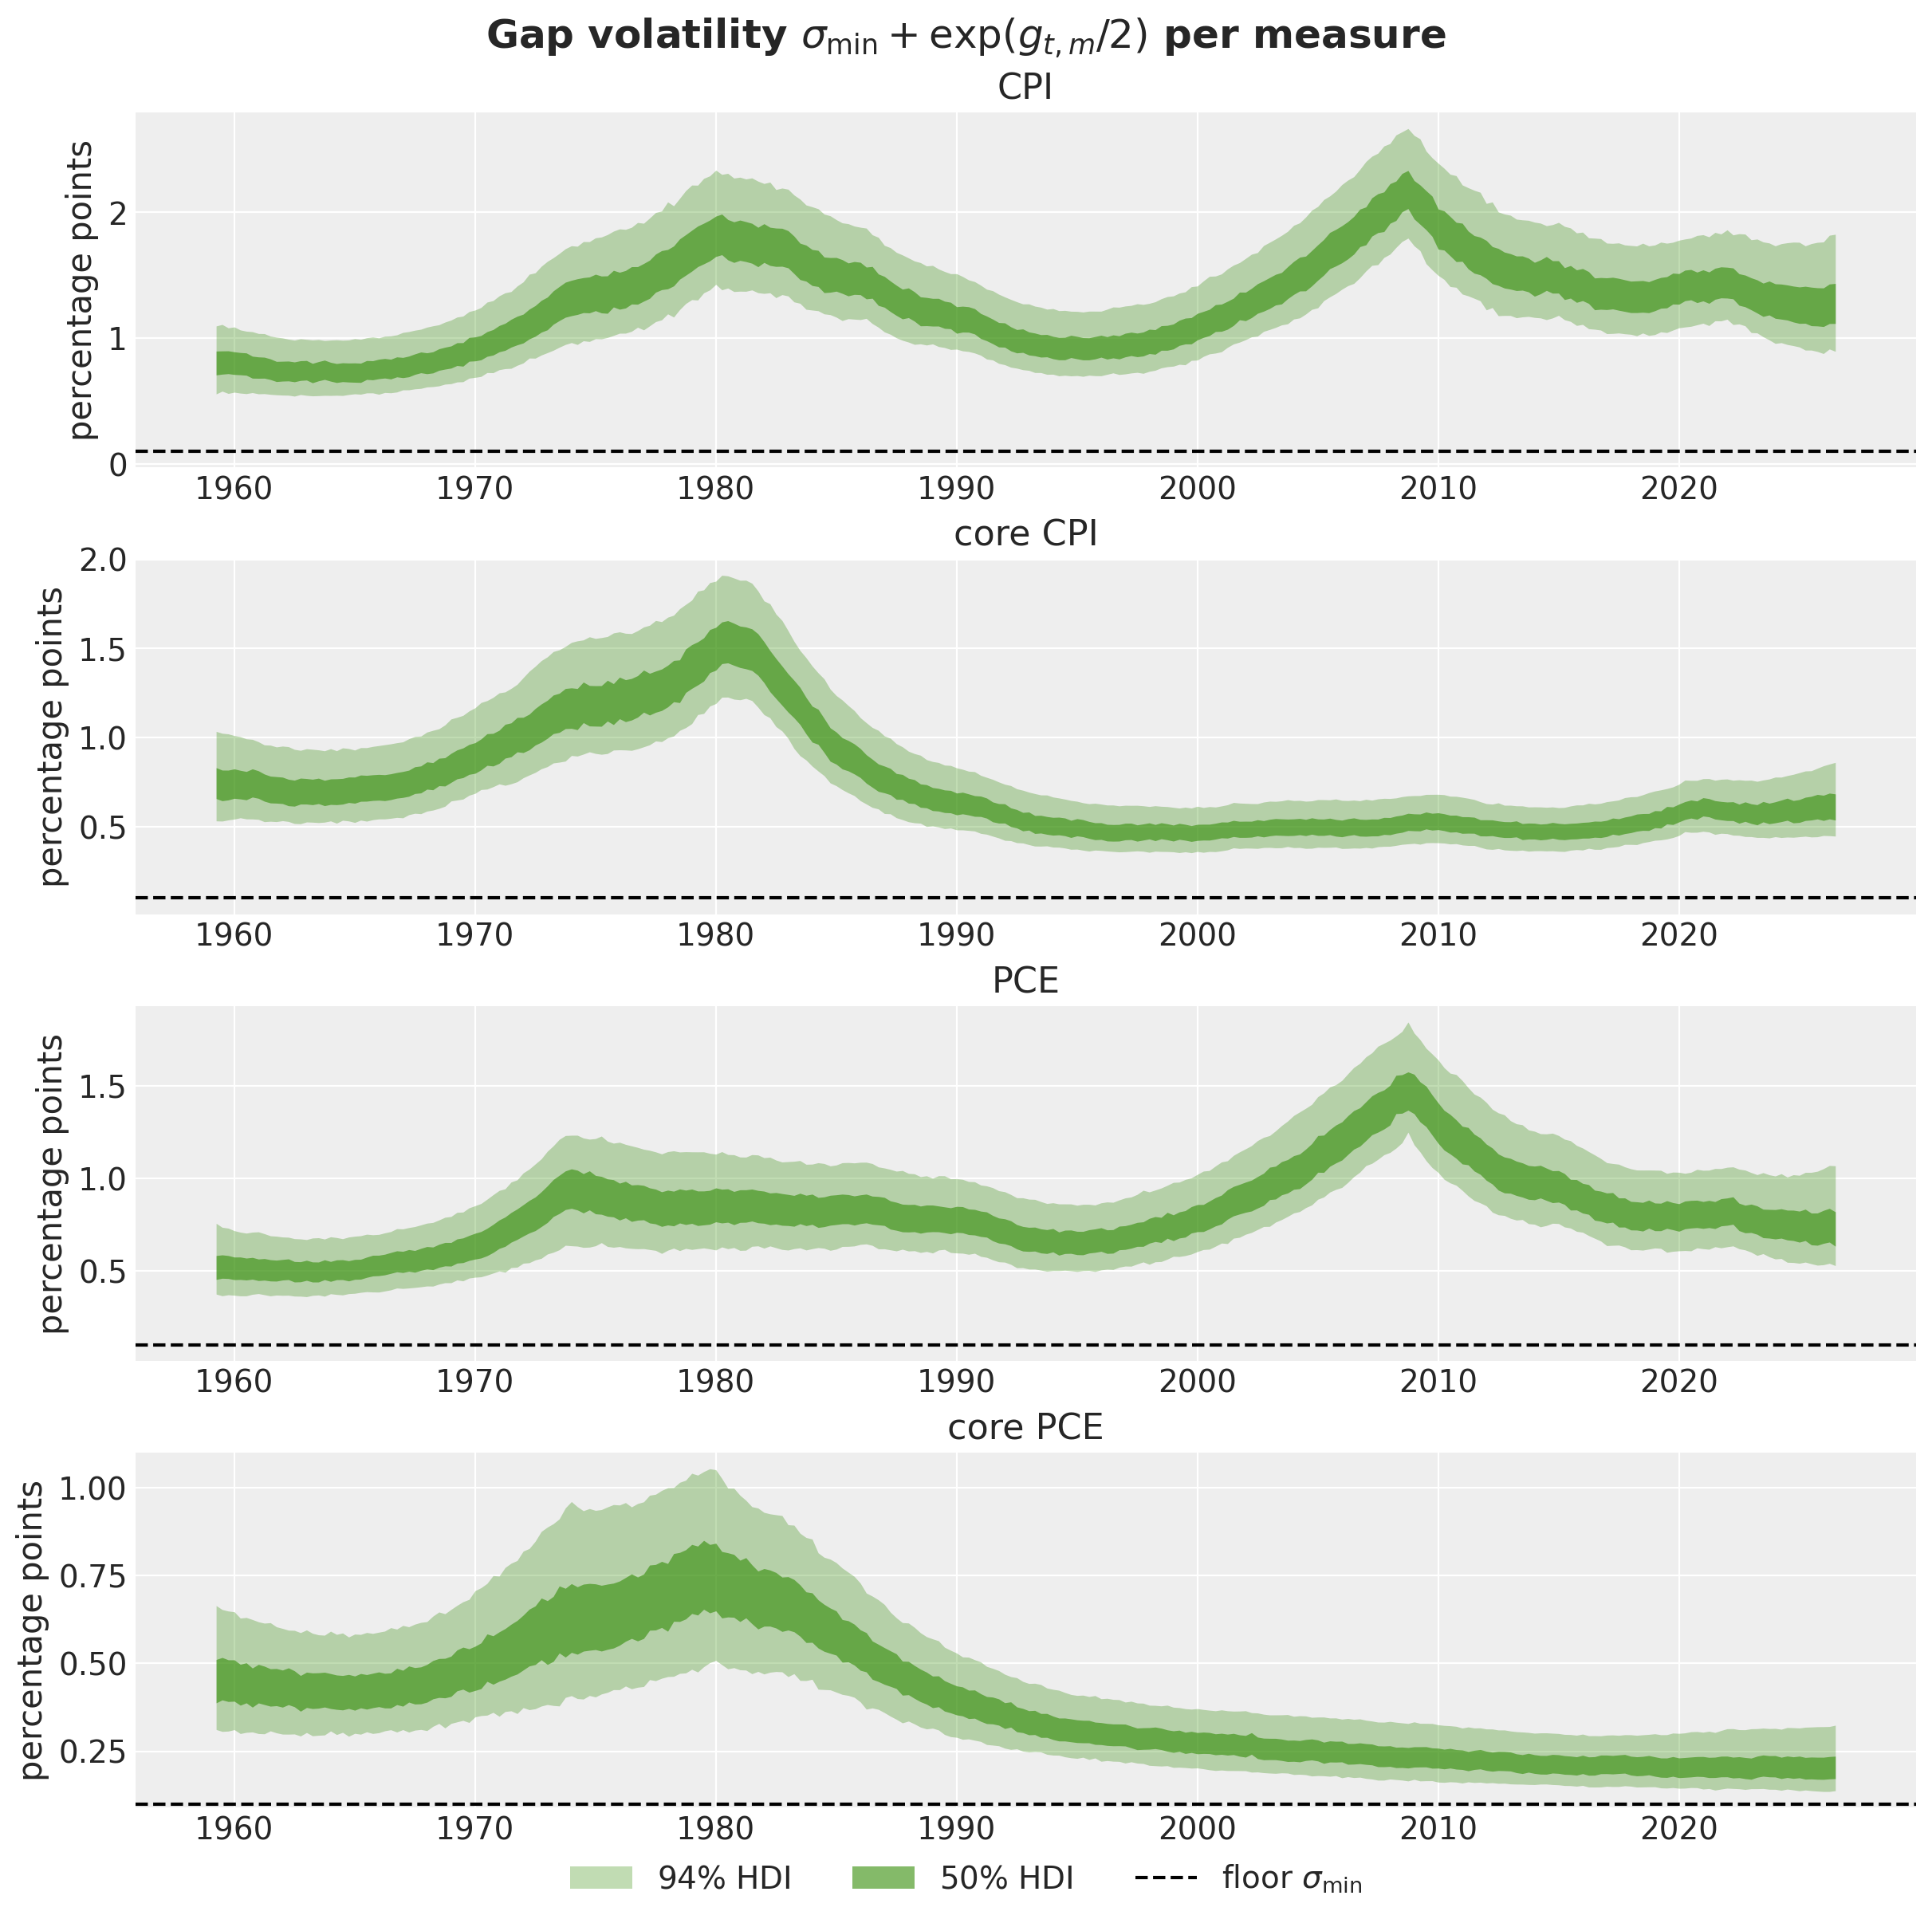

In [14]:
gap_vol_draws = stack_draws(posterior["gap_vol"])  # (samples, quarters, measures)
pc, band_handles = plot_bands(
    gap_vol_draws, date_num, list(measure_labels), color="C2", figsize=(12, 12)
)
fig = pc.viz["figure"].item()

for ax, label in zip(fig.axes, measure_labels, strict=True):
    floor_line = ax.axhline(
        GAP_FLOOR, color="black", linestyle="--", label=r"floor $\sigma_{\min}$"
    )
    ax.set(title=label, ylabel="percentage points")

fig.legend(handles=[*band_handles, floor_line], loc="outside lower center", ncols=3)
fig.suptitle(r"Gap volatility $\sigma_{\min} + \exp(g_{t, m} / 2)$ per measure", **TITLE);

The gap volatilities measure what is left of each measure after the trend and the common shock:

- CPI has the largest and most variable gap: $0.8$ percentage points in 1959, $1.9$ in 1980, $0.95$ in 1995 and $2.2$ at its peak in 2008Q4, the quarter of the oil price collapse; it ends at $1.3$.
- Core CPI peaks at $1.6$ in 1980Q3, falls to its minimum of $0.5$ in 1999 and ends at $0.6$.
- PCE follows CPI with a smaller amplitude: $0.55$ in 1959, $1.5$ at the 2008Q4 peak, $0.8$ at the end.
- Core PCE is the quietest measure: $0.5$ in 1959, $0.8$ at its peak in 1979Q3, and about $0.2$ to $0.3$ from the mid 1990s on, above the floor of $0.1$.

The 2008Q4 peak stays in the two headline gaps with the common shock in the model: the energy collapse moved CPI and PCE far more than the core measures, and a shock with the same loading on every measure can take only the part they share.

## Measure offsets

The offsets are the average wedge of each measure over core PCE in percentage points, the level difference that the trend does not carry.

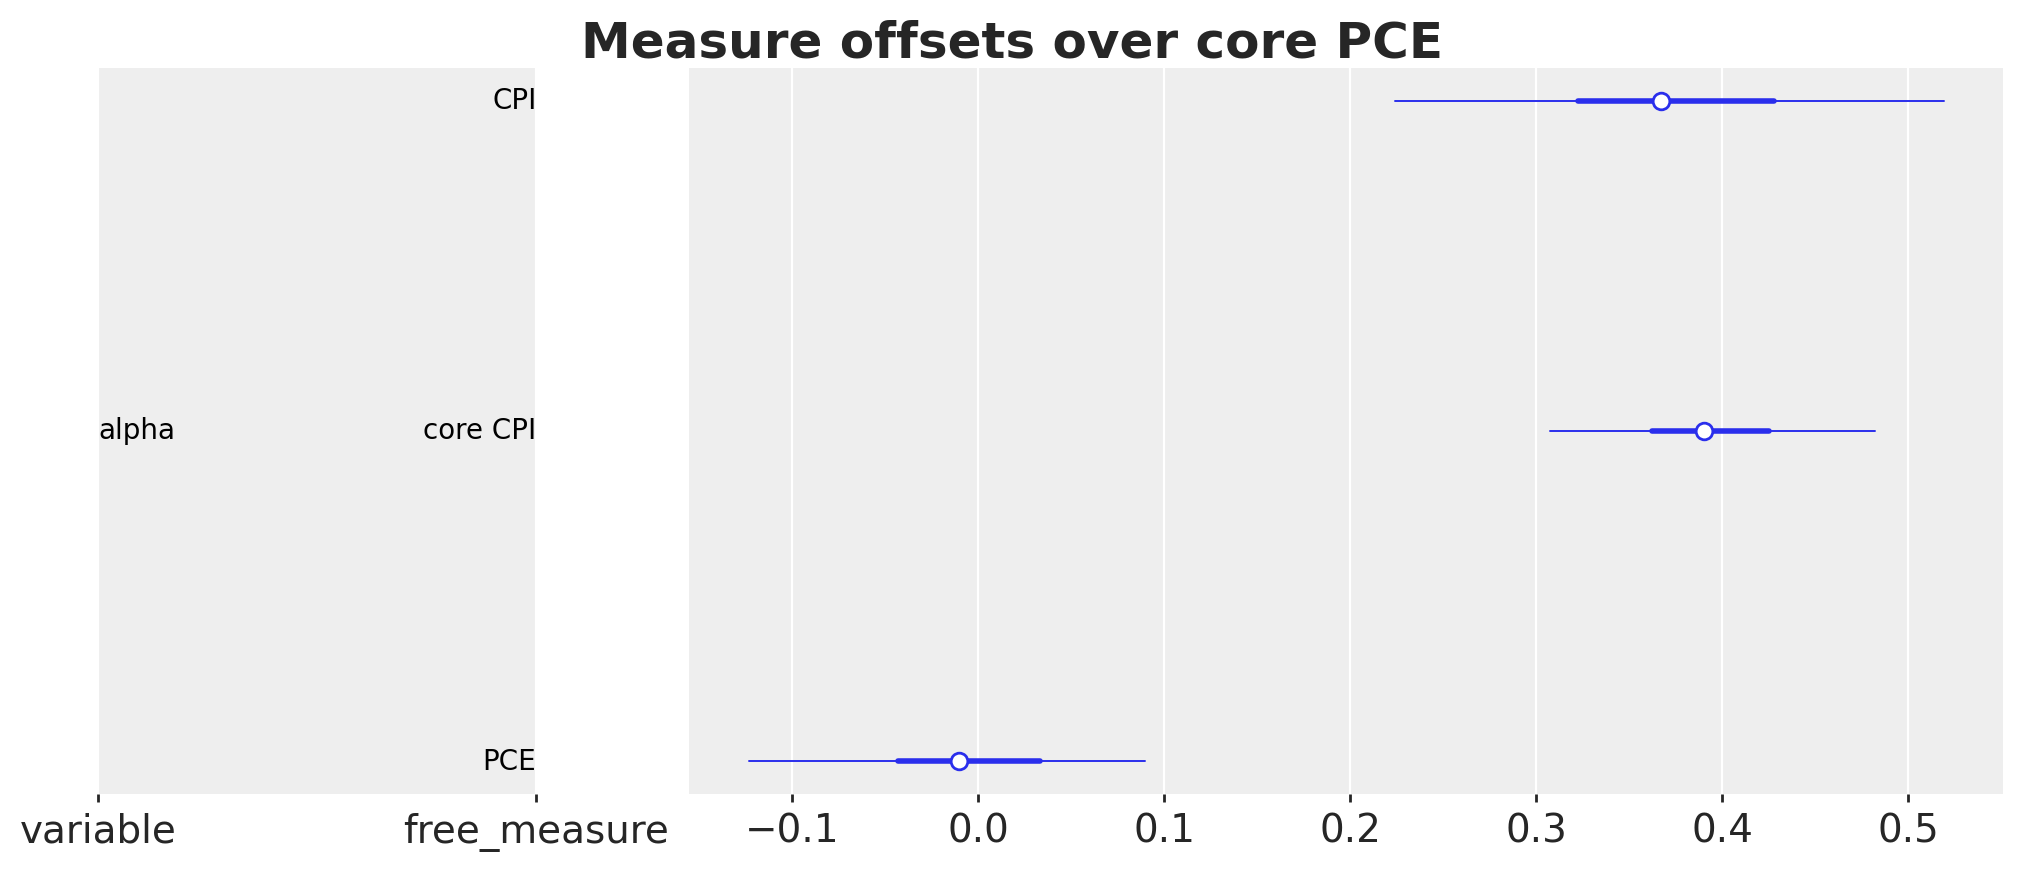

In [15]:
pc = az.plot_forest(tree, var_names=["alpha"], combined=True, figure_kwargs={"figsize": (10, 4)})
pc.viz["figure"].item().suptitle("Measure offsets over core PCE", y=1.05, **TITLE);

The posterior puts the offsets at:

- CPI runs $0.37$ points above core PCE ($94\%$ HDI $0.22$ to $0.52$).
- Core CPI runs $0.39$ points above core PCE ($94\%$ HDI $0.31$ to $0.48$), with the tightest interval, because core CPI has the second smallest gap.
- PCE runs $0.01$ points below core PCE ($94\%$ HDI $-0.12$ to $0.09$): no wedge.

The wedge of about $0.4$ points separates the two CPI measures from the two PCE measures, so it comes from the index formulas and weights and not from food and energy. These are averages over 1959 to 2026; the data figure showed that the CPI wedge was larger before 1983, and a constant offset puts that difference into the trend and the CPI gaps.

## Forecast

The forecast draws the eight future steps of every random walk from the prior of the steps (unit normals) and pushes them through the posterior of the paths at the last observation. The trend continues from its last level, and every log-variance, of the trend, of the common shock and of each gap, keeps moving as a random walk from its last value, so the forecast bands widen with the horizon for two reasons: the trend steps accumulate and the volatilities themselves can drift. `export` already drew the forecast, because `covariates_full` has eight rows more than the data; the `predictions` group of the tree holds it. We plot the last forty quarters of core PCE: the in-sample band is the **smoothed fit**, the posterior predictive given the whole sample, and the forecast band is the predictive from the last observation onward, with its posterior mean.

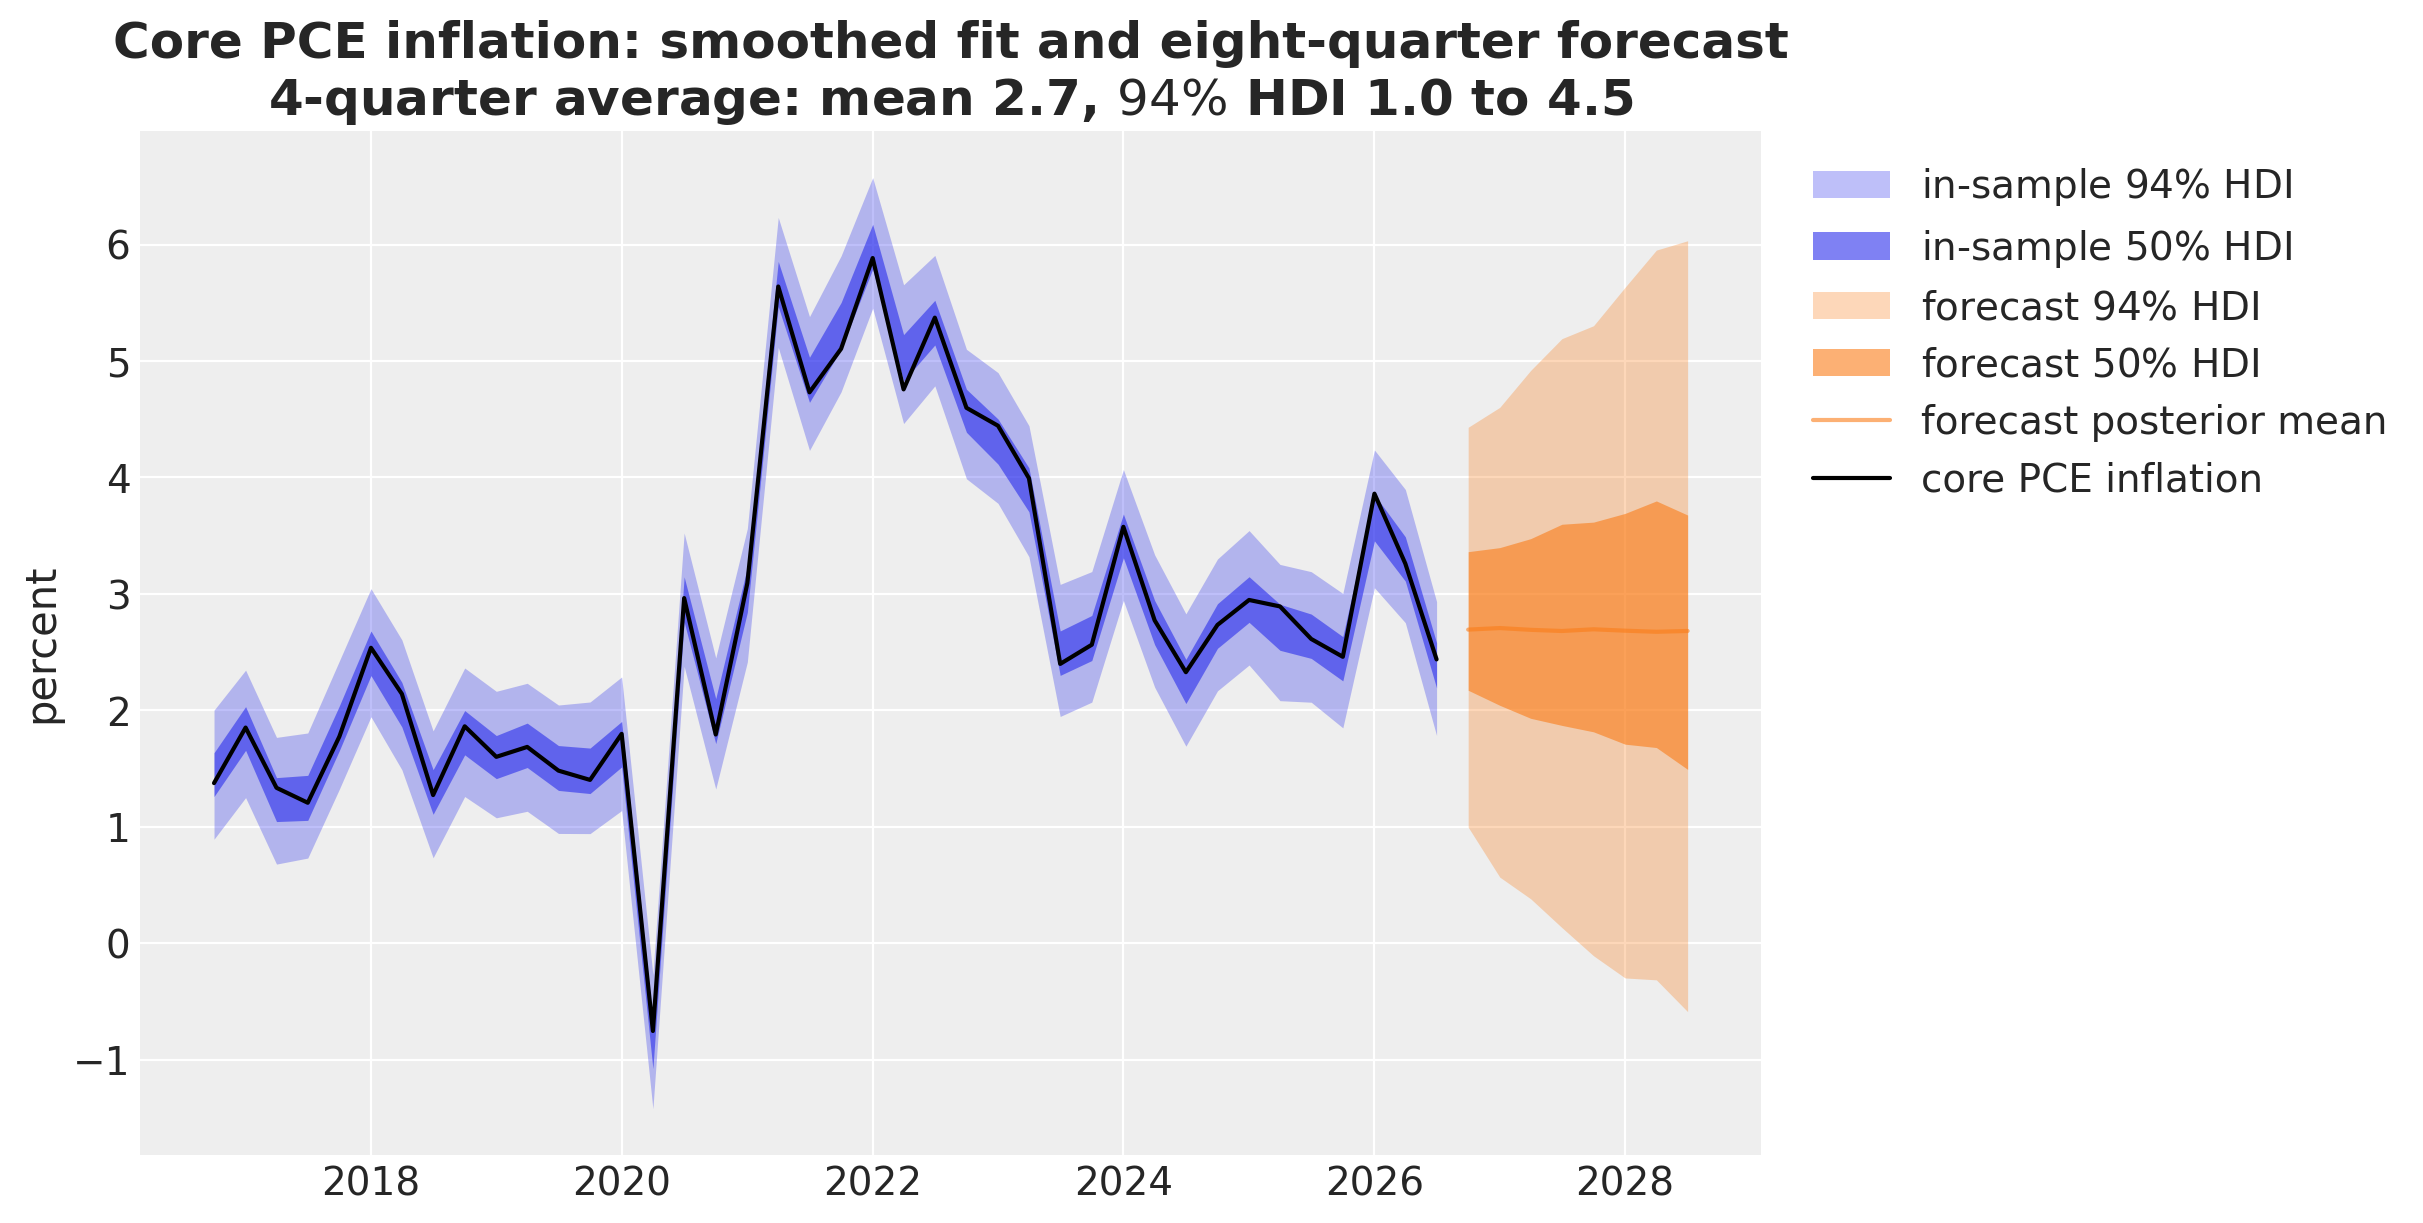

In [16]:
in_sample_draws = stack_draws(tree["posterior_predictive"]["obs"].sel(measure="core PCE"))
forecast_draws = stack_draws(tree["predictions"]["obs"].sel(measure="core PCE"))

pc, in_sample_handles = plot_bands(
    in_sample_draws[:, plot_start:, None], date_num[plot_start:], ["core PCE"], label="in-sample "
)
pc, forecast_handles = plot_bands(
    forecast_draws[:, :, None],
    future_date_num,
    ["core PCE"],
    color="C1",
    label="forecast ",
    mean_line=True,
    plot_collection=pc,
)
ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(
    date_num[plot_start:], rates[plot_start:, -1], color="black", label="core PCE inflation"
)
ax.legend(
    handles=[*in_sample_handles, *forecast_handles, core_line],
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
)
forecast_four_quarter = forecast_draws[:, :4].mean(axis=1)  # (samples,)
lower, upper = az.hdi(forecast_four_quarter, prob=CI_PROB)
ax.set(ylabel="percent")
ax.set_title(
    "Core PCE inflation: smoothed fit and eight-quarter forecast\n"
    rf"4-quarter average: mean {forecast_four_quarter.mean():.1f}, "
    rf"{hdi_label(CI_PROB)} {lower:.1f} to {upper:.1f}",
    **TITLE,
);

The in-sample band is the smoothed fit: given the whole sample, the model knows the trend and the common shock at each date up to their posterior uncertainty, and the $94\%$ band is about $1.2$ percentage points wide in 2026Q3. The forecast band is $3.4$ points wide one quarter ahead, in 2026Q4 ($94\%$ HDI $1.0$ to $4.4$), and $6.6$ points wide eight quarters ahead, in 2028Q3 ($-0.6$ to $6.0$). The posterior mean stays at $2.7\%$, the last level of the trend: a random walk forecasts its last value, and the transitory parts have mean zero. The 4-quarter average over 2026Q4 to 2027Q3, in the title, has a mean of $2.7\%$ and a $94\%$ HDI of $1.0$ to $4.5$.

The forecast of core PCE is the forecast of the trend plus the transitory noise. A `Predictive` call with its own key returns the `trend` site over the full horizon, and its band says how much of the forecast width is the trend itself; the vertical line marks the last observation.

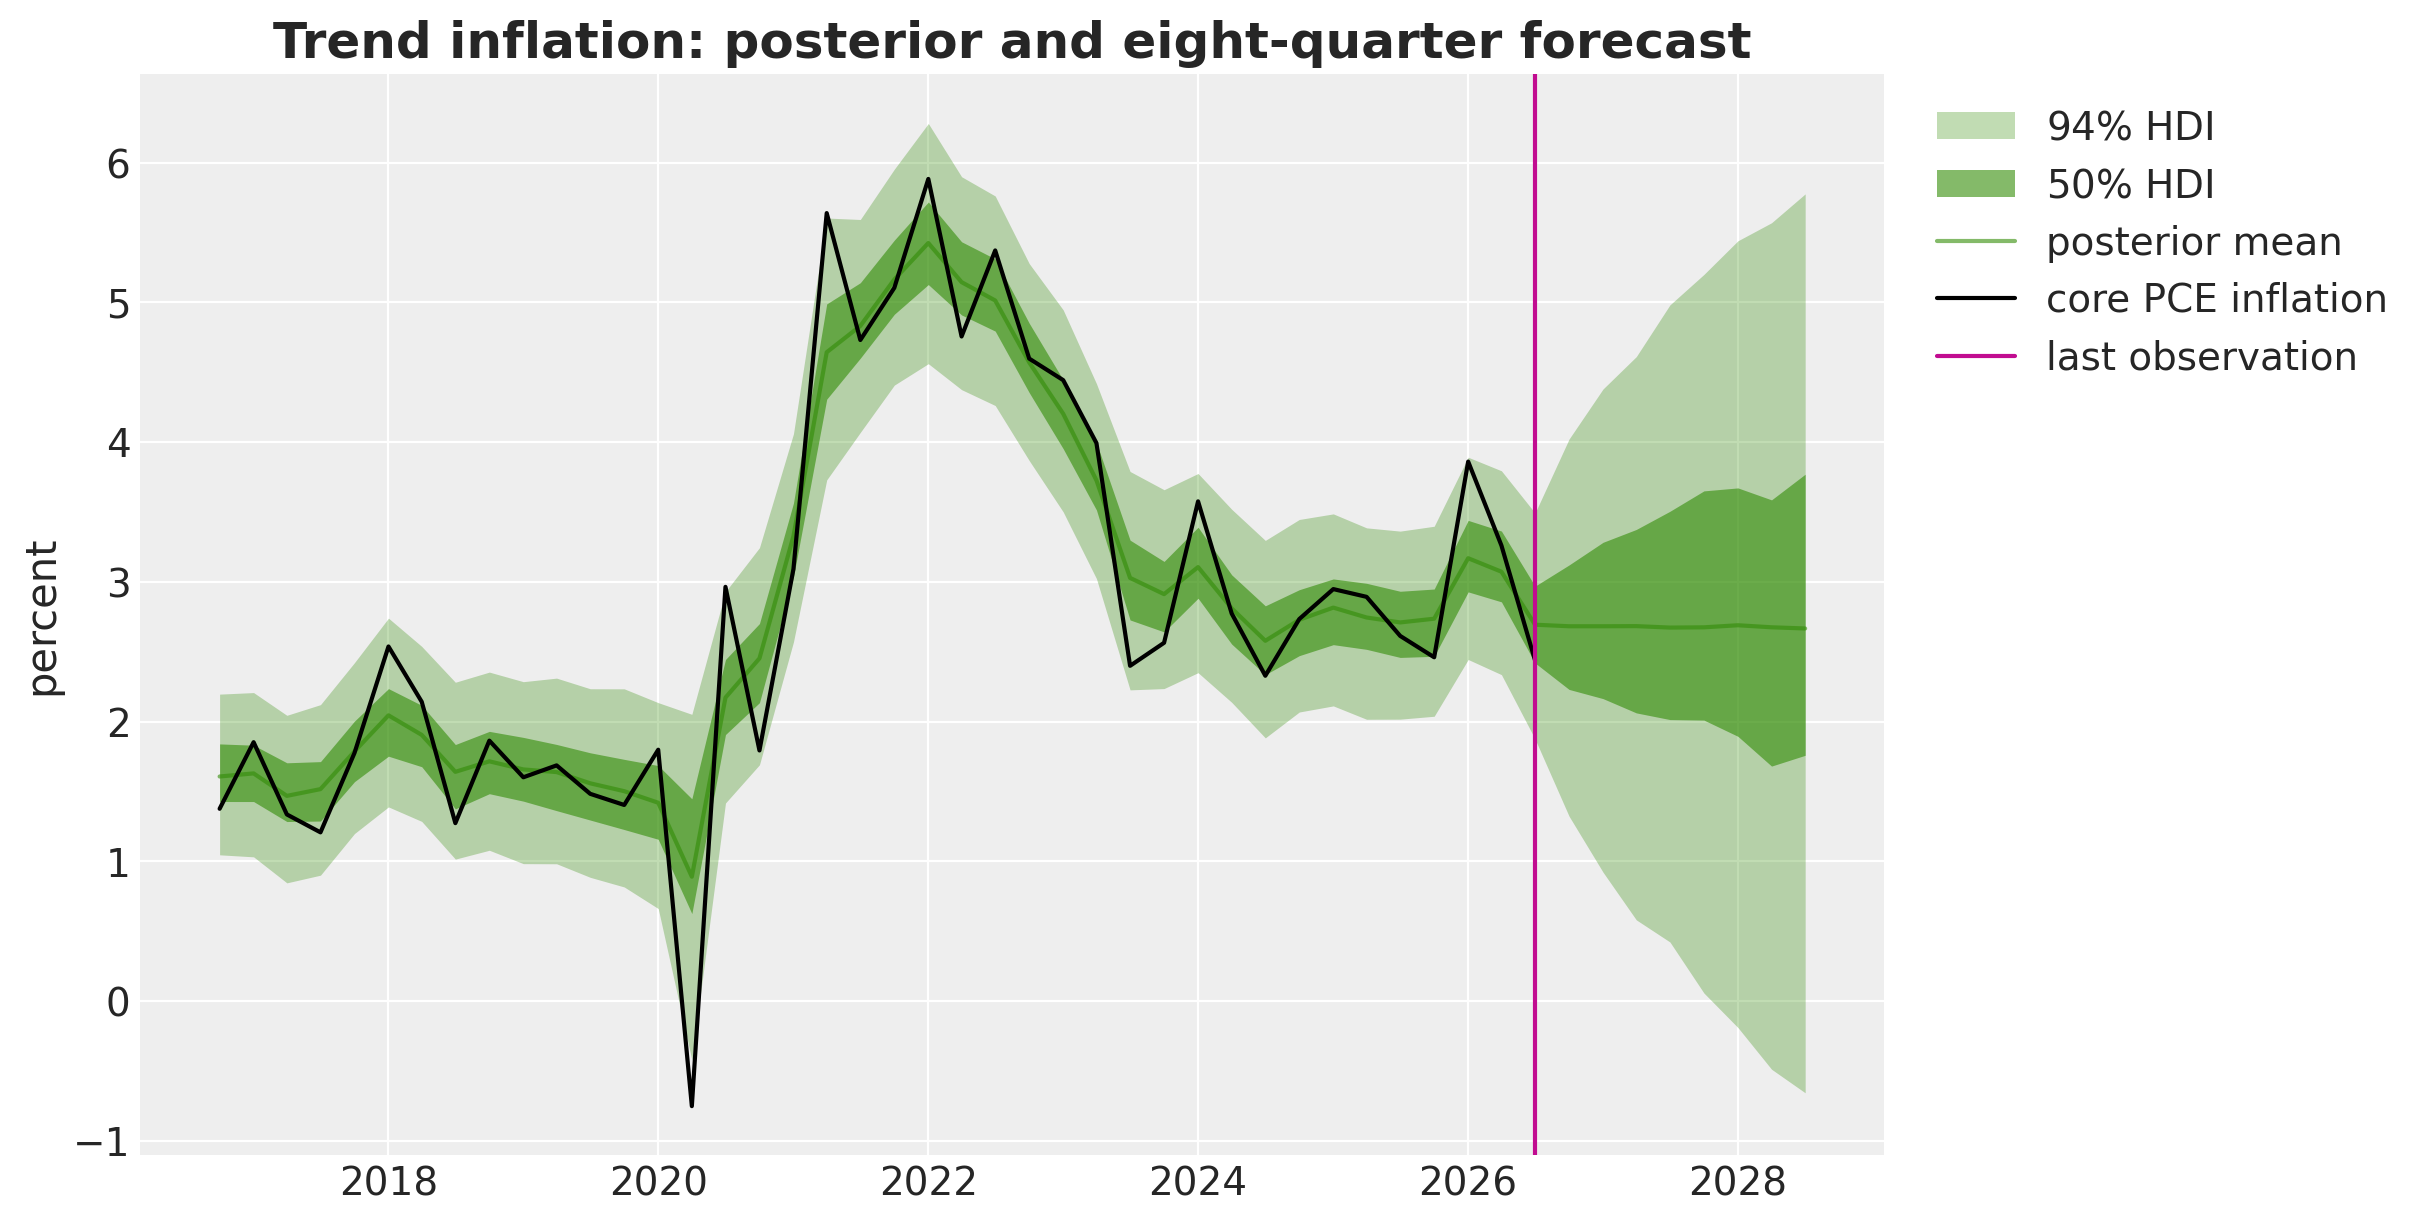

In [17]:
rng_key, key_trend = random.split(rng_key)
trend_horizon = np.asarray(
    Predictive(model, mcmc.get_samples(), return_sites=["trend"])(
        key_trend, covariates_full, rates
    )["trend"]
)  # (samples, quarters + 8, 1)
horizon_date_num = np.concatenate([date_num, future_date_num])

pc, band_handles = plot_bands(
    trend_horizon[:, plot_start:],
    horizon_date_num[plot_start:],
    ["trend"],
    color="C2",
    mean_line=True,
)
ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(
    date_num[plot_start:], rates[plot_start:, -1], color="black", label="core PCE inflation"
)
last_line = ax.axvline(date_num[-1], color="C3", label="last observation")
ax.legend(
    handles=[*band_handles, core_line, last_line], loc="upper left", bbox_to_anchor=(1.01, 1.0)
)
ax.set(ylabel="percent")
ax.set_title("Trend inflation: posterior and eight-quarter forecast", **TITLE);

In sample the trend band is $1.6$ points wide in 2026Q3, wider than the $1.2$ of the smoothed fit of core PCE: the data pin down the sum of the trend and the common shock better than the split between them. Over the horizon the trend band is $2.7$ points wide after one quarter ($1.3$ to $4.0$) and $6.4$ after eight ($-0.7$ to $5.8$). Eight quarters ahead almost all of the forecast width of core PCE, $6.6$ points, is the trend; one quarter ahead the transitory part adds about $0.7$ points.

## Backtest

The forecast from the last observation cannot be scored before 2028. To score the model now we run a rolling-origin evaluation with [`backtest`](../../reference/evaluate.backtest.html): the first forecast origin is 1985Q1, every eighth quarter after it is another origin, the training window expands from the start of the sample to the origin (so each fit uses all the revised data up to that date), and the horizon is eight quarters. That is 20 windows, the last one with origin 2023Q1. With a stride equal to the horizon the windows do not overlap, so every quarter from 1985 to 2024 is scored once.

The ladder has three models and the benchmark:

- **AO**: the Atkeson and Ohanian random walk, a point forecast.
- **M0**: core PCE only, constant variances (`num_measures=1`, `stochastic_volatility=False`).
- **M1**: core PCE only, stochastic volatility: the univariate UCSV model.
- **M3**: all four measures with the common transitory shock, the model of this notebook.

M2 is not in the backtest: the section *The common transitory shock* showed that its trend follows core PCE, and leaving it out keeps the notebook short. The step from M1 to M3 therefore adds two things at once, the three other measures and the common shock, and the backtest cannot tell their contributions apart.

Every window fits the model with four NUTS chains of $500$ warmup and $250$ draws, so that a window takes a fraction of the full fit while the metrics still see $1{,}000$ forecast draws. `forecast_fn` records the divergences of every window, so that the scores can be checked against the fits that produced them. The CRPS and the MAE of *Evaluation metrics and the benchmark* are scored per window, on the core PCE column: `on_core_pce` and `four_quarter_average` turn a package metric into one on that column and on the 4-quarter average, and `atkeson_ohanian` is a per-window metric that reads the last four quarters of the training window through the `per_window_metrics` hook of `backtest`. The coverage comes later, per horizon step, from the stored forecast draws.

In [18]:
BACKTEST_WARMUP = 500
BACKTEST_SAMPLES = 1_000  # 4 chains x 250 draws
backtest_divergences: list[tuple[str, np.datetime64, int]] = []  # (rung, origin, divergences)


def make_forecast_fn(label: str) -> ForecastFn:
    def forecast_fn(
        rng_key: Array,
        model: ForecastModel,
        train_data: Array,
        train_covariates: Array,
        full_covariates: Array,
        num_samples: int,
        *,
        batch_size: int | None = None,
    ) -> Array:
        key_fit, key_forecast = random.split(rng_key)
        mcmc, _ = fit_nuts(
            key_fit,
            model,
            train_data,
            num_warmup=BACKTEST_WARMUP,
            num_samples=num_samples // NUM_CHAINS,
        )
        backtest_divergences.append((label, dates[train_data.shape[0]], num_divergences(mcmc)))
        return forecast(
            key_forecast,
            model,
            mcmc.get_samples(),
            train_data,
            full_covariates,
            batch_size=batch_size,
        )

    return forecast_fn


def on_core_pce(metric: Metric) -> Metric:
    def scored(pred: Array, truth: Array) -> Array:
        return metric(pred[..., -1:], truth[..., -1:])

    return scored


def four_quarter_average(metric: Metric) -> Metric:
    def scored(pred: Array, truth: Array) -> Array:
        return metric(pred[:, :4, -1].mean(axis=-1), truth[:4, -1].mean())

    return scored


def atkeson_ohanian(train: Array) -> tuple[Metric, Metric]:
    # The forecast is the mean core PCE inflation of the last four quarters of `train`, held
    # flat over the horizon; `pred` is ignored.
    point = train[-4:, -1].mean()

    def quarterly(pred: Array, truth: Array) -> Array:
        return jnp.abs(truth[:, -1] - point).mean()

    def annual(pred: Array, truth: Array) -> Array:
        return jnp.abs(truth[:4, -1].mean() - point)

    return quarterly, annual


def benchmark_metrics(t0: int, t1: int, t2: int) -> dict[str, Metric]:
    quarterly, annual = atkeson_ohanian(rates[t0:t1])
    return {"mae_ao": quarterly, "mae_4q_ao": annual}


METRICS = {
    "crps": on_core_pce(eval_crps),
    "mae": on_core_pce(eval_mae),
    "crps_4q": four_quarter_average(eval_crps),
    "mae_4q": four_quarter_average(eval_mae),
}
BACKTEST_OPTIONS = {
    "min_train_window": 103,  # first origin 1985Q1
    "test_window": HORIZON,
    "stride": HORIZON,  # windows do not overlap
    "num_samples": BACKTEST_SAMPLES,
    "metrics": METRICS,
    "per_window_metrics": benchmark_metrics,
    "keep_predictions": True,
}

assert dates[BACKTEST_OPTIONS["min_train_window"]] == np.datetime64("1985-01-01")


def run_backtest(
    rng_key: Array, label: str, model_fn: ModelFactory, data: Array
) -> list[BacktestResult]:
    return backtest(
        rng_key,
        model_fn,
        data,
        jnp.zeros((data.shape[0], 0)),
        forecast_fn=make_forecast_fn(label),
        **BACKTEST_OPTIONS,
    )

In [19]:
core_pce = rates[:, -1:]  # (quarters, 1): the univariate rungs see core PCE only
LADDER: dict[str, tuple[ModelFactory, Array]] = {
    "M0": (partial(make_trend_inflation_model, 1, stochastic_volatility=False), core_pce),
    "M1": (partial(make_trend_inflation_model, 1), core_pce),
    "M3": (partial(make_trend_inflation_model, num_measures, common_transitory=True), rates),
}
RUNG_COLORS = {"AO": "C4", "M0": "C1", "M1": "C2", "M3": "C0"}
backtest_results: dict[str, list[BacktestResult]] = {}

for label, (model_fn, data) in LADDER.items():
    rng_key, key_backtest = random.split(rng_key)
    backtest_results[label] = run_backtest(key_backtest, label, model_fn, data)

origins = np.array([dates[result.t1] for result in backtest_results["M3"]])

assert len(origins) == 20

The first figure is the summary: every metric averaged over the 20 windows, one bar per model, with the Atkeson and Ohanian benchmark as a line in the MAE panels.

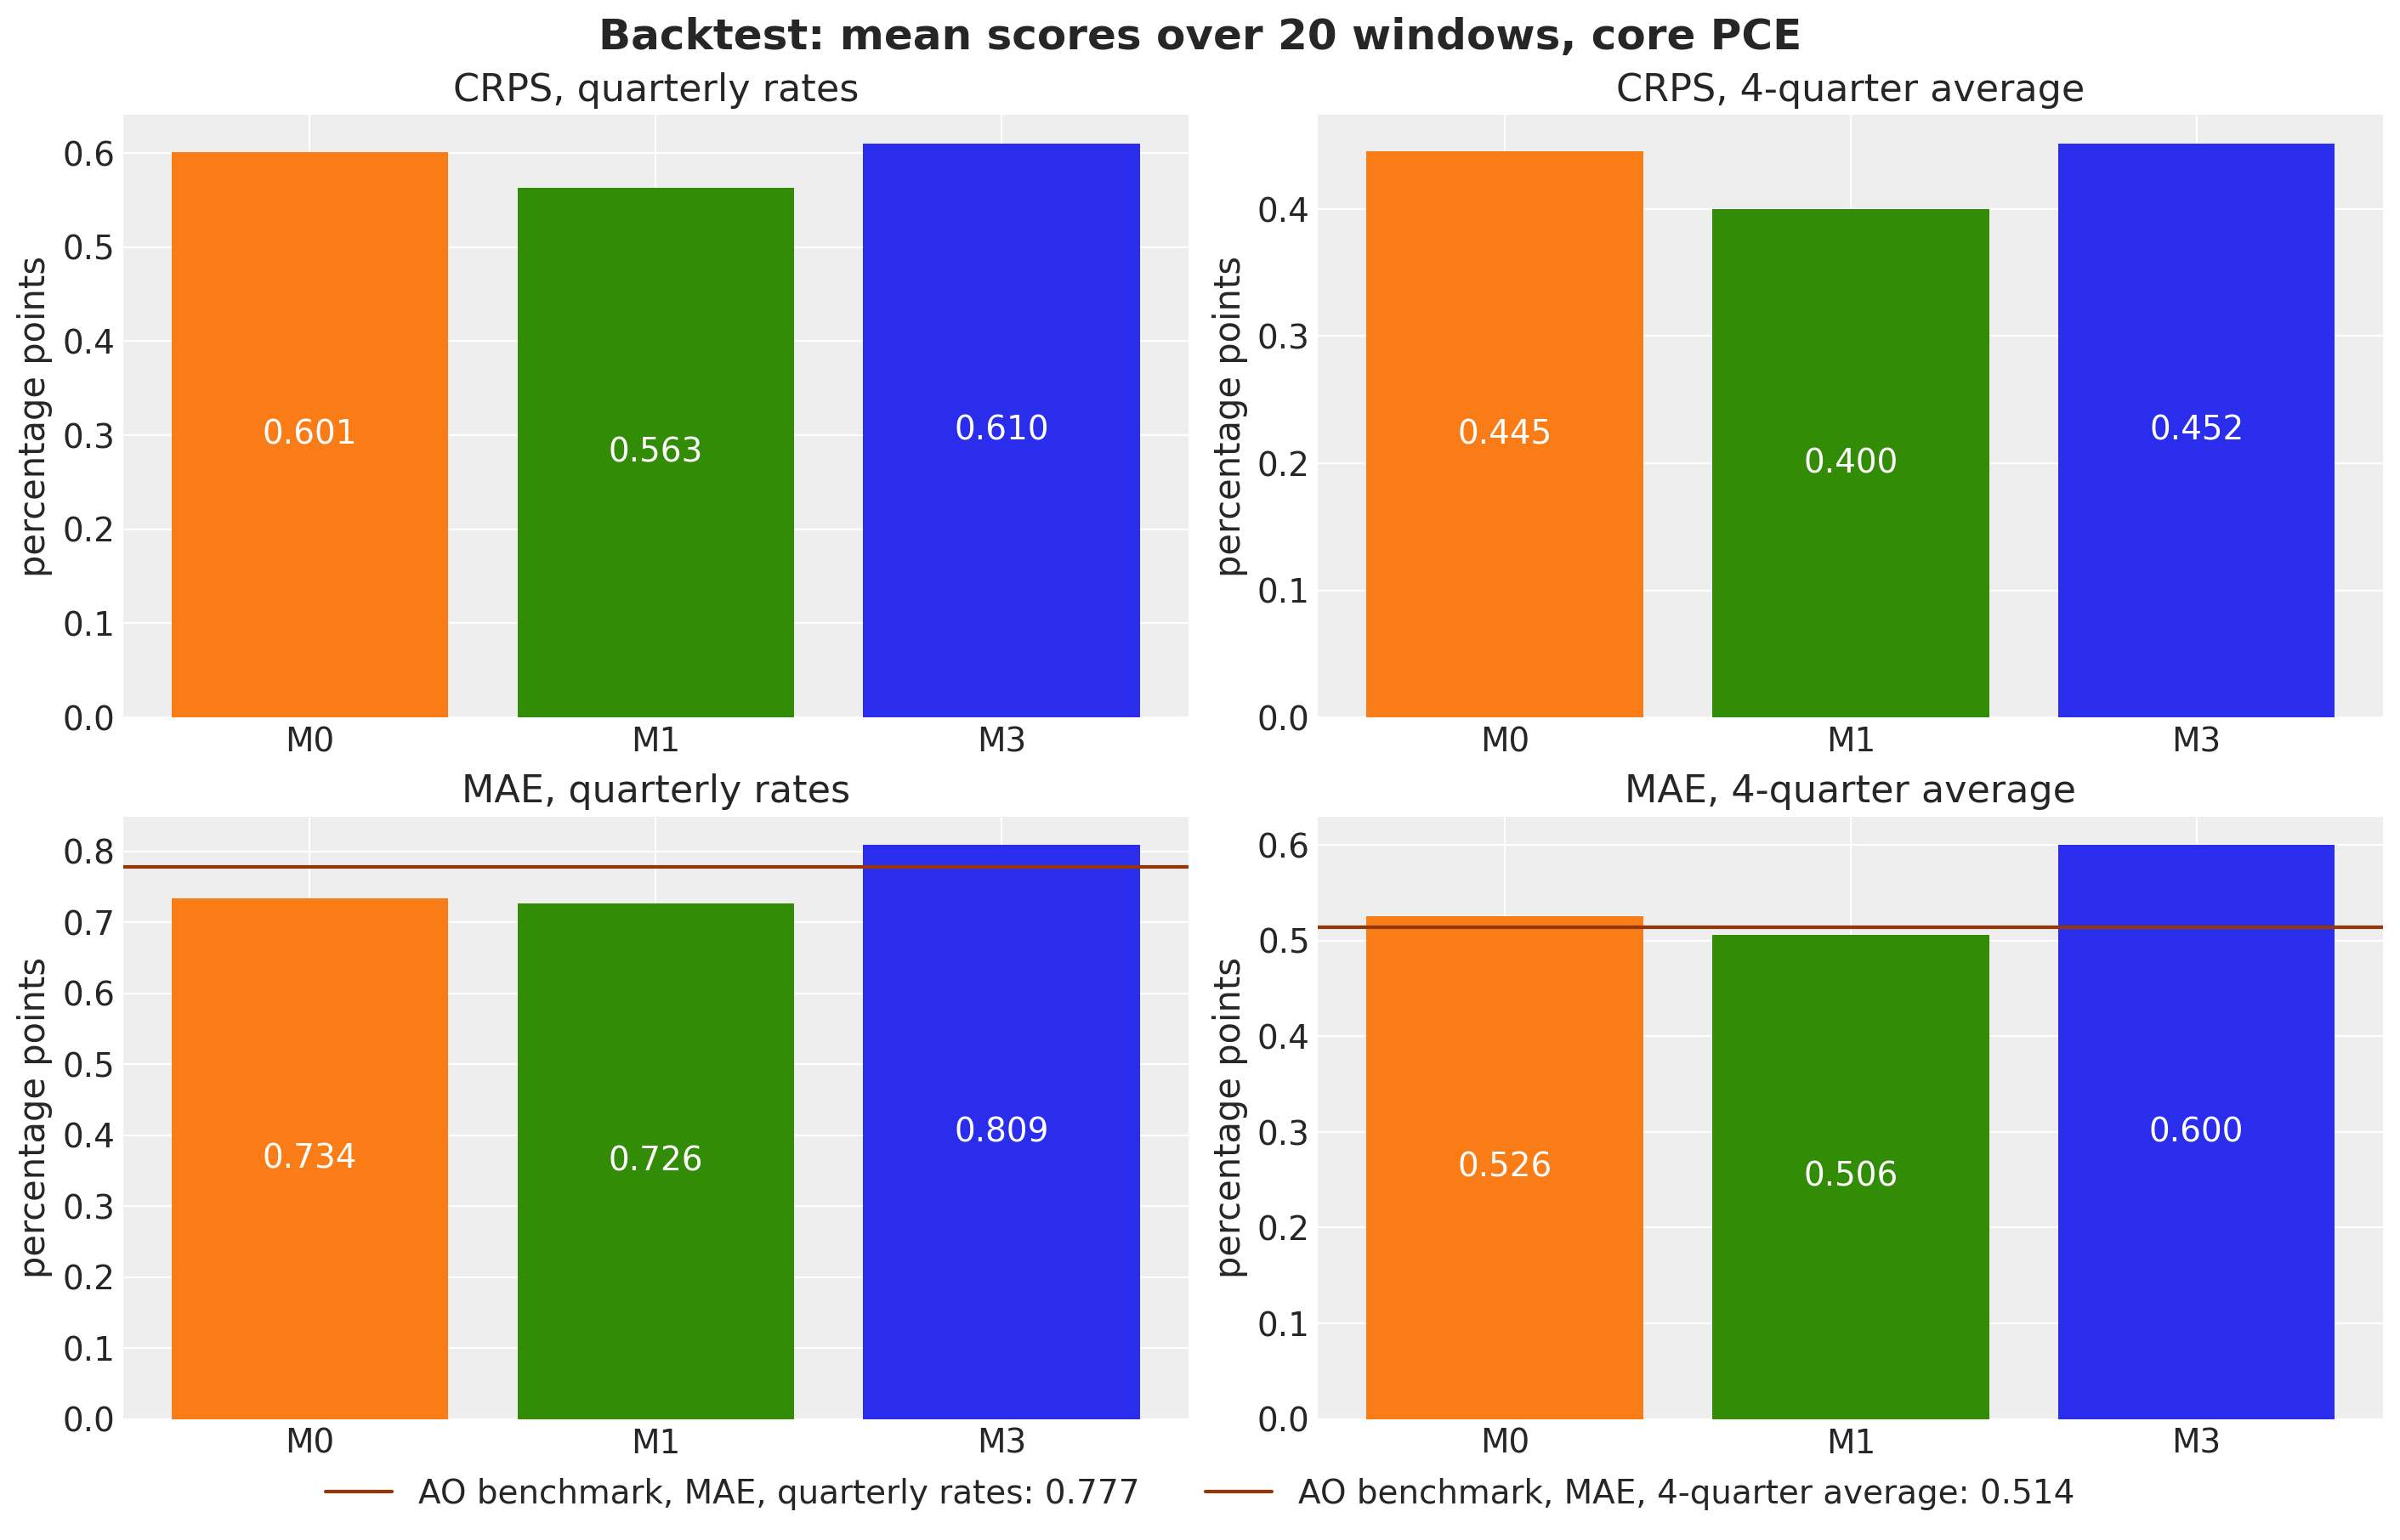

In [20]:
def metric_values(results: list[BacktestResult], metric: str) -> np.ndarray:
    # Per-window values of `metric`: (windows,)
    return np.array([result.metrics[metric] for result in results])


def plot_rung_bars(
    ax: plt.Axes, metric: str, title: str, benchmark: str | None = None
) -> Artist | None:
    labels = list(backtest_results)
    means = [metric_values(backtest_results[label], metric).mean() for label in labels]
    bars = ax.bar(labels, means, color=[RUNG_COLORS[label] for label in labels])
    ax.bar_label(bars, fmt="%.3f", fontsize=14, label_type="center", color="white")
    ax.set(title=title, ylabel="percentage points")

    if benchmark is None:
        return None

    benchmark_mean = metric_values(backtest_results["M3"], benchmark).mean()
    return ax.axhline(
        benchmark_mean,
        color=RUNG_COLORS["AO"],
        label=f"AO benchmark, {title}: {benchmark_mean:.3f}",
    )


fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 9), layout="constrained")
plot_rung_bars(axes[0, 0], "crps", "CRPS, quarterly rates")
plot_rung_bars(axes[0, 1], "crps_4q", "CRPS, 4-quarter average")
ao_quarterly = plot_rung_bars(axes[1, 0], "mae", "MAE, quarterly rates", benchmark="mae_ao")
ao_annual = plot_rung_bars(axes[1, 1], "mae_4q", "MAE, 4-quarter average", benchmark="mae_4q_ao")
fig.legend(handles=[ao_quarterly, ao_annual], loc="outside lower center", ncols=2)
fig.suptitle("Backtest: mean scores over 20 windows, core PCE", **TITLE);

Averaged over the 20 windows:

- M1, core PCE with stochastic volatility, has the lowest score in all four panels: CRPS $0.563$ on the quarterly rates and $0.400$ on the 4-quarter average, MAE $0.726$ and $0.506$.
- M0, with constant variances, is behind it on every score: CRPS $0.601$ and $0.445$, MAE $0.734$ and $0.526$.
- M3, the four-measure model, is last on every score: CRPS $0.610$ and $0.452$, MAE $0.809$ and $0.600$.
- The Atkeson and Ohanian benchmark has an MAE of $0.777$ on the quarterly rates and $0.514$ on the 4-quarter average. M1 beats it on both, M0 on the quarterly rates only, and M3 on neither.

The next figure shows the CRPS of every window against its origin date, one line per model, so that the periods where one component helps stand out.

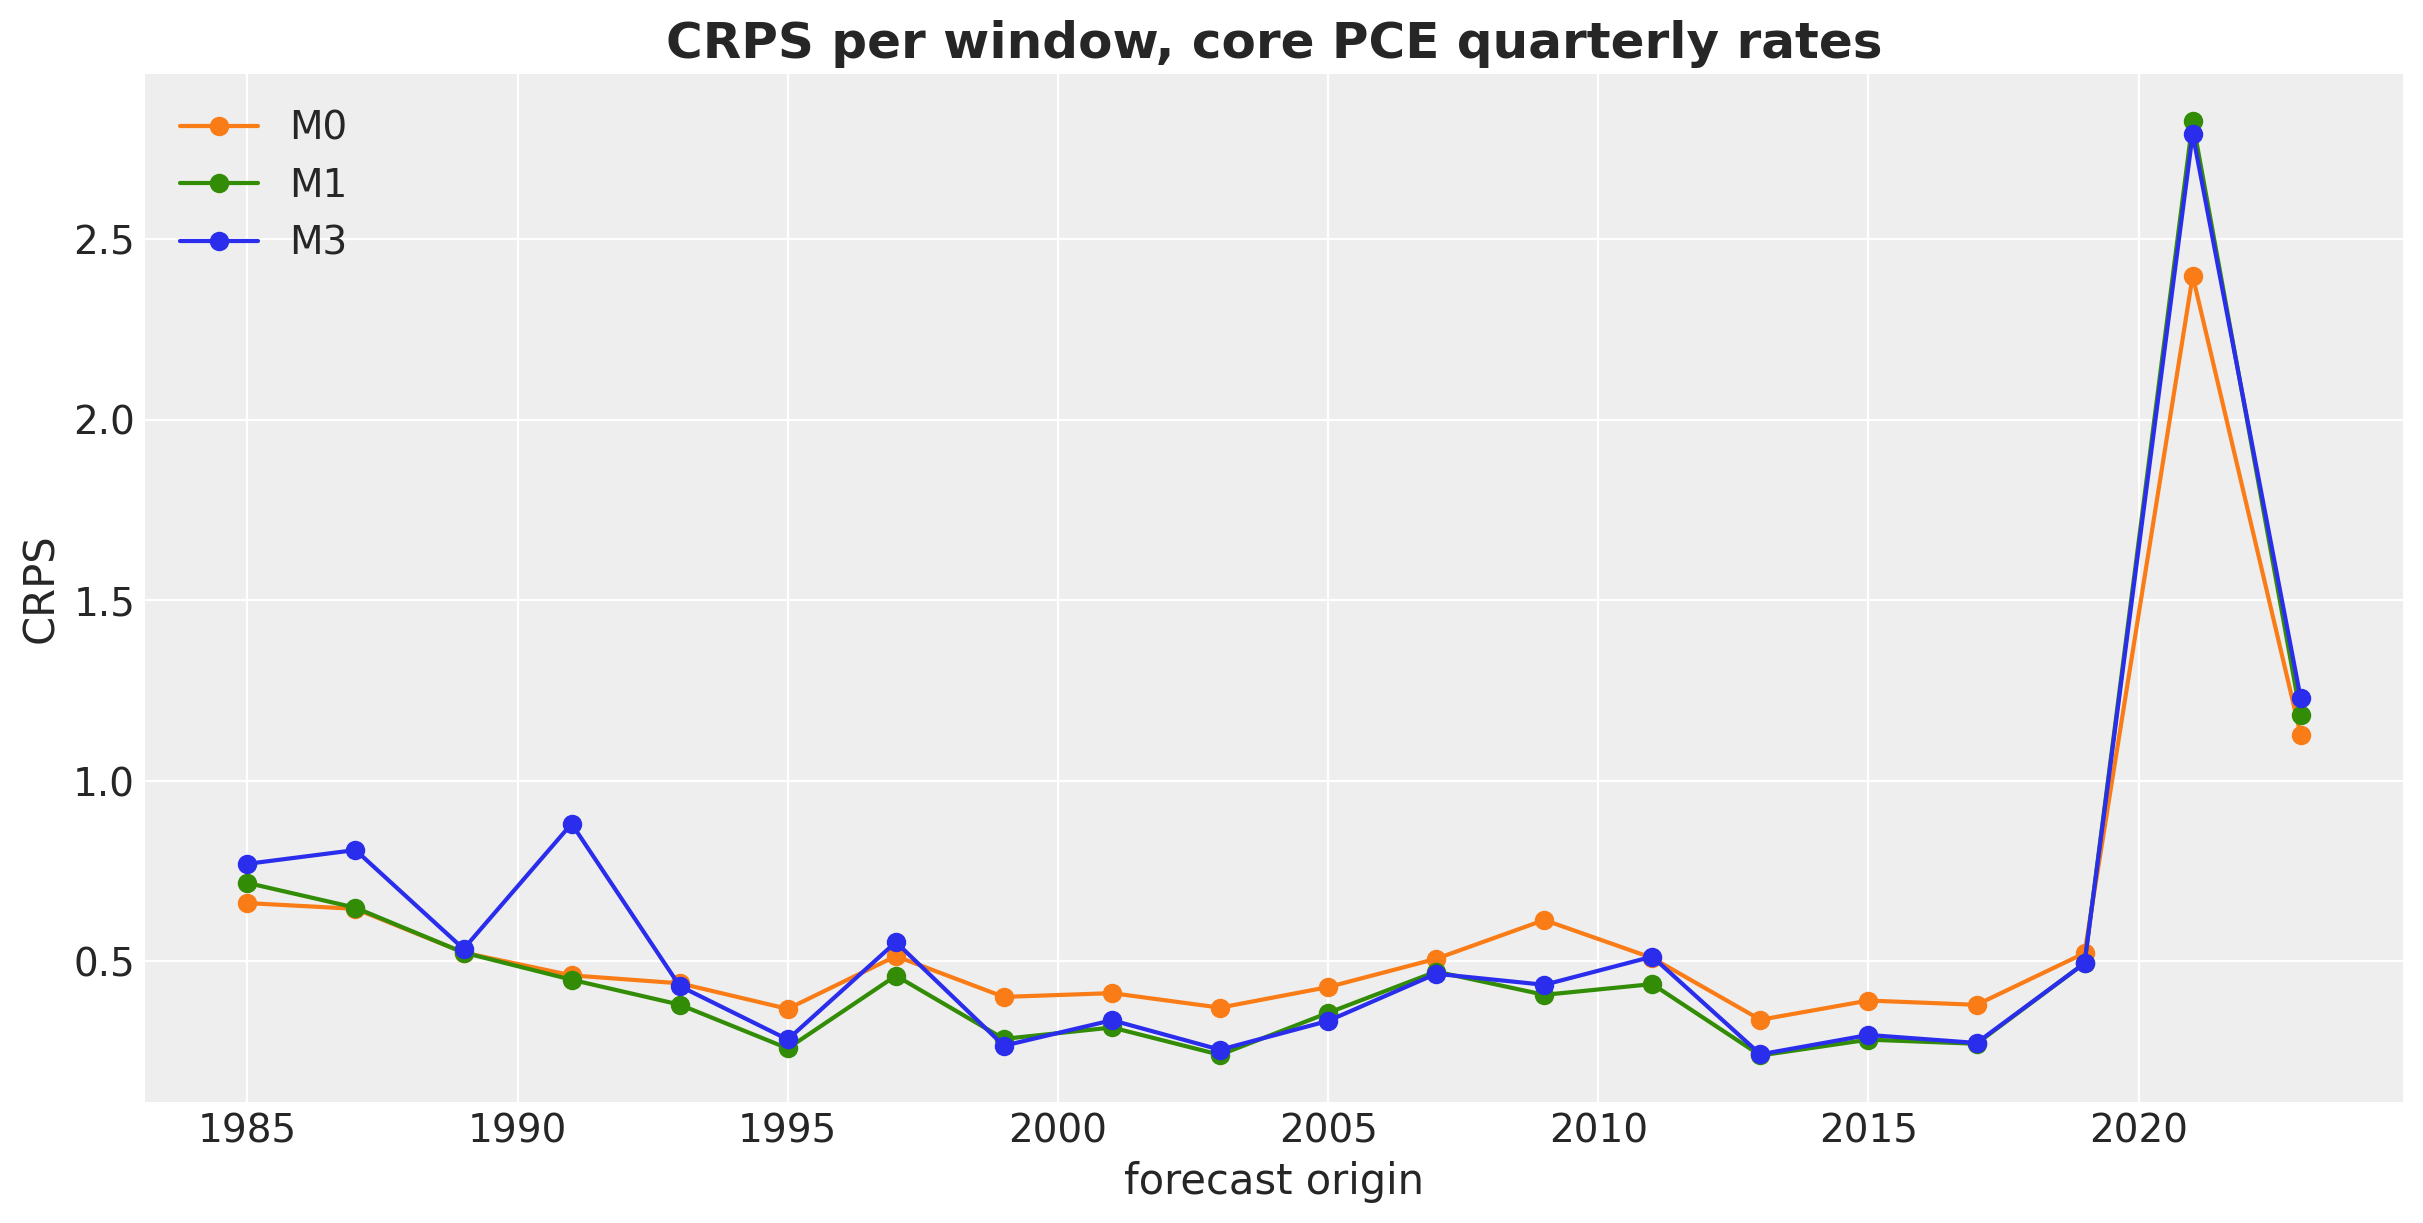

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))

for label, results in backtest_results.items():
    ax.plot(
        origins, metric_values(results, "crps"), marker="o", color=RUNG_COLORS[label], label=label
    )

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left")
ax.set(xlabel="forecast origin", ylabel="CRPS")
ax.set_title("CRPS per window, core PCE quarterly rates", **TITLE);

The per-window scores separate three periods:

- From 1985 to 2019 the scores stay between $0.24$ and $0.88$. M3 is the worst model at the 1985, 1987 and 1991 origins ($0.77$, $0.81$ and $0.88$, against $0.72$, $0.65$ and $0.45$ for M1). From 1993 to 2019, M1 and M3 are within $0.1$ of each other at every origin, and M0 is above M1 at every origin, by up to $0.20$ in 2009: constant variances fitted on a sample that includes the 1970s give bands that are too wide for the quiet decades.
- The 2021Q1 origin dominates every average: M0 scores $2.40$, M3 $2.79$ and M1 $2.83$. That single window contributes $0.12$ to $0.14$ to each 20-window mean.
- The 2023Q1 origin, the disinflation, scores between $1.13$ and $1.23$ for every model.

A difference of means over 20 windows can be noise. For each comparison we take the paired per-window difference, the score of a model minus the score of the model or benchmark it is compared with, on the same windows, and show its mean with one and two standard errors, $s / \sqrt{20}$ for the standard deviation $s$ of the 20 differences, in `az.plot_forest` (thick and thin bars); the label of each row repeats the mean and the two standard errors and counts the windows in which the first model scores lower. The windows do not overlap, so we treat the differences as approximately independent. A mean whose two standard errors reach zero is a difference the backtest cannot establish.

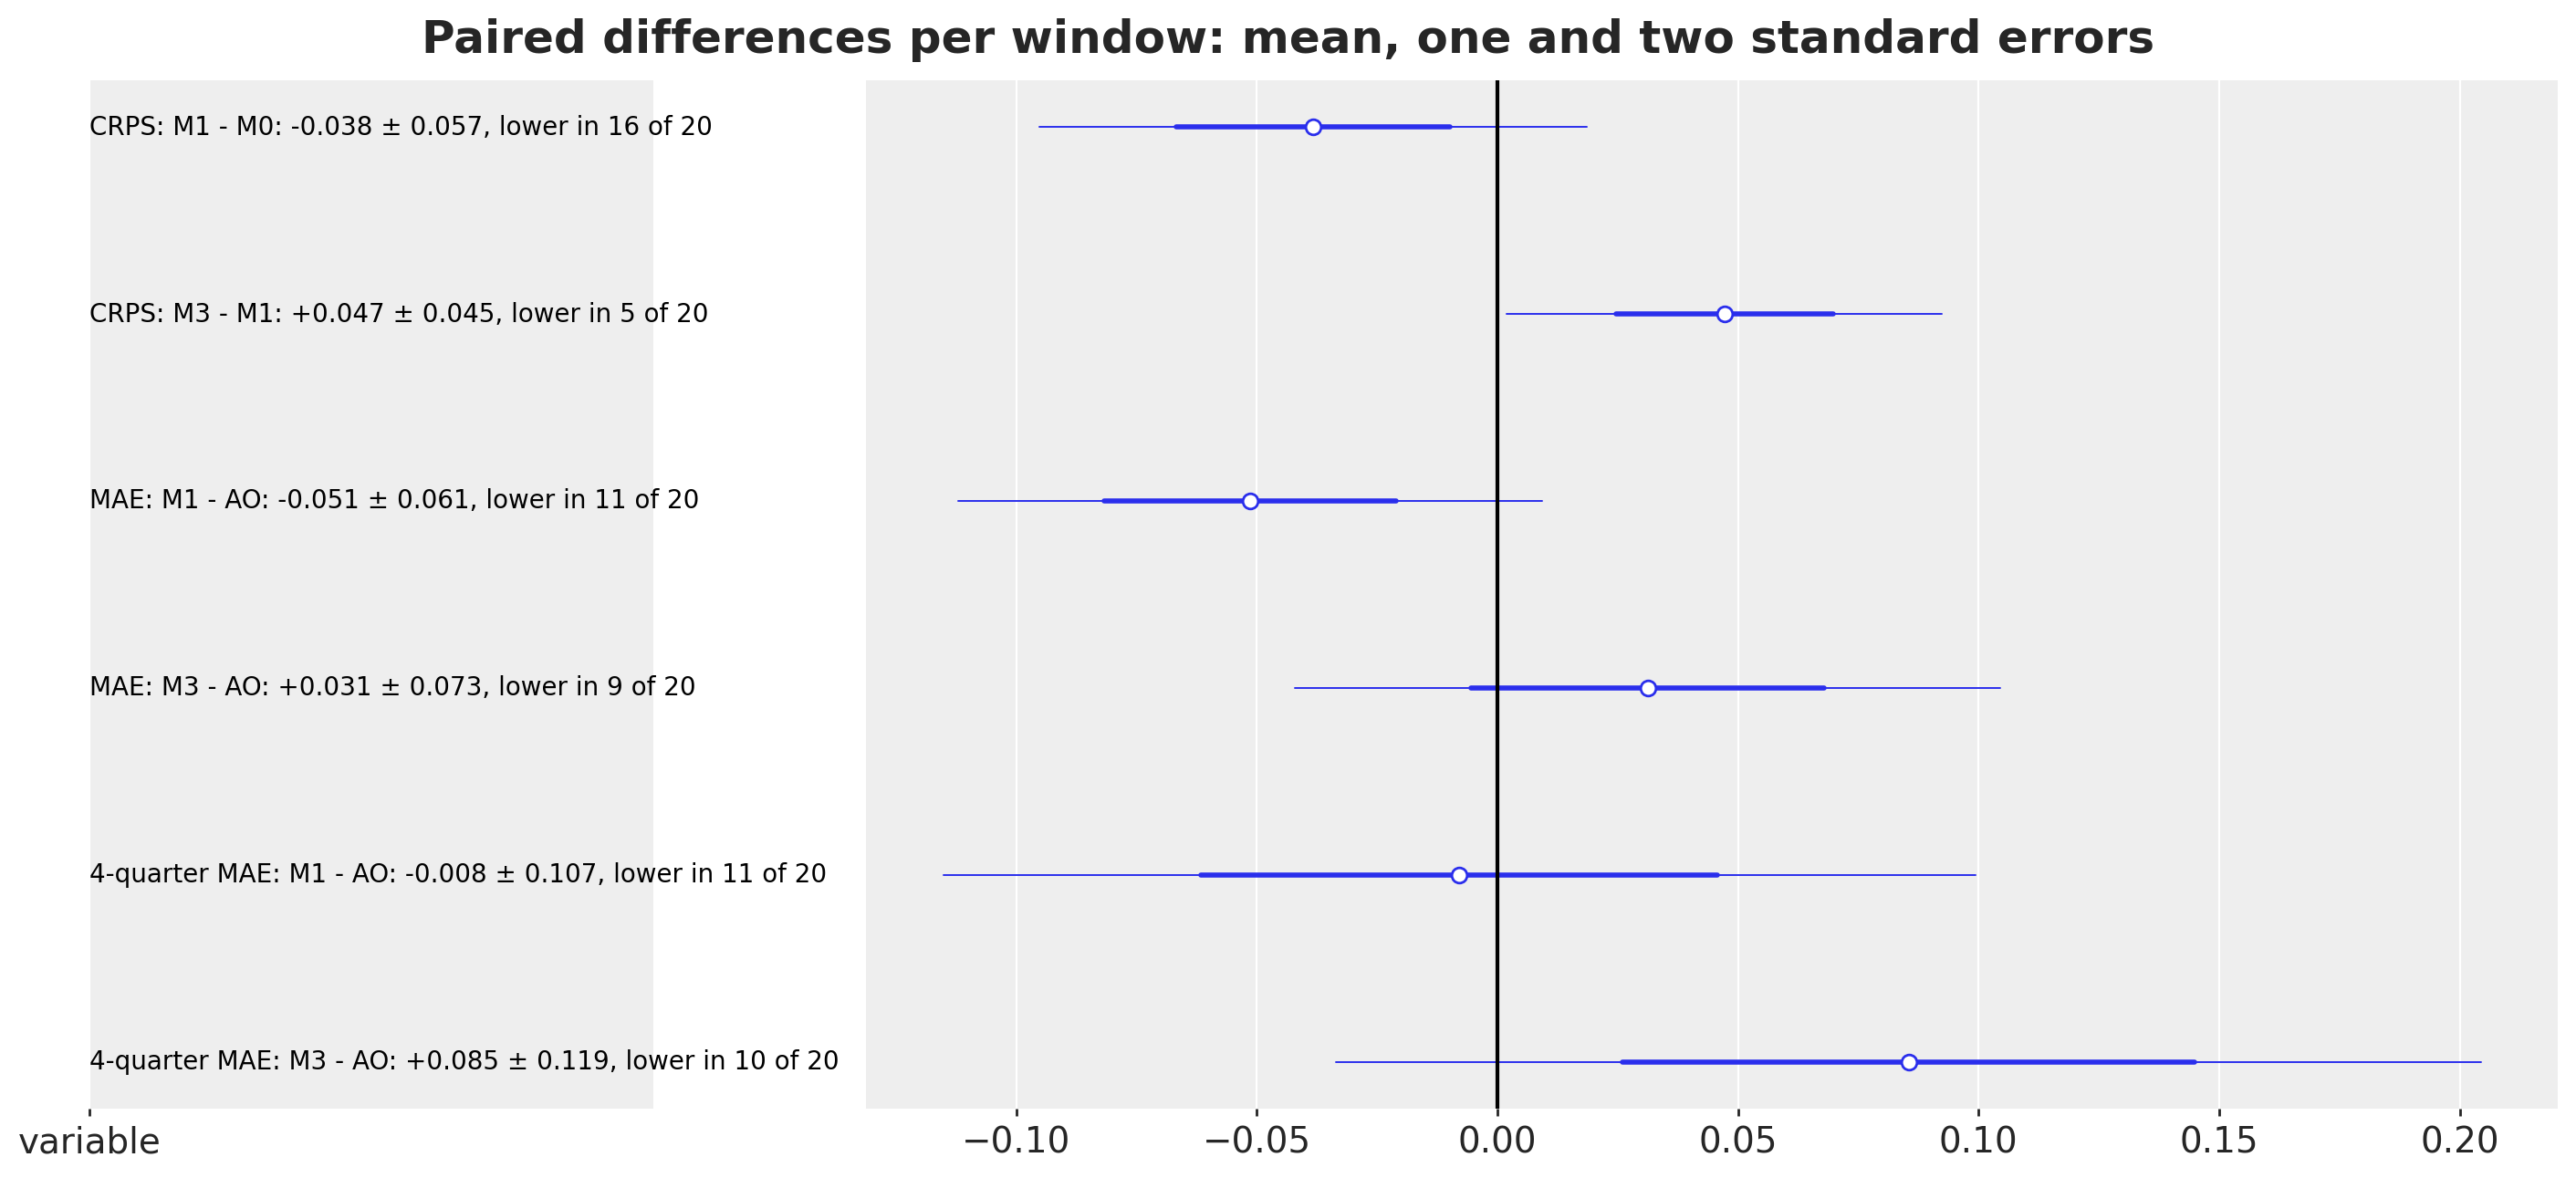

In [22]:
PAIRS = {
    "CRPS: M1 - M0": ("crps", "M1", "M0"),
    "CRPS: M3 - M1": ("crps", "M3", "M1"),
    "MAE: M1 - AO": ("mae", "M1", "AO"),
    "MAE: M3 - AO": ("mae", "M3", "AO"),
    "4-quarter MAE: M1 - AO": ("mae_4q", "M1", "AO"),
    "4-quarter MAE: M3 - AO": ("mae_4q", "M3", "AO"),
}


def paired_difference(metric: str, rung: str, baseline: str) -> np.ndarray:
    # Per-window score of `rung` minus that of `baseline` (a rung or the AO benchmark): (windows,)
    values = metric_values(backtest_results[rung], metric)

    if baseline == "AO":
        return values - metric_values(backtest_results[rung], f"{metric}_ao")

    return values - metric_values(backtest_results[baseline], metric)


differences = {name: paired_difference(*pair) for name, pair in PAIRS.items()}
means = {name: values.mean() for name, values in differences.items()}
standard_errors = {
    name: values.std(ddof=1) / np.sqrt(len(values)) for name, values in differences.items()
}
# Row labels carry the mean, two standard errors and the number of windows where the first
# model scores lower
row_labels = {
    name: (
        f"{name}: {means[name]:+.3f} ± {2 * standard_errors[name]:.3f}, "
        f"lower in {(differences[name] < 0).sum()} of {len(differences[name])}"
    )
    for name in differences
}


def mean_interval(width: float) -> xr.Dataset:
    # Mean plus and minus `width` standard errors, in the layout of az.hdi: (ci_bound,) per row
    return xr.Dataset(
        {
            row_labels[name]: (
                "ci_bound",
                [
                    means[name] - width * standard_errors[name],
                    means[name] + width * standard_errors[name],
                ],
            )
            for name in differences
        },
        coords={"ci_bound": ["lower", "upper"]},
    )


difference_tree = xr.DataTree.from_dict(
    {
        "posterior": xr.Dataset(
            {
                row_labels[name]: (("chain", "draw"), values[None, :])
                for name, values in differences.items()
            }
        )
    }
)
pc = az.plot_forest(
    difference_tree,
    combined=True,
    stats={
        "trunk": mean_interval(1.0),
        "twig": mean_interval(2.0),
        "point_estimate": xr.Dataset({row_labels[name]: means[name] for name in differences}),
    },
    figure_kwargs={"figsize": (14, 6)},
)
pc.viz["plot"].sel(column="forest").item().axvline(0.0, color="black")
pc.viz["figure"].item().suptitle(
    "Paired differences per window: mean, one and two standard errors", y=1.05, **TITLE
);

One of the six differences is larger than its two standard errors:

- M1 $-$ M0, CRPS: $-0.038 \pm 0.057$. Stochastic volatility lowers the CRPS in 16 of the 20 windows, and the 2021Q1 window, where M0 is better by $0.43$, keeps the mean from clearing two standard errors.
- M3 $-$ M1, CRPS: $+0.047 \pm 0.045$. Adding the three other measures and the common shock makes the core PCE forecast worse: M3 has the lower CRPS in only 5 of the 20 windows, and the mean just clears two standard errors.
- M1 $-$ AO and M3 $-$ AO, MAE on the quarterly rates: $-0.051 \pm 0.061$ and $+0.031 \pm 0.073$.
- M1 $-$ AO and M3 $-$ AO, MAE on the 4-quarter average: $-0.008 \pm 0.107$ and $+0.085 \pm 0.119$.

Twenty windows of eight quarters are enough to see that M3 forecasts core PCE worse than M1, and too few to rank M1, M0 and the benchmark.

The scores so far average over the eight horizon steps. The stored forecast draws let us score each step $j$ on its own: the CRPS $j$ quarters ahead and the coverage of the two central intervals $j$ quarters ahead, averaged over the windows. Twenty windows give one realized value per step, so the coverage of a calibrated forecast scatters around the nominal level with a binomial standard deviation of $\sqrt{0.94 \times 0.06 / 20} \approx 5.3$ percentage points at the $94\%$ level and $11.2$ at the $50\%$ level; the shaded band is two of those standard deviations around the nominal level. The legend gives each model's coverage pooled over the eight steps with two standard errors. The eight steps of a window share one forecast path, so we take the coverage of each window over its eight steps and compute the standard error across the 20 windows.

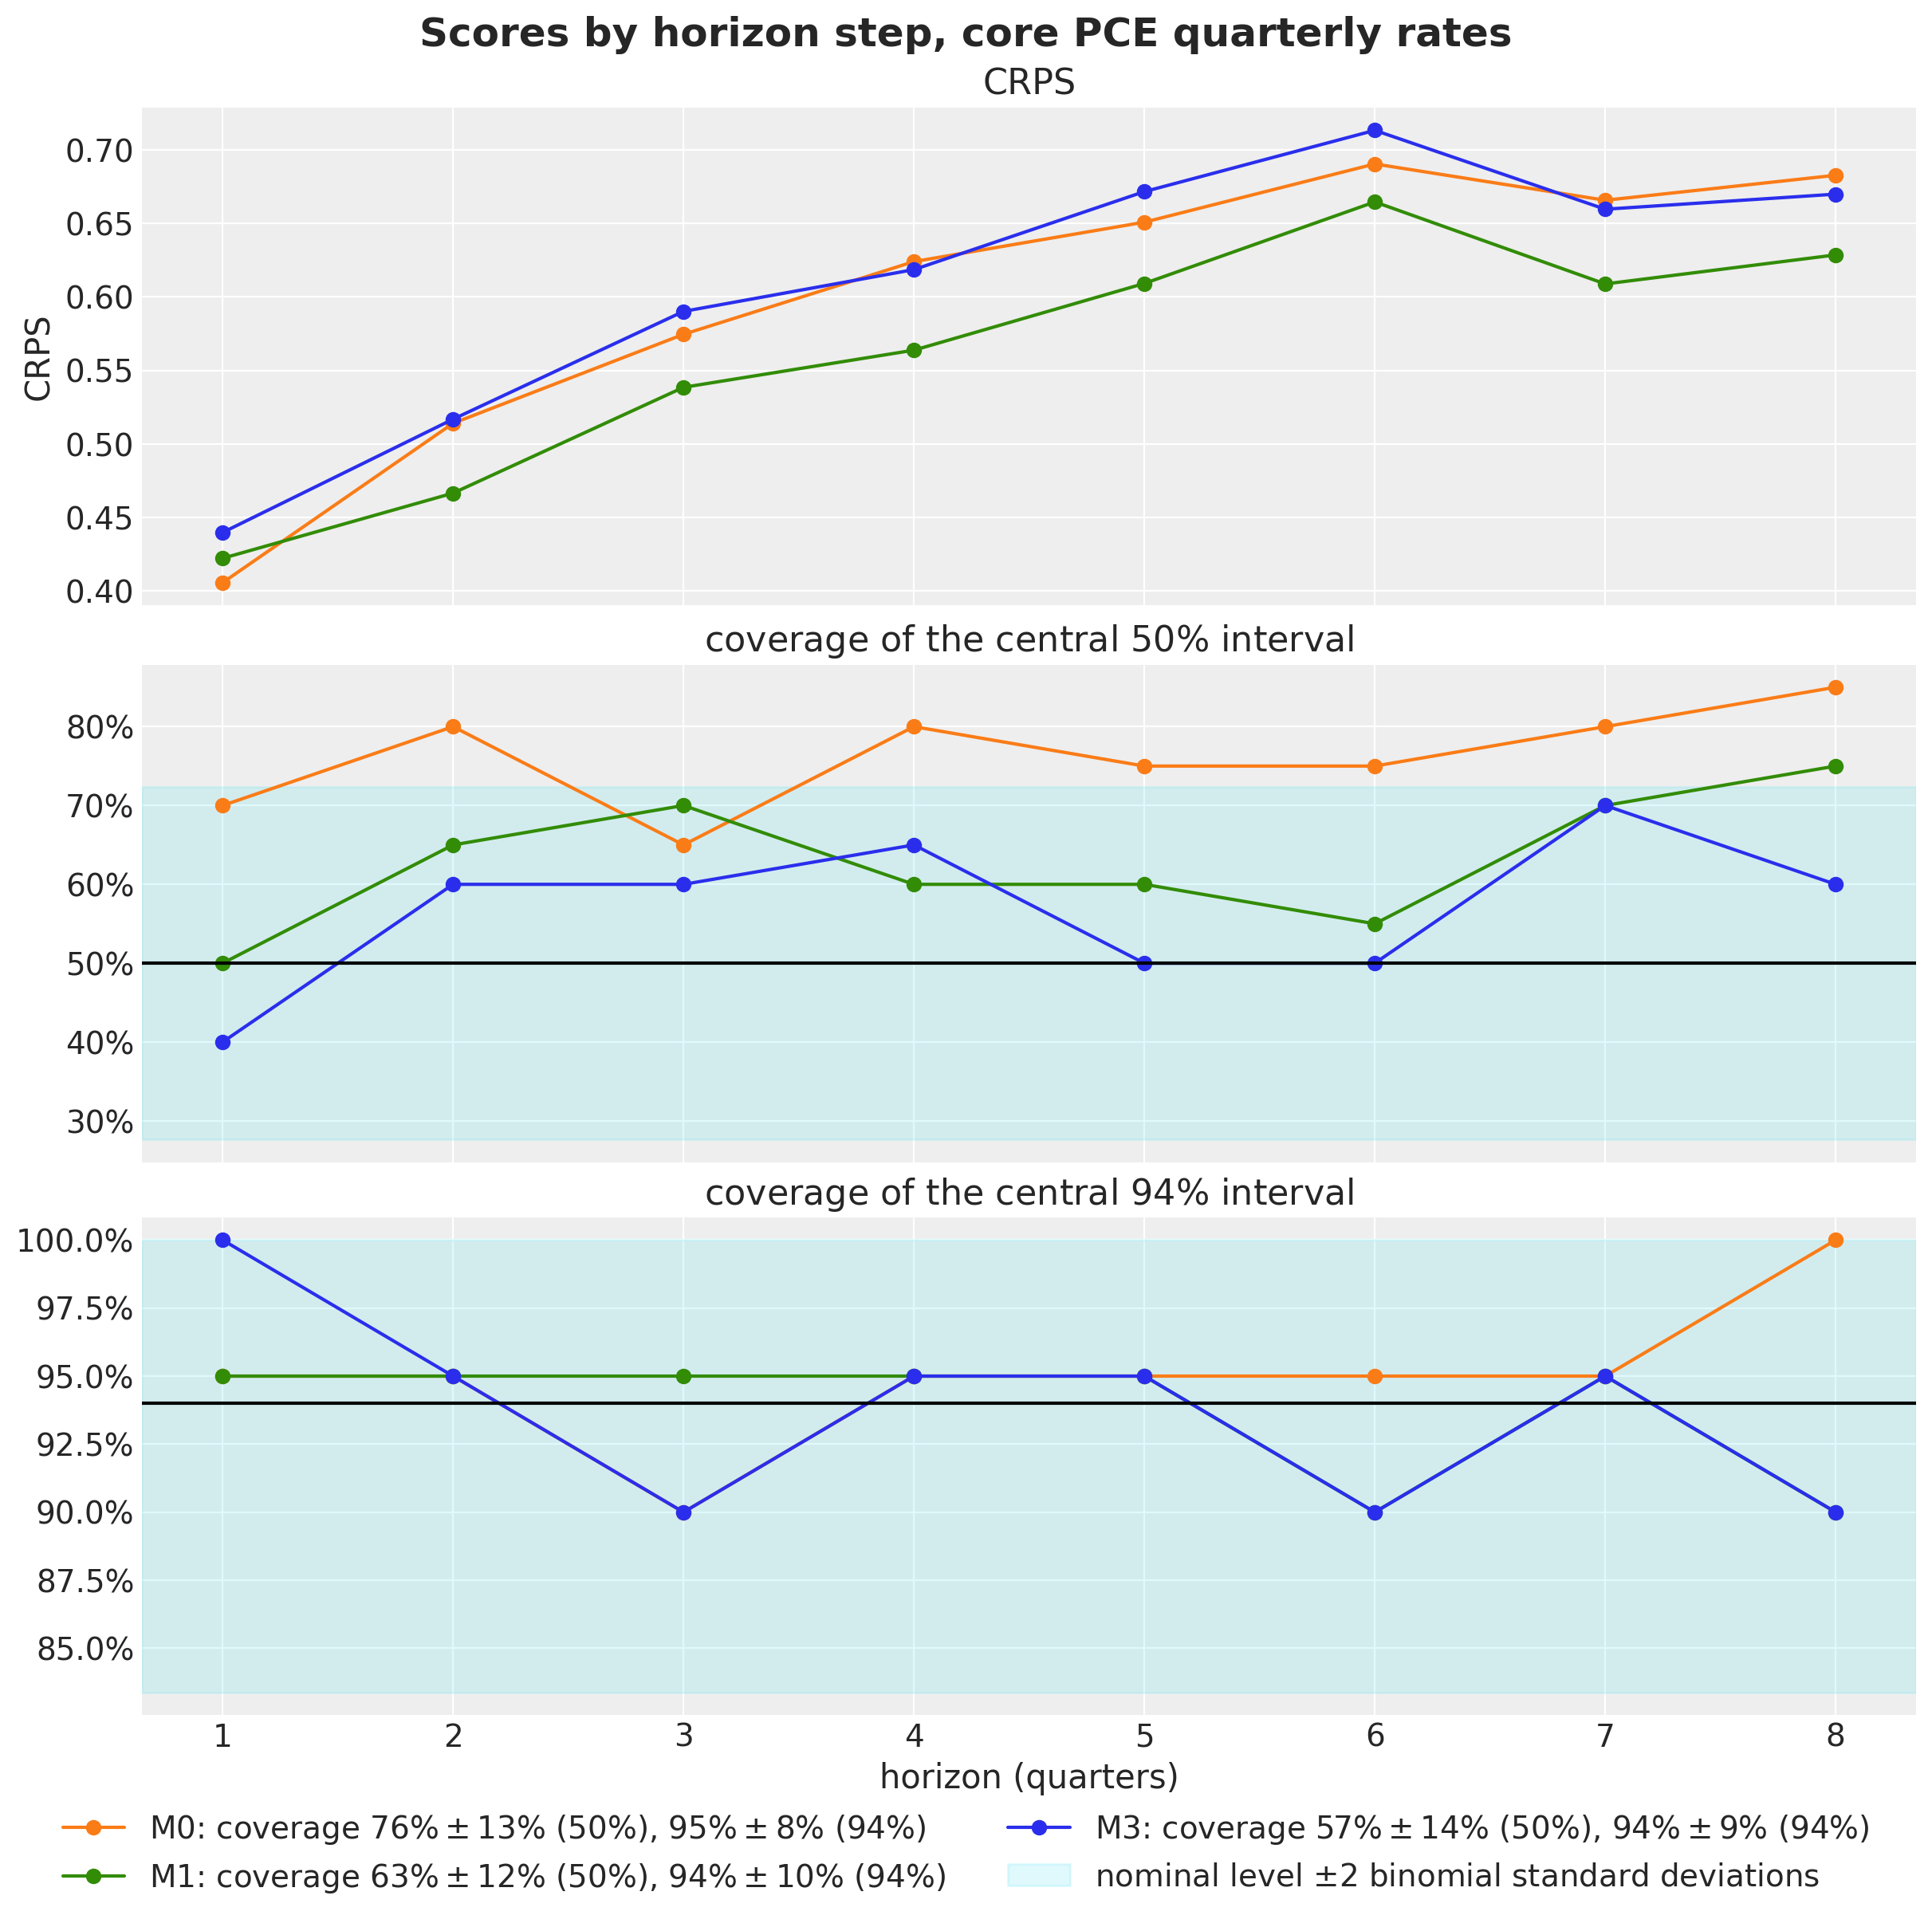

In [23]:
def per_horizon_scores(results: list[BacktestResult]) -> dict[str, np.ndarray]:
    draws = jnp.stack([jnp.asarray(result.prediction)[..., -1] for result in results])  # (w, s, j)
    truth = jnp.stack([rates[result.t1 : result.t2, -1] for result in results])  # (windows, j)
    scores = {"crps": jax.vmap(crps_empirical)(draws, truth).mean(axis=0)}

    for prob in (0.5, CI_PROB):
        lower = jnp.quantile(draws, (1.0 - prob) / 2.0, axis=1)  # (windows, j)
        upper = jnp.quantile(draws, (1.0 + prob) / 2.0, axis=1)  # (windows, j)
        inside = (truth >= lower) & (truth <= upper)  # (windows, j)
        scores[f"coverage_{prob:.0%}"] = inside.mean(axis=0)  # per horizon step: (j,)
        scores[f"window_coverage_{prob:.0%}"] = inside.mean(axis=1)  # per window: (windows,)

    return {name: np.asarray(value) for name, value in scores.items()}


def pooled_coverage(window_coverage: np.ndarray) -> str:
    # Mean coverage over the windows with two standard errors, as LaTeX percentages
    two_se = 2 * window_coverage.std(ddof=1) / np.sqrt(len(window_coverage))
    return rf"${window_coverage.mean():.0%} \pm {two_se:.0%}$".replace("%", r"\%")


horizon_scores = {
    label: per_horizon_scores(results) for label, results in backtest_results.items()
}
horizon_steps = np.arange(1, HORIZON + 1)

fig, axes = plt.subplots(nrows=3, ncols=1, sharex=True, figsize=(12, 12), layout="constrained")

ci_percent = rf"${CI_PROB:.0%}$".replace("%", r"\%")  # "$94\%$"

for label, scores in horizon_scores.items():
    coverage_label = (
        rf"{pooled_coverage(scores['window_coverage_50%'])} ($50\%$), "
        rf"{pooled_coverage(scores[f'window_coverage_{CI_PROB:.0%}'])} ({ci_percent})"
    )
    axes[0].plot(
        horizon_steps,
        scores["crps"],
        marker="o",
        color=RUNG_COLORS[label],
        label=f"{label}: coverage {coverage_label}",
    )
    axes[1].plot(horizon_steps, scores["coverage_50%"], marker="o", color=RUNG_COLORS[label])
    axes[2].plot(
        horizon_steps, scores[f"coverage_{CI_PROB:.0%}"], marker="o", color=RUNG_COLORS[label]
    )

for ax, prob in zip(axes[1:], (0.5, CI_PROB), strict=True):
    binomial_sd = np.sqrt(prob * (1 - prob) / len(origins))
    ax.axhline(prob, color="black")
    ax.axhspan(prob - 2 * binomial_sd, min(1.0, prob + 2 * binomial_sd), color="C5", alpha=0.2)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.set(title=rf"coverage of the central ${prob:.0%}$ interval".replace("%", r"\%"))

band_patch = Patch(
    color="C5", alpha=0.2, label=r"nominal level $\pm 2$ binomial standard deviations"
)
axes[0].set(title="CRPS", ylabel="CRPS")
axes[-1].set(xlabel="horizon (quarters)", xticks=horizon_steps)
handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles=[*handles, band_patch], loc="outside lower center", ncols=2)
fig.suptitle("Scores by horizon step, core PCE quarterly rates", **TITLE);

The scores change with the horizon step:

- The CRPS rises from $0.41$ to $0.44$ one quarter ahead to $0.63$ (M1), $0.67$ (M3) and $0.68$ (M0) eight quarters ahead. One quarter ahead M0 is the best of the three ($0.406$ against $0.422$ and $0.440$); from two quarters on M1 is the best at every step.
- The $94\%$ intervals cover between $90\%$ and $100\%$ of the outcomes at every step for all three models, inside the binomial band. Pooled over the steps, the coverage is $95\%$ (M0), $94\%$ (M1) and $94\%$ (M3), each with two standard errors of $8$ to $10$ points.
- The $50\%$ intervals of M3 are on target, with a pooled coverage of $57\% \pm 14\%$. Those of M1 cover $63\% \pm 12\%$, slightly too wide, and those of M0 cover $76\% \pm 13\%$ and sit above the binomial band at six of the eight steps: its constant variances are too large for the quiet decades, which also explains its CRPS.

The stored draws also let us look at one origin in detail. 2021Q1 is the origin just before the surge: the last observed quarter is 2020Q4, and the next eight quarters are the fastest core inflation since the early 1980s. We plot the forecast of every model from that origin against the realized path.

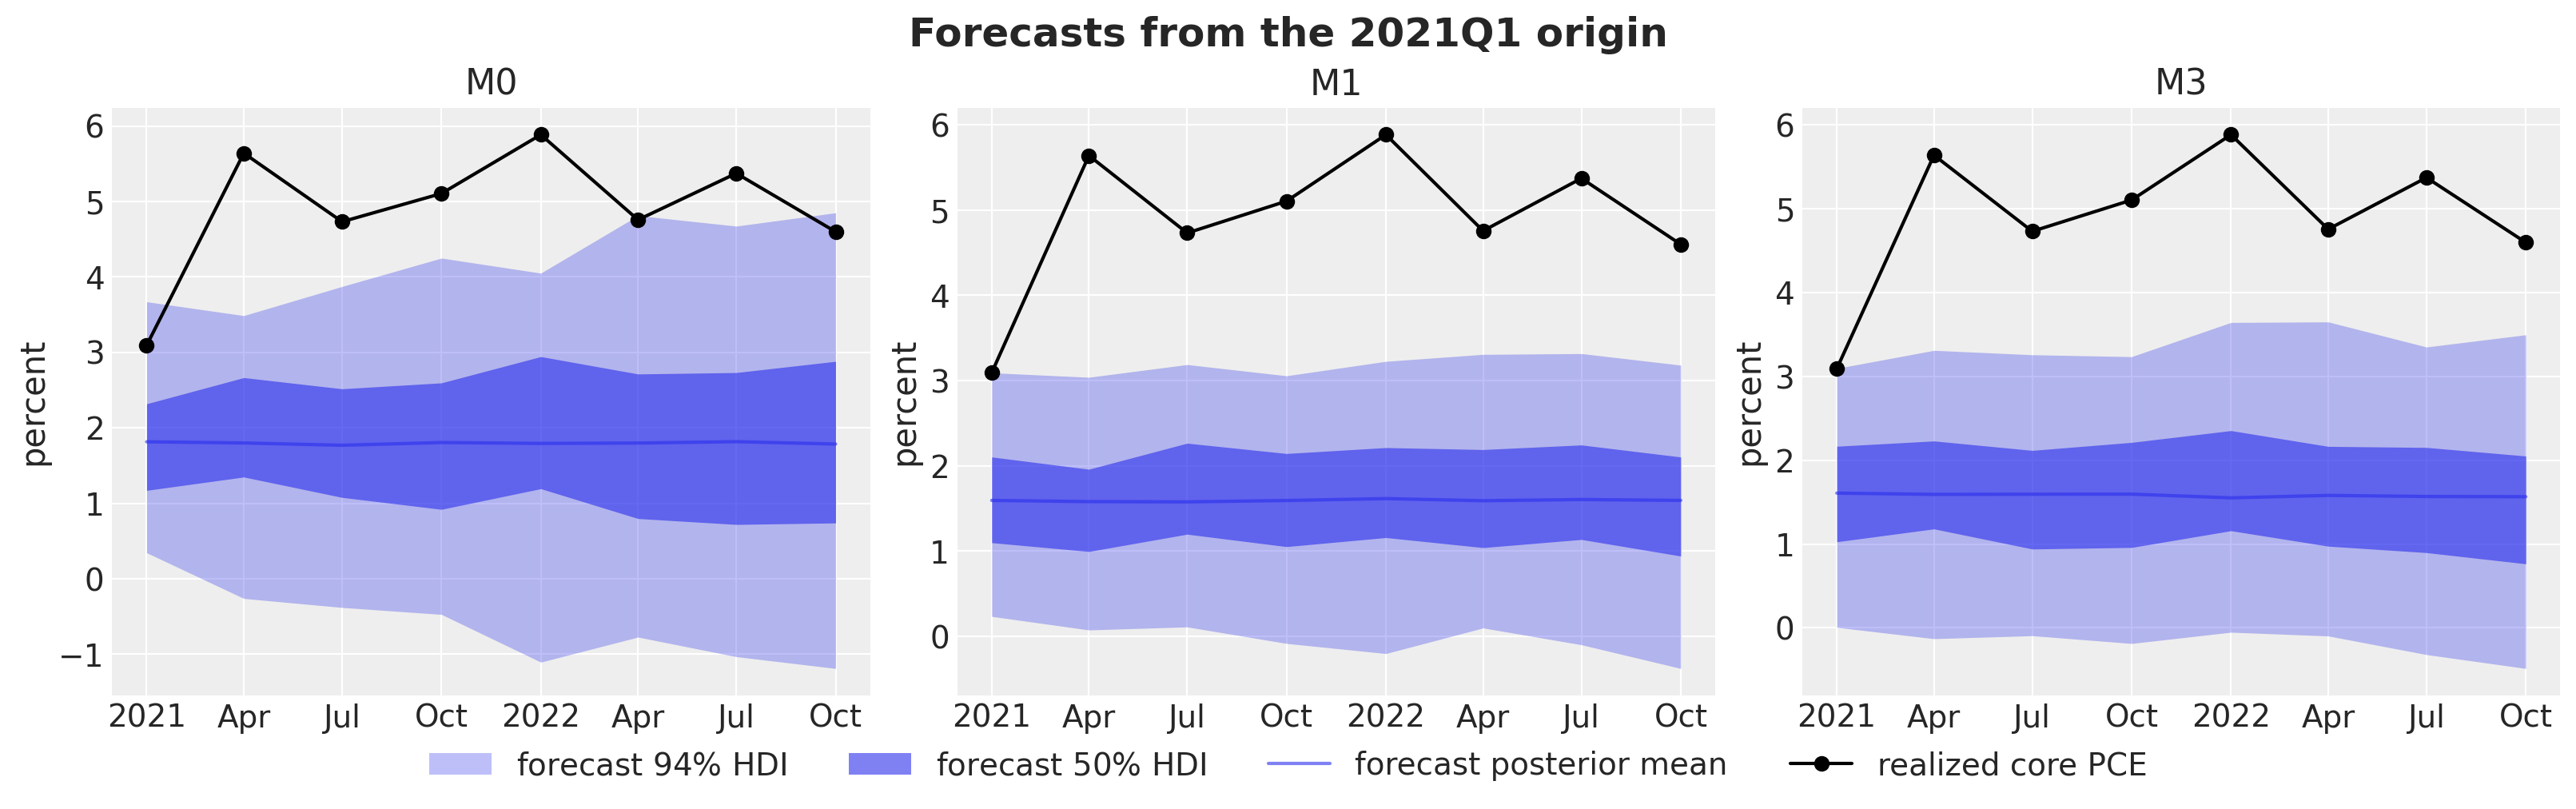

In [24]:
origin_2021 = int(np.flatnonzero(origins == np.datetime64("2021-01-01"))[0])
window = backtest_results["M3"][origin_2021]
window_dates = date_num[window.t1 : window.t2]
realized = rates[window.t1 : window.t2, -1]
draws_2021 = np.concatenate(
    [
        np.asarray(results[origin_2021].prediction)[..., -1:]
        for results in backtest_results.values()
    ],
    axis=-1,
)  # (samples, horizon, models): the core PCE draws of every model from the 2021Q1 origin

pc, band_handles = plot_bands(
    draws_2021,
    window_dates,
    list(backtest_results),
    label="forecast ",
    mean_line=True,
    col_wrap=3,
    figsize=(16, 5),
)
fig = pc.viz["figure"].item()

for ax, label in zip(fig.axes, backtest_results, strict=True):
    (realized_line,) = ax.plot(
        window_dates, realized, color="black", marker="o", label="realized core PCE"
    )
    ax.set(title=label, ylabel="percent")

fig.legend(handles=[*band_handles, realized_line], loc="outside lower center", ncols=4)
fig.suptitle("Forecasts from the 2021Q1 origin", **TITLE);

All three models fail in the surge. After the first quarter, the realized core PCE rates run from $4.6\%$ to $5.9\%$:

- M0, M1 and M3 forecast means of $1.8\%$, $1.6\%$ and $1.6\%$, flat over the eight quarters.
- The upper edges of their $94\%$ bands reach $4.85\%$, $3.3\%$ and $3.65\%$. M0 covers three of the eight quarters, 2021Q1, 2022Q2 and 2022Q4; M3 covers only the first, $3.1\%$ in 2021Q1; M1 covers none. No model puts a single realized quarter inside its $50\%$ interval.

M0 scores best here ($2.40$ against $2.83$ for M1 and $2.79$ for M3) because its constant variances, fitted on a sample that includes the 1970s, give it the widest band.

The last check on the backtest is the fits themselves: the divergences of every window, per model.

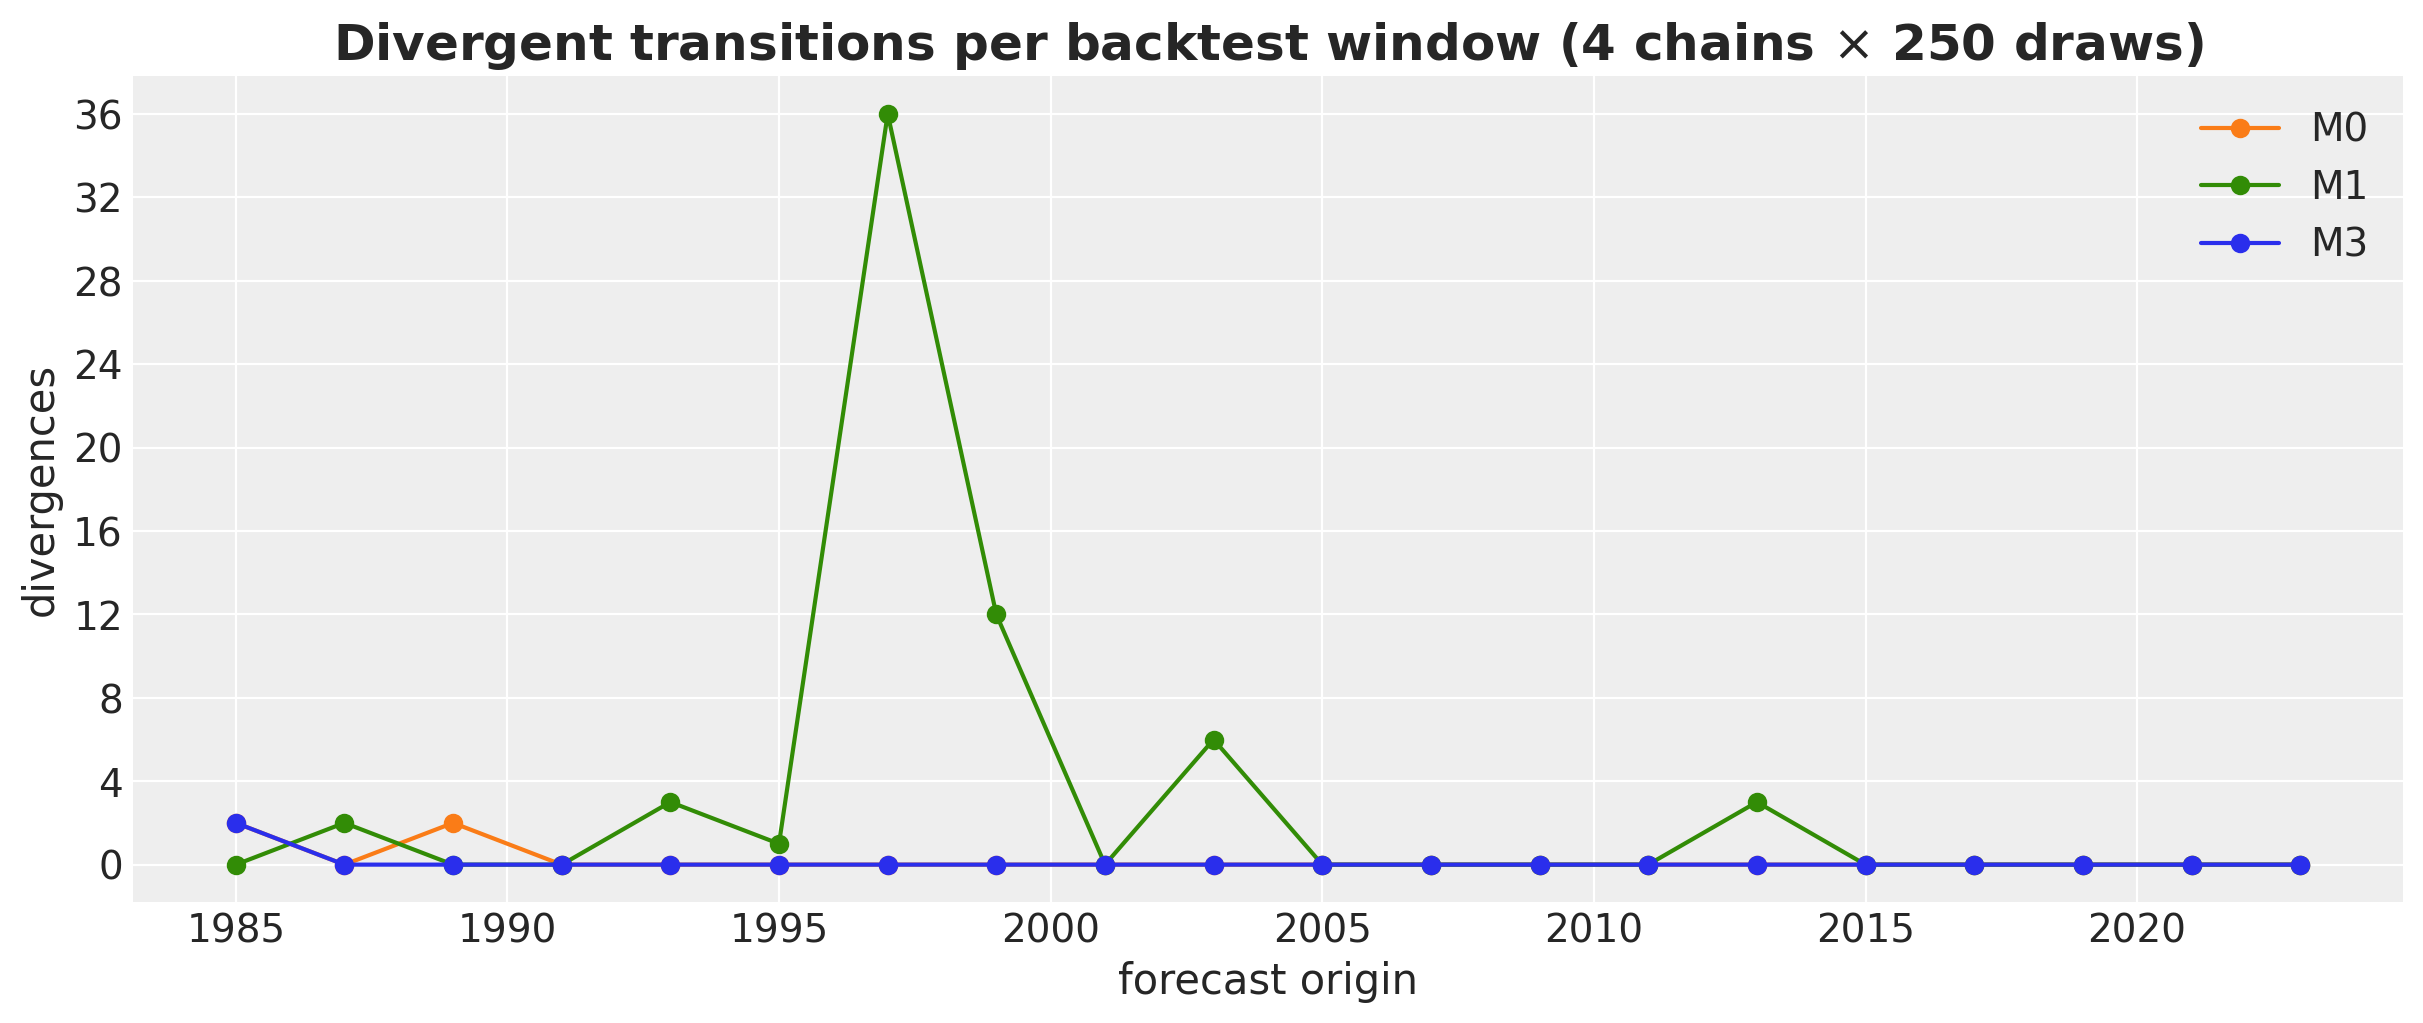

In [25]:
fig, ax = plt.subplots(figsize=(12, 5))

for label in backtest_results:
    rung_origins = [origin for rung, origin, _ in backtest_divergences if rung == label]
    counts = [count for rung, _, count in backtest_divergences if rung == label]
    ax.plot(rung_origins, counts, marker="o", color=RUNG_COLORS[label], label=label)

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(loc="upper right")
ax.set(xlabel="forecast origin", ylabel="divergences")
ax.set_title(r"Divergent transitions per backtest window (4 chains $\times$ 250 draws)", **TITLE);

M3 has $2$ divergent transitions in the first window, with origin 1985Q1, and none after it, and M0 has $2$ in each of the 1985Q1 and 1989Q1 windows. M1 has the most: $36$ at the 1997Q1 origin, $12$ at 1999Q1, $6$ at 2003Q1, $3$ at 2013Q1 and a few in the early windows. With one series and a volatility random walk, M1 has the least information to separate the trend from the gap. The counts are at most $3.6\%$ of the $1{,}000$ draws, so the scores of M1 at the 1997Q1 and 1999Q1 origins rest on fits that are slightly off.

## Sensitivity to the vol-of-vol

$\gamma$ is the one number we fixed. We refit M3 with $\gamma = 0.2$ and $\gamma = 0.4$ and compare the trend volatility of the three fits; $0.4$ is about where a learned $\gamma$ goes, as the figure after this one shows.

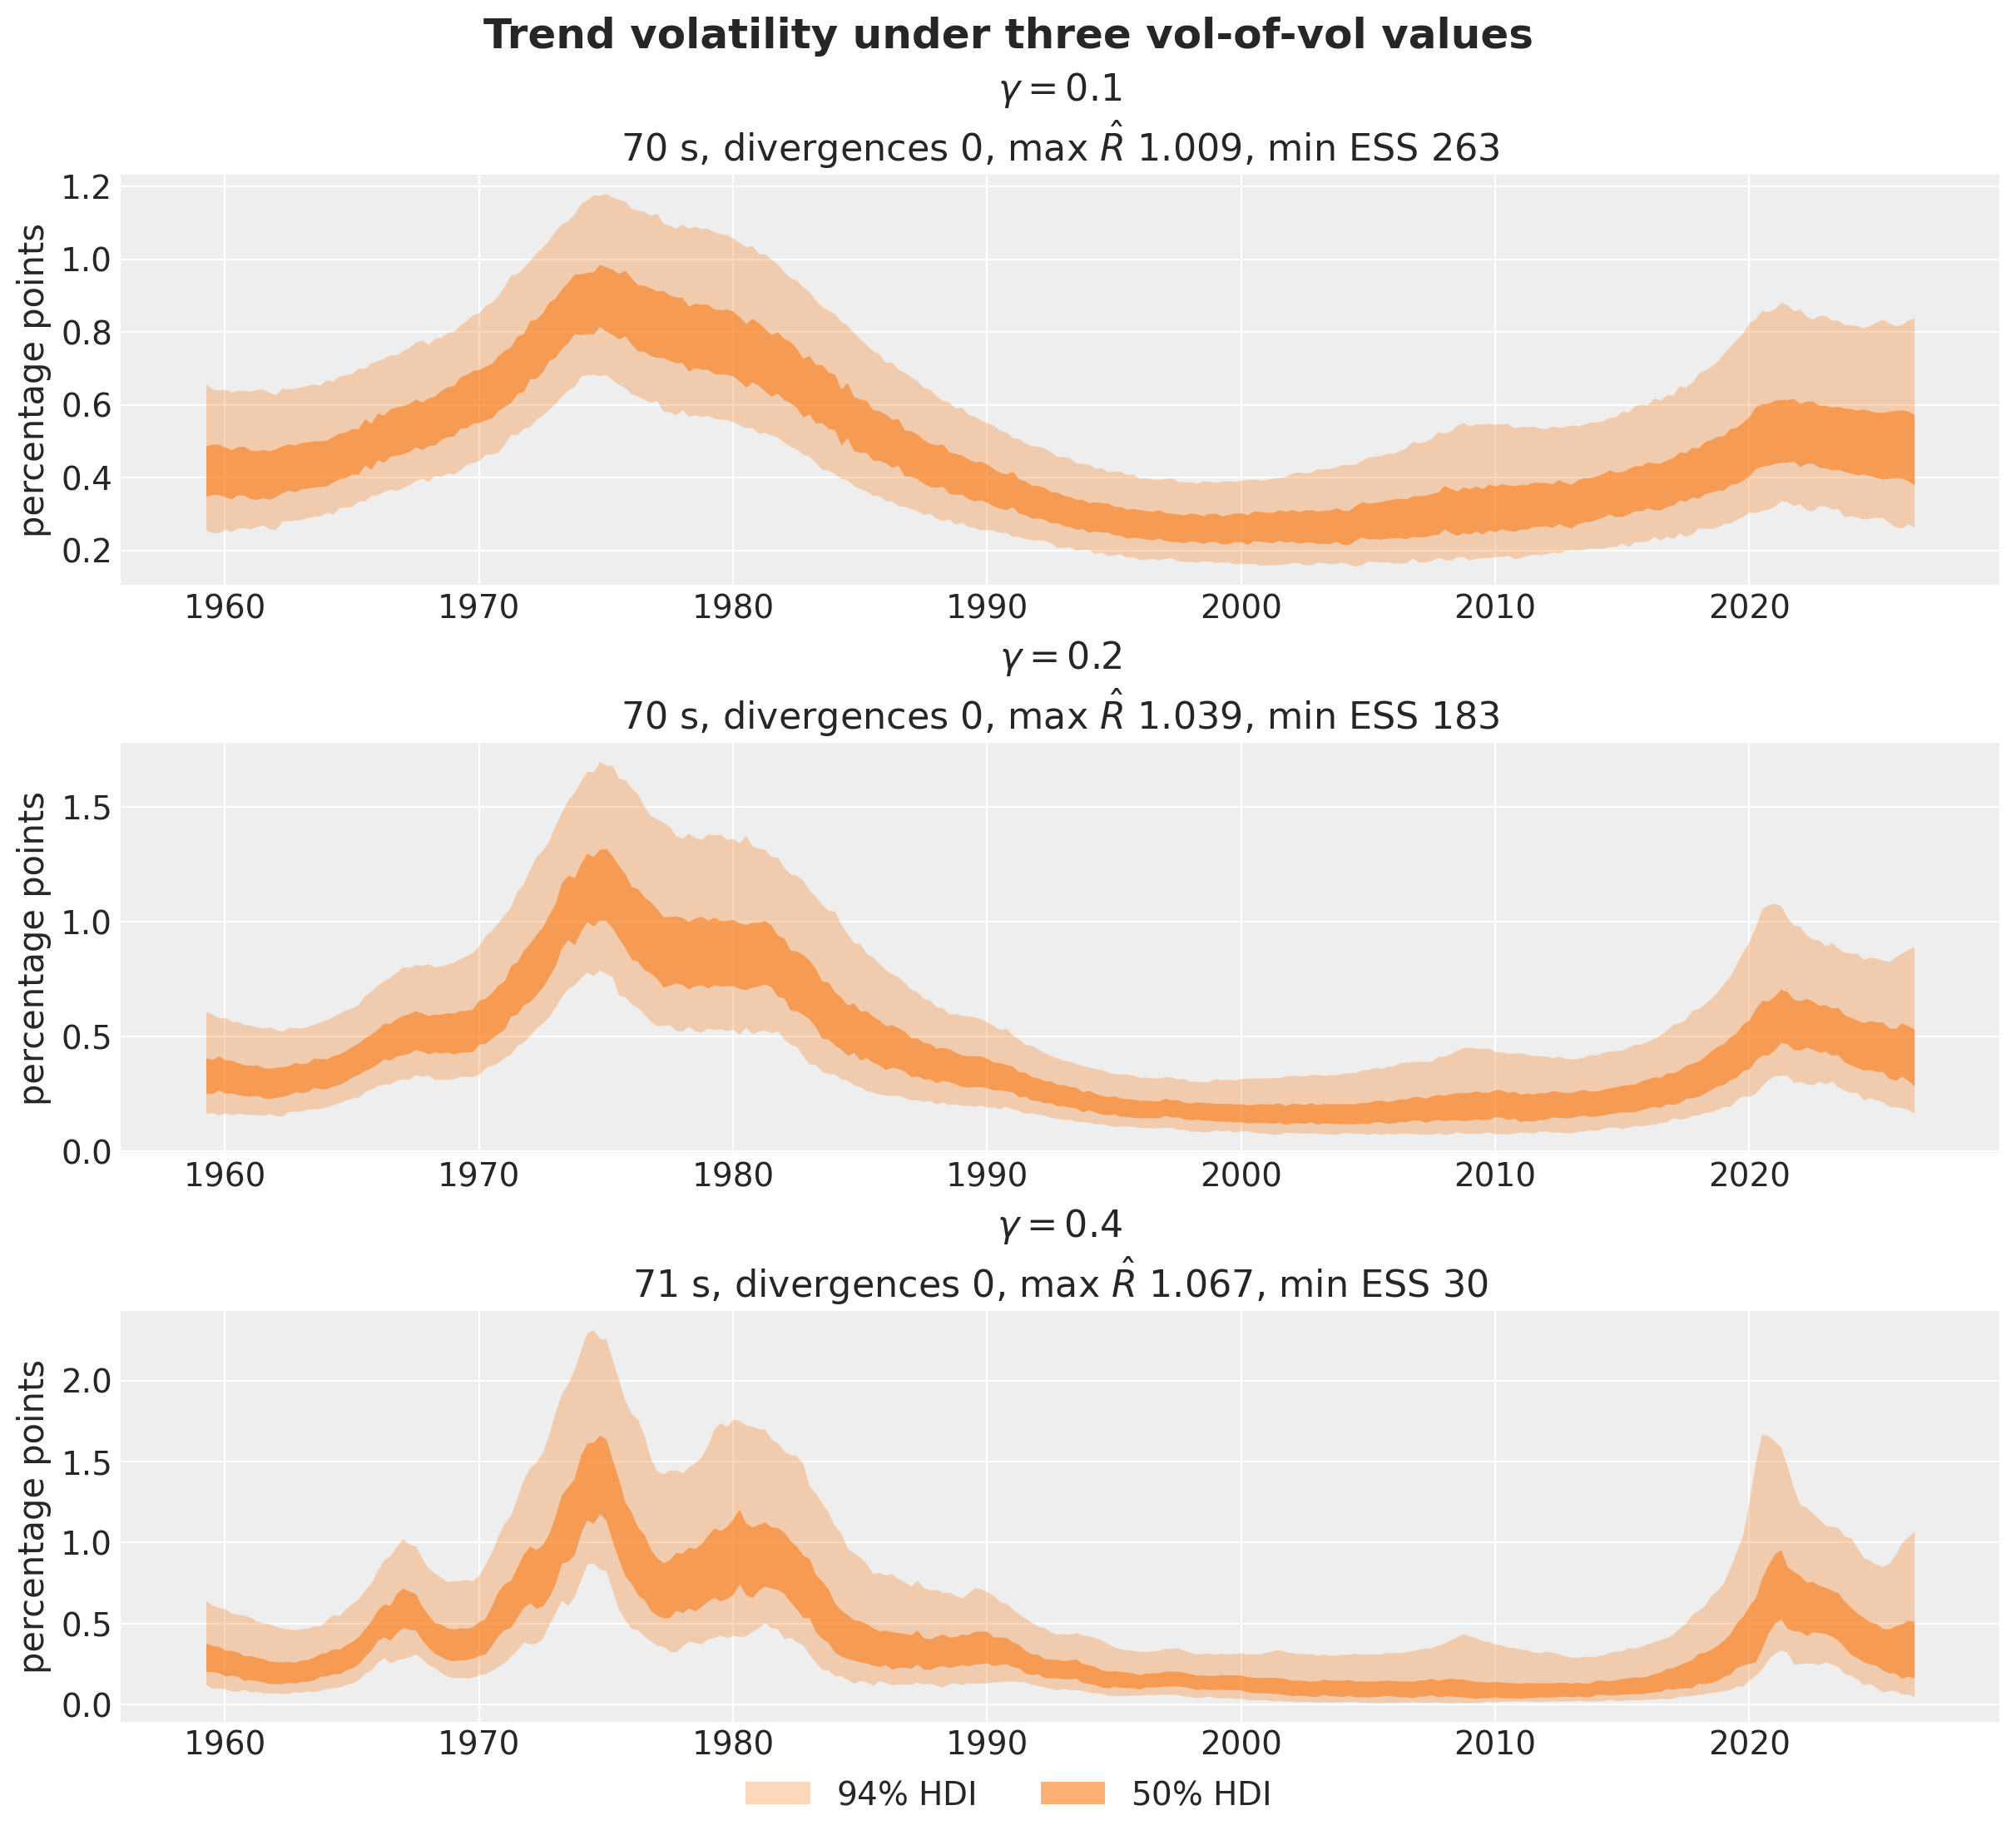

In [26]:
VOL_OF_VOL_GRID = (0.1, 0.2, 0.4)
grid_fits: dict[float, tuple[MCMC, float]] = {0.1: (mcmc, seconds)}

for gamma in VOL_OF_VOL_GRID:
    if gamma not in grid_fits:
        rng_key, key_fit = random.split(rng_key)
        grid_fits[gamma] = fit_nuts(
            key_fit,
            make_trend_inflation_model(num_measures, vol_of_vol=gamma, common_transitory=True),
            rates,
            num_warmup=FULL_WARMUP,
            num_samples=FULL_SAMPLES,
        )

grid_draws = np.concatenate(
    [np.asarray(grid_fits[gamma][0].get_samples()["trend_vol"]) for gamma in VOL_OF_VOL_GRID],
    axis=-1,
)  # (samples, quarters, 3): one column per gamma
pc, band_handles = plot_bands(
    grid_draws,
    date_num,
    [rf"$\gamma = {gamma}$" for gamma in VOL_OF_VOL_GRID],
    color="C1",
    figsize=(12, 11),
)
fig = pc.viz["figure"].item()

for ax, gamma in zip(fig.axes, VOL_OF_VOL_GRID, strict=True):
    ax.set(title=fit_title(rf"$\gamma = {gamma}$", *grid_fits[gamma]), ylabel="percentage points")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle("Trend volatility under three vol-of-vol values", **TITLE);

The three fits agree on the shape of the trend volatility and disagree on how fast it moves:

- With $\gamma = 0.1$, the value of this notebook, the path runs from $0.92$ in 1975Q1 down to $0.27$ in 1999Q1 and ends at $0.54$.
- With $\gamma = 0.2$ the range is $0.19$ to $1.22$ and the path ends at $0.51$, but the chains agree less: the largest $\hat{R}$ is $1.039$.
- With $\gamma = 0.4$ the peaks are sharper, up to $1.55$ in 1974Q2, and the fit does not converge: the largest $\hat{R}$ is $1.067$ and the smallest ESS $30$.

The volatility at the end of the sample, which sets the width of the forecast bands, is about the same under the three values. A larger $\gamma$ lets the volatility move faster and makes the posterior harder to sample, and only $\gamma = 0.1$ meets the $1.01$ guideline for $\hat{R}$.

The model choices of this notebook come from fits that it does not re-run, to keep it short. Each one is a full fit of the same data with the same sampler settings ($1{,}000$ warmup and $1{,}000$ draws in four chains, target $0.95$, $\gamma = 0.1$ unless $\gamma$ is learned), and the next figure shows their literal scores:

- M3 and M2 without the floor $\sigma_{\min}$.
- M3 with a free loading per measure on the common shock (the loading of PCE fixed at one).
- M3 with a learned $\gamma \sim \text{LogNormal}(\log 0.1, 0.3)$, a prior whose central $94\%$ range is $0.057$ to $0.18$.
- The same learned $\gamma$ with `time_reparam(model, "dct")`, which rotates the standardized steps of every random walk with the discrete cosine transform.
- The same with a tighter prior, $\gamma \sim \text{LogNormal}(\log 0.1, 0.1)$.
- The same with centered log-variance steps, $h_t - h_{t-1} \sim \text{Normal}(0, \gamma)$ sampled directly instead of $\gamma u_t$.

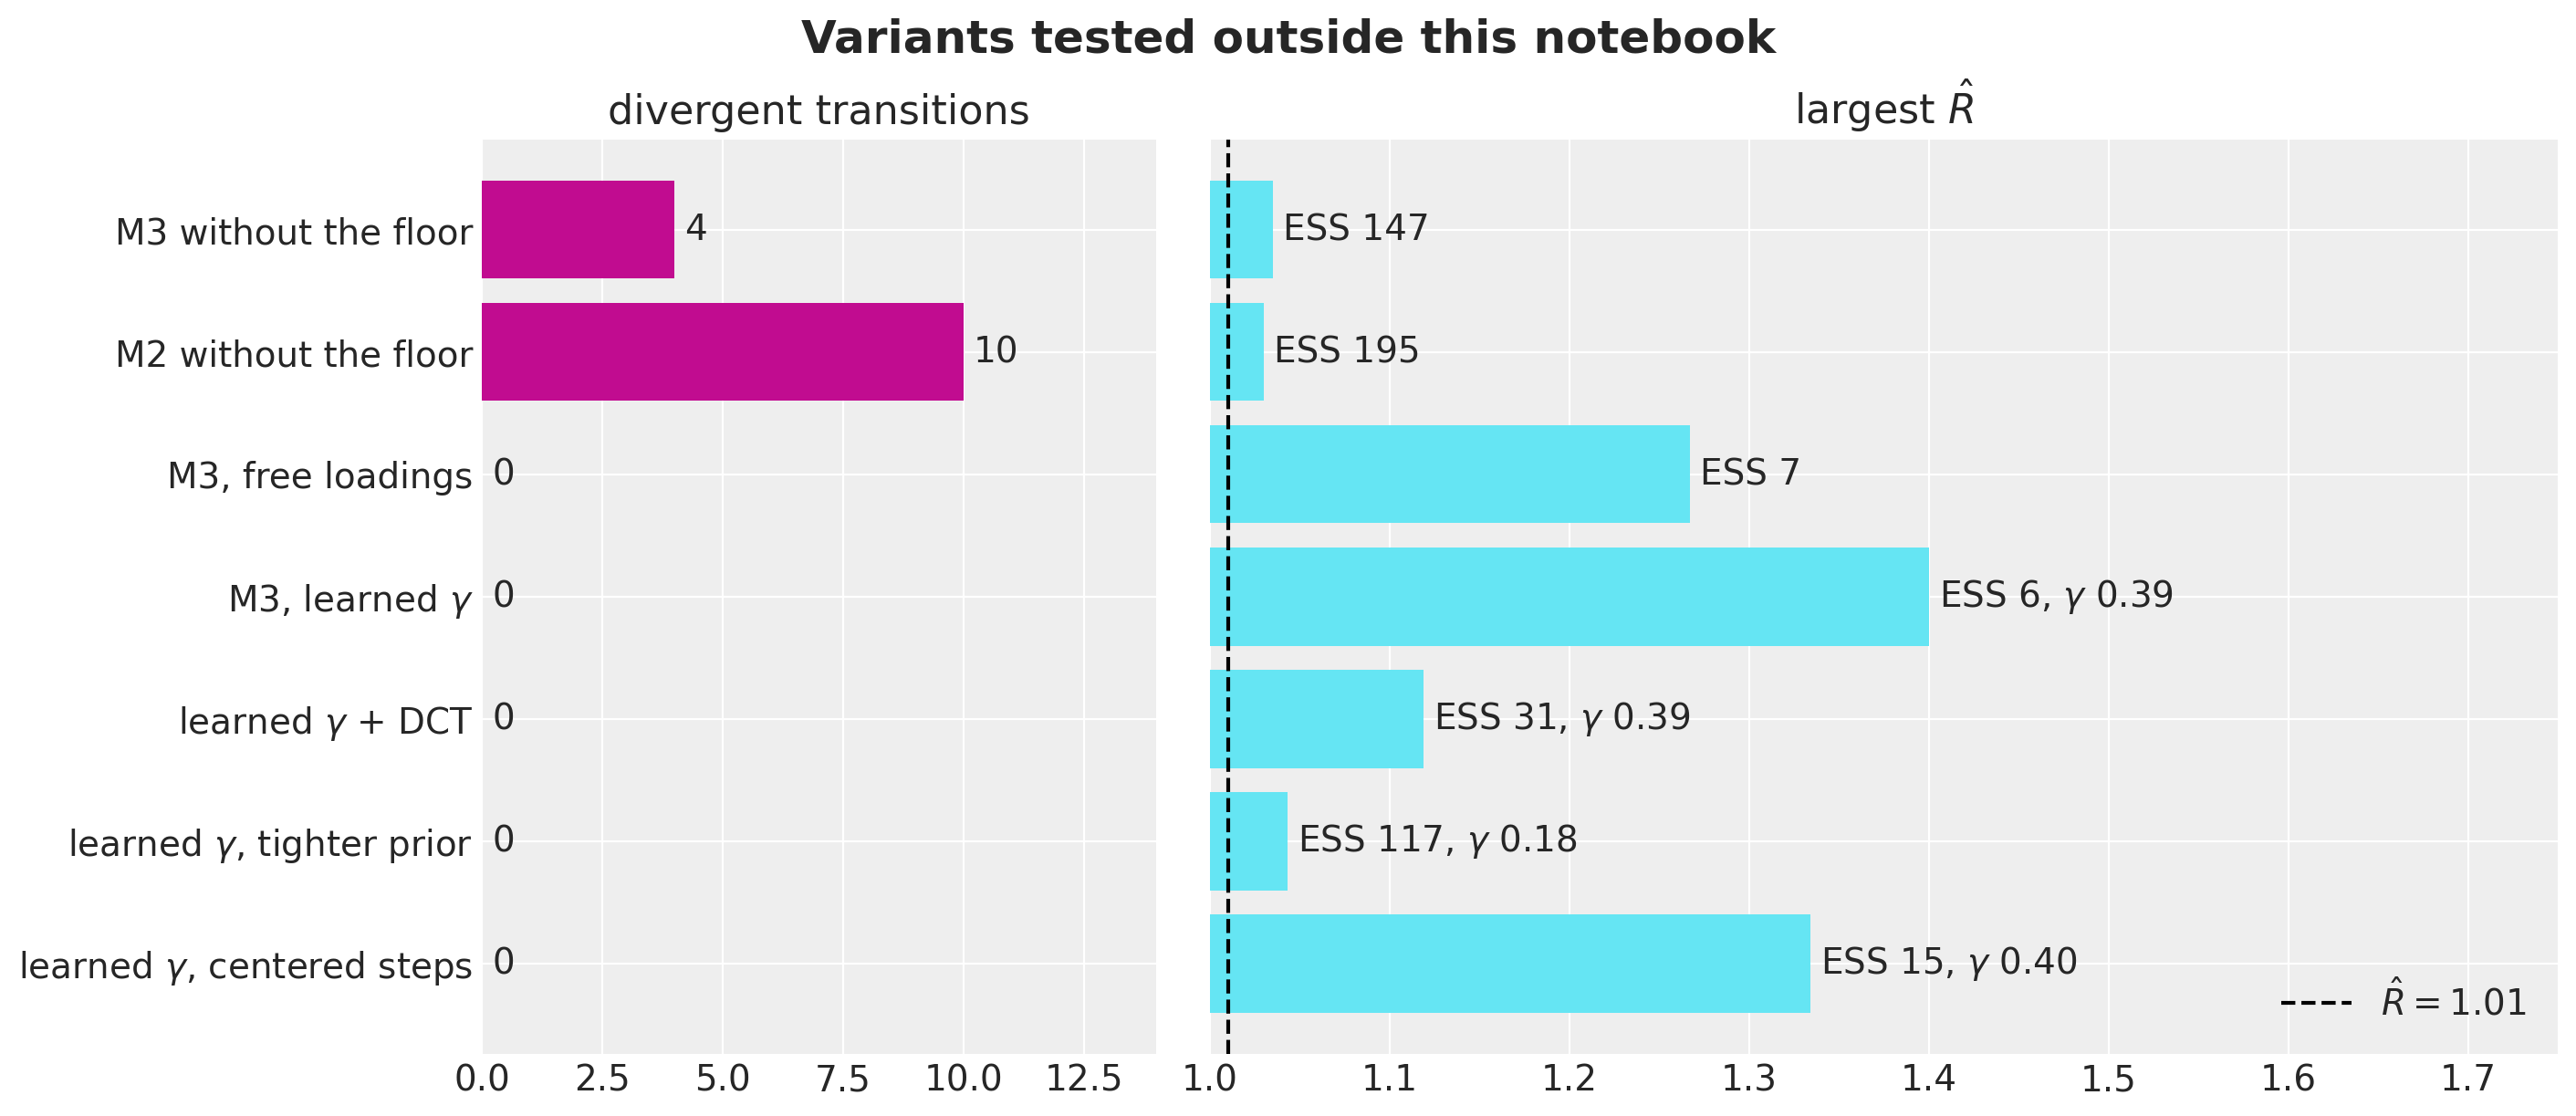

In [27]:
# label: (divergences, max R-hat, min ESS, posterior mean of gamma or None); separate runs,
# not re-run here, with the diagnostics of `fit_title`.
VARIANT_RUNS = {
    "M3 without the floor": (4, 1.035, 147, None),
    "M2 without the floor": (10, 1.03, 195, None),
    "M3, free loadings": (0, 1.267, 7, None),
    r"M3, learned $\gamma$": (0, 1.40, 6, 0.39),
    r"learned $\gamma$ + DCT": (0, 1.119, 31, 0.39),
    r"learned $\gamma$, tighter prior": (0, 1.043, 117, 0.18),
    r"learned $\gamma$, centered steps": (0, 1.334, 15, 0.40),
}
variant_labels = list(VARIANT_RUNS)

fig, axes = plt.subplots(
    nrows=1, ncols=2, sharey=True, figsize=(14, 6), layout="constrained", width_ratios=[1, 2]
)
bars = axes[0].barh(variant_labels, [run[0] for run in VARIANT_RUNS.values()], color="C3")
axes[0].bar_label(bars, padding=4, fontsize=14)
axes[0].set(title="divergent transitions", xlim=(0, 14))
bars = axes[1].barh(variant_labels, [run[1] for run in VARIANT_RUNS.values()], color="C5")
axes[1].bar_label(
    bars,
    labels=[
        f"ESS {ess}" if gamma is None else rf"ESS {ess}, $\gamma$ {gamma:.2f}"
        for _, _, ess, gamma in VARIANT_RUNS.values()
    ],
    padding=4,
    fontsize=14,
)
axes[1].axvline(1.01, color="black", linestyle="--", label=r"$\hat{R} = 1.01$")
axes[1].legend(loc="lower right")
axes[1].set(title=r"largest $\hat{R}$", xlim=(1.0, 1.75))
axes[0].invert_yaxis()
fig.suptitle("Variants tested outside this notebook", **TITLE);

The figure backs the two design choices and answers whether $\gamma$ can be learned:

- Without the floor, M3 has $4$ divergent transitions and M2 $10$. With the floor, the full fits of this notebook have none.
- Free loadings on the common shock give no divergent transitions, but the chains disagree (largest $\hat{R}$ $1.27$, ESS $7$), so every loading is fixed at one.
- A learned $\gamma$ goes to about $0.4$ and does not converge (largest $\hat{R}$ $1.40$, ESS $6$). `time_reparam(model, "dct")` brings the largest $\hat{R}$ down to $1.12$, but the ESS rises only to $31$ and the fit takes about two and a half minutes. Centered log-variance steps do not help ($1.33$). The tighter prior gives the best diagnostics, $1.04$, because the prior holds $\gamma$ down at $0.18$, between its center of $0.1$ and the $0.4$ the data push toward.

The data push a shared $\gamma$ toward $0.4$, where the fit with $\gamma$ fixed at $0.4$ does not converge either. The difficulty is the posterior of the volatility paths at large $\gamma$, and none of the three changes removes it.

## Cost

The full fits and the backtests are the expensive parts of the notebook. The figure collects their wall times.

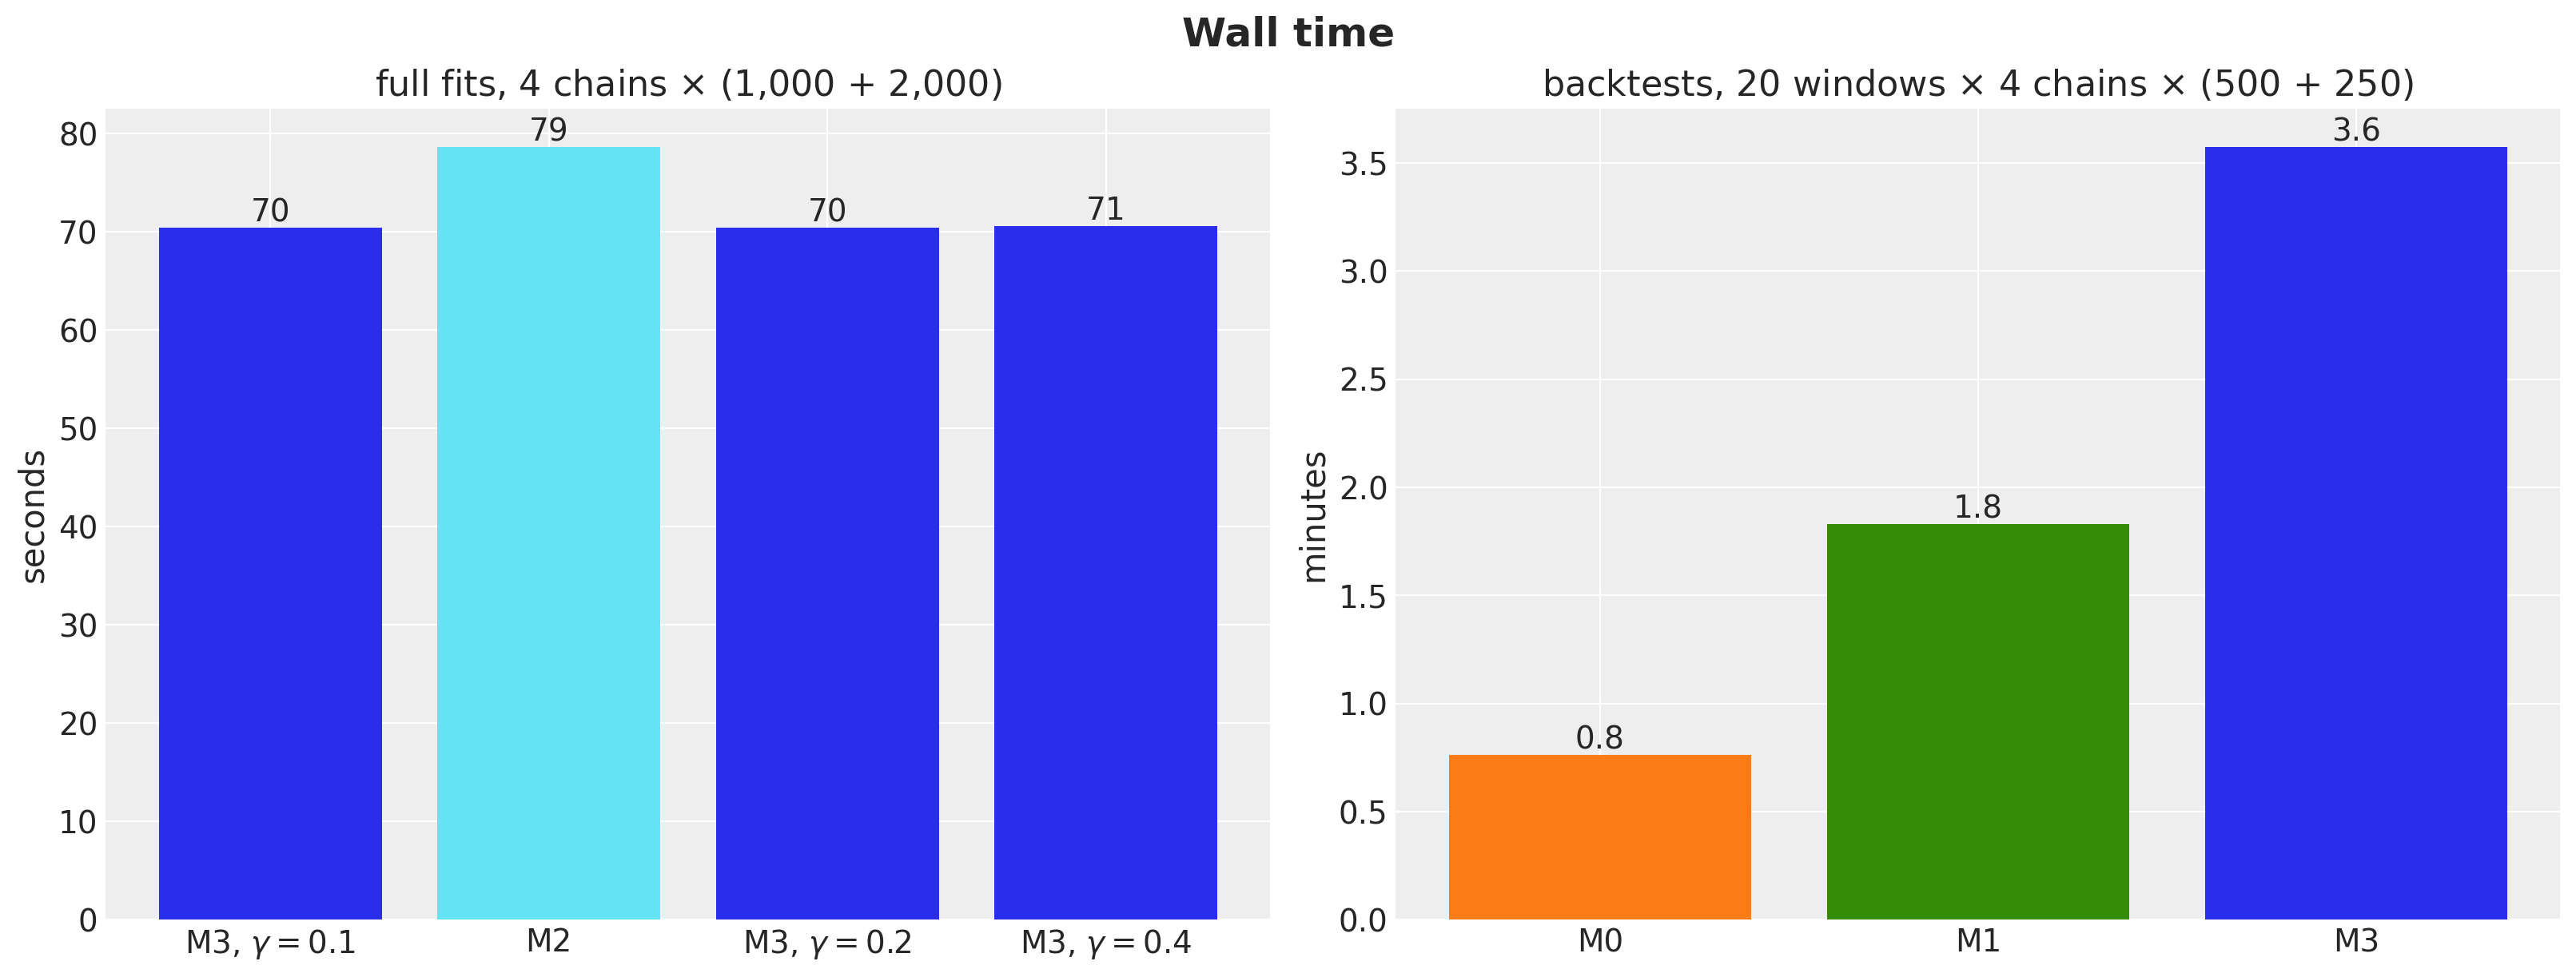

In [28]:
full_fit_seconds = {
    r"M3, $\gamma = 0.1$": seconds,
    "M2": seconds_m2,
    r"M3, $\gamma = 0.2$": grid_fits[0.2][1],
    r"M3, $\gamma = 0.4$": grid_fits[0.4][1],
}
backtest_minutes = {
    label: sum(result.walltime for result in results) / 60
    for label, results in backtest_results.items()
}

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), layout="constrained")
bars = axes[0].bar(
    list(full_fit_seconds), list(full_fit_seconds.values()), color=["C0", "C5", "C0", "C0"]
)
axes[0].bar_label(bars, fmt="%.0f", fontsize=14)
axes[0].set(title=r"full fits, 4 chains $\times$ (1,000 + 2,000)", ylabel="seconds")
bars = axes[1].bar(
    list(backtest_minutes),
    list(backtest_minutes.values()),
    color=[RUNG_COLORS[label] for label in backtest_minutes],
)
axes[1].bar_label(bars, fmt="%.1f", fontsize=14)
axes[1].set(
    title=r"backtests, 20 windows $\times$ 4 chains $\times$ (500 + 250)", ylabel="minutes"
)
fig.suptitle("Wall time", **TITLE);

A full fit, four chains with $1{,}000$ warmup and $2{,}000$ draws, takes $70$ to $79$ seconds; M2 is the slowest. The backtests take $0.8$ minutes (M0), $1.8$ (M1) and $3.6$ (M3) for 20 windows each, so the fits and backtests take about $11$ minutes in total.

## Discussion

What the results say about modeling these four measures:

- With independent gaps (M2), the trend of a four-measure model follows core PCE quarter by quarter: since 1995 its quarterly changes have a correlation of $0.96$ with those of core PCE, it falls below zero in 2020Q2, and the model implies a lag-1 autocorrelation of quarterly core PCE changes of $-0.18$ against $-0.39$ in the data. One white-noise shock with the same loading on every measure lets the four measures share a transitory quarter: the trend of M3 changes by $0.27$ points per quarter since 1995 instead of $0.67$, and the implied autocorrelation is $-0.37$.
- The floor under the gap volatilities removes the divergent transitions: the fits without it had $10$ (M2) and $4$ (M3), the fits with it have none.
- The better trend does not give a better forecast of core PCE in this backtest. M1, core PCE alone with stochastic volatility, has the best average score on every metric and beats M0 on the CRPS in 16 of the 20 windows. M3 is $0.047 \pm 0.045$ CRPS behind M1, the one difference larger than two standard errors, and it does worst at the 1985, 1987 and 1991 origins.
- The $94\%$ intervals of all three models are calibrated. The $50\%$ intervals of M3 are on target, those of M1 slightly too wide and those of M0 too wide.

Open weaknesses of the model:

- $\gamma$ is fixed. A learned $\gamma$ goes to about $0.4$, where the sampler does not converge with or without a reparameterization, and $0.1$ is the only value of the three we fit that meets the $\hat{R}$ guideline. The volatility at the end of the sample is about the same under $0.1$, $0.2$ and $0.4$.
- There is one common shock with unit loadings. The 2008Q4 energy collapse moved the headline measures far more than the core measures, so it stays in two independent headline gaps. Time-varying loadings on the common transitory shock, as in Stock and Watson (2016), would let the energy part change over time; free loadings on one shock did not converge here.
- The offsets are constant. The CPI to PCE wedge has moved with the index methodologies (rental equivalence entered the CPI in 1983), so the constant offset puts the high CPI readings of the years before 1983 partly into the trend. This is one candidate reason, not tested here, for the poor scores of M3 at the 1985, 1987 and 1991 origins, whose training samples are mostly years before 1983.
- The October 2025 prices are filled in and the rents of that month were carried forward. The CPI and PCE series carry the geometric-mean month in 2025Q4, and their rent components count no change for October until the April 2026 index, so the rates of 2025Q4 to 2026Q2 do not follow the monthly path a full collection would have produced.

Fairness notes on the evaluation:

- No information about the forecast horizon enters any model: the windows expand to the origin and the forecast uses the posterior at the origin only.
- The data are the revised series as published on 2026-11-08, not the vintages a forecaster had at each origin. Revised data make every model and the benchmark look better than they would have in real time.
- The model choices (the common shock, the floor, $\gamma$) were made on the full sample, so the backtest scores of M3 are not a pure out-of-sample test of its design.
- The 20 windows do not overlap, but the 2021Q1 window carries a large share of every mean.

## References

- Atkeson, A., Ohanian, L. E. (2001). [*Are Phillips curves useful for forecasting inflation?*](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation). Federal Reserve Bank of Minneapolis Quarterly Review, 25(1).
- Gneiting, T., Raftery, A. E. (2007). [*Strictly proper scoring rules, prediction, and estimation*](https://doi.org/10.1198/016214506000001437). Journal of the American Statistical Association, 102(477).
- Mertens, E. (2016). [*Measuring the level and uncertainty of trend inflation*](https://doi.org/10.1162/REST_a_00549). Review of Economics and Statistics, 98(5).
- Stock, J. H., Watson, M. W. (2007). [*Why has U.S. inflation become harder to forecast?*](https://doi.org/10.1111/j.1538-4616.2007.00014.x). Journal of Money, Credit and Banking, 39(s1).
- Stock, J. H., Watson, M. W. (2016). [*Core inflation and trend inflation*](https://doi.org/10.1162/REST_a_00608). Review of Economics and Statistics, 98(4).
- Data: U.S. Bureau of Labor Statistics, [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) and [CPILFESL](https://fred.stlouisfed.org/series/CPILFESL); U.S. Bureau of Economic Analysis, [PCEPI](https://fred.stlouisfed.org/series/PCEPI) and [PCEPILFE](https://fred.stlouisfed.org/series/PCEPILFE); all retrieved from FRED, Federal Reserve Bank of St. Louis, on 2026-11-08.
- Related examples: [vector autoregression](var.html), [univariate forecasting](forecasting_univariate.html).